# Sales prediction using Python
**Task 4 · Advertising analytics and budget scenarios**

## 1. Problem and objectives
Estimate sales for comparable markets given budgets for television, radio and newspaper advertising. The analysis validates the original data, compares regression pipelines, estimates adjusted channel associations and scores plausible budget changes.

The dataset is cross-sectional. Each row describes one market. Segment and campaign-date fields are absent, so the results concern proposed budgets for comparable markets. The pipeline produces a cleaned CSV, trained model, holdout predictions, charts, a PDF and inputs for the Streamlit simulator.

## 2. Dataset source and measurement
The analysis uses the [Kaggle Advertising CSV](https://www.kaggle.com/datasets/bumba5341/advertisingcsv). Its numeric rows match the [official ISLR companion CSV](https://www.statlearning.com/s/Advertising.csv) after aligning capitalization. The textbook's [Figure 2.1](https://www.statlearning.com/s/ISLRSeventhPrinting.pdf) documents advertising in thousands of dollars and sales in thousands of units. The unnamed sequential field is an observation identifier.

In [1]:
from pathlib import Path
import json
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / 'main.py').is_file())
sys.path.insert(0, str(root))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src import CHANNELS
from src.advertising_analysis import analyze_channels
from src.data_cleaning import clean_data
from src.data_loader import ensure_dataset, load_raw
from src.exploratory_analysis import describe_data
from src.feature_engineering import make_features
from src.findings import summarize
from src.model_evaluation import diagnose_predictions, evaluate_models, holdout_predictions
from src.model_training import split_data, train_models
from src.scenario_analysis import budget_reference, response_grid, sample_scenarios

raw_path = ensure_dataset(root / 'data' / 'raw')
metadata = json.loads(raw_path.with_name('dataset_metadata.json').read_text(encoding='utf-8'))
raw = load_raw(raw_path)
display(pd.Series(metadata, name='Original Kaggle file').to_frame())
display(raw.head(), raw.tail())
display(raw.dtypes.rename('dtype').to_frame())

,Original Kaggle file
source_url,https://www.kaggle.com/datasets/bumba5341/adve...
dataset_slug,bumba5341/advertisingcsv
download_method,Official Kaggle datasets download API (ZIP)
download_date,2026-11-09
filename,Advertising.csv
size_bytes,5166
sha256,69104adc017e75d7019f61fe66ca2eb4ab014ee6f2a9b3...
observations,200
columns,"[Unnamed: 0, TV, Radio, Newspaper, Sales]"
unit_reference,https://www.statlearning.com/s/ISLRSeventhPrin...


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


,Unnamed: 0,TV,Radio,Newspaper,Sales
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4


,dtype
Unnamed: 0,int64
TV,float64
Radio,float64
Newspaper,float64
Sales,float64


## 3. Cleaning and data quality
Normalize column names and validate the four required numeric fields. Exclude invalid or missing values and exact duplicate measurement rows. The IQR check flags extremes for review while preserving the observations. The raw download stays separate from the cleaned data.

In [2]:
clean, quality, missing_patterns = clean_data(raw)
data, eda = describe_data(raw, clean)
display(eda['raw_profile'], eda['data_dictionary'])
display(quality, missing_patterns)

,field,dtype,unique,missing,categorical
0,Unnamed: 0,int64,200,0,False
1,TV,float64,190,0,False
2,Radio,float64,167,0,False
3,Newspaper,float64,172,0,False
4,Sales,float64,121,0,False


,field,role,description,unit
0,TV,Predictor,Television advertising expenditure,$ thousands
1,Radio,Predictor,Radio advertising expenditure,$ thousands
2,Newspaper,Predictor,Newspaper advertising expenditure,$ thousands
3,Sales,Target,Product sales across markets,thousand units
4,Total,Derived,Sum of the three channel budgets,$ thousands
5,*_share,Derived,"Channel budget divided by total, or zero for a...",fraction
6,Unnamed: 0,Excluded,Sequential row identifier,ordinal


,scope,missing,nonnumeric,infinite,negative,iqr_outliers_retained,lower_iqr_fence,upper_iqr_fence,input_rows,invalid_rows_removed,duplicate_rows_removed,output_rows,excluded_index_field
0,TV,0,0,0,0,0,-142.3000,435.5000,NaN,NaN,NaN,NaN,NaN
1,Radio,0,0,0,0,0,-29.8500,76.3500,NaN,NaN,NaN,NaN,NaN
2,Newspaper,0,0,0,0,2,-35.7750,93.6250,NaN,NaN,NaN,NaN,NaN
3,Sales,0,0,0,0,0,-0.1625,27.9375,NaN,NaN,NaN,NaN,NaN
4,All rows,0,0,0,0,2,NaN,NaN,200.0,0.0,0.0,200.0,Unnamed: 0


,missing_fields,rows
0,Complete,200


## 4. Exploratory analysis
Sales averages about 14 thousand units. TV budgets show the broadest spread, while Newspaper spending is more right-skewed. The Shapiro-Wilk checks quantify departures from a normal distribution in these variables. OLS does not require normally distributed predictors. The scatterplots describe raw associations across markets, and the multivariable analysis below accounts for the other channels.

,field,count,mean,std,min,25%,50%,75%,max,skew,excess_kurtosis,shapiro_p
0,TV,200.0,147.0425,85.8542,0.7,74.375,149.75,218.825,296.4,-0.0699,-1.2265,0.0000
1,Radio,200.0,23.2640,14.8468,0.0,9.975,22.90,36.525,49.6,0.0942,-1.2604,0.0000
2,Newspaper,200.0,30.5540,21.7786,0.3,12.750,25.75,45.100,114.0,0.8947,0.6495,0.0000
3,Total,200.0,200.8605,92.9852,11.7,123.550,207.35,281.125,433.6,0.0495,-0.9268,0.0008
4,Sales,200.0,14.0225,5.2175,1.6,10.375,12.90,17.400,27.0,0.4076,-0.4089,0.0017


,field,TV,Radio,Newspaper,Total,Sales
0,TV,1.000,0.055,0.057,0.945,0.782
1,Radio,0.055,1.000,0.354,0.293,0.576
2,Newspaper,0.057,0.354,1.000,0.343,0.228
3,Total,0.945,0.293,0.343,1.000,0.868
4,Sales,0.782,0.576,0.228,0.868,1.000


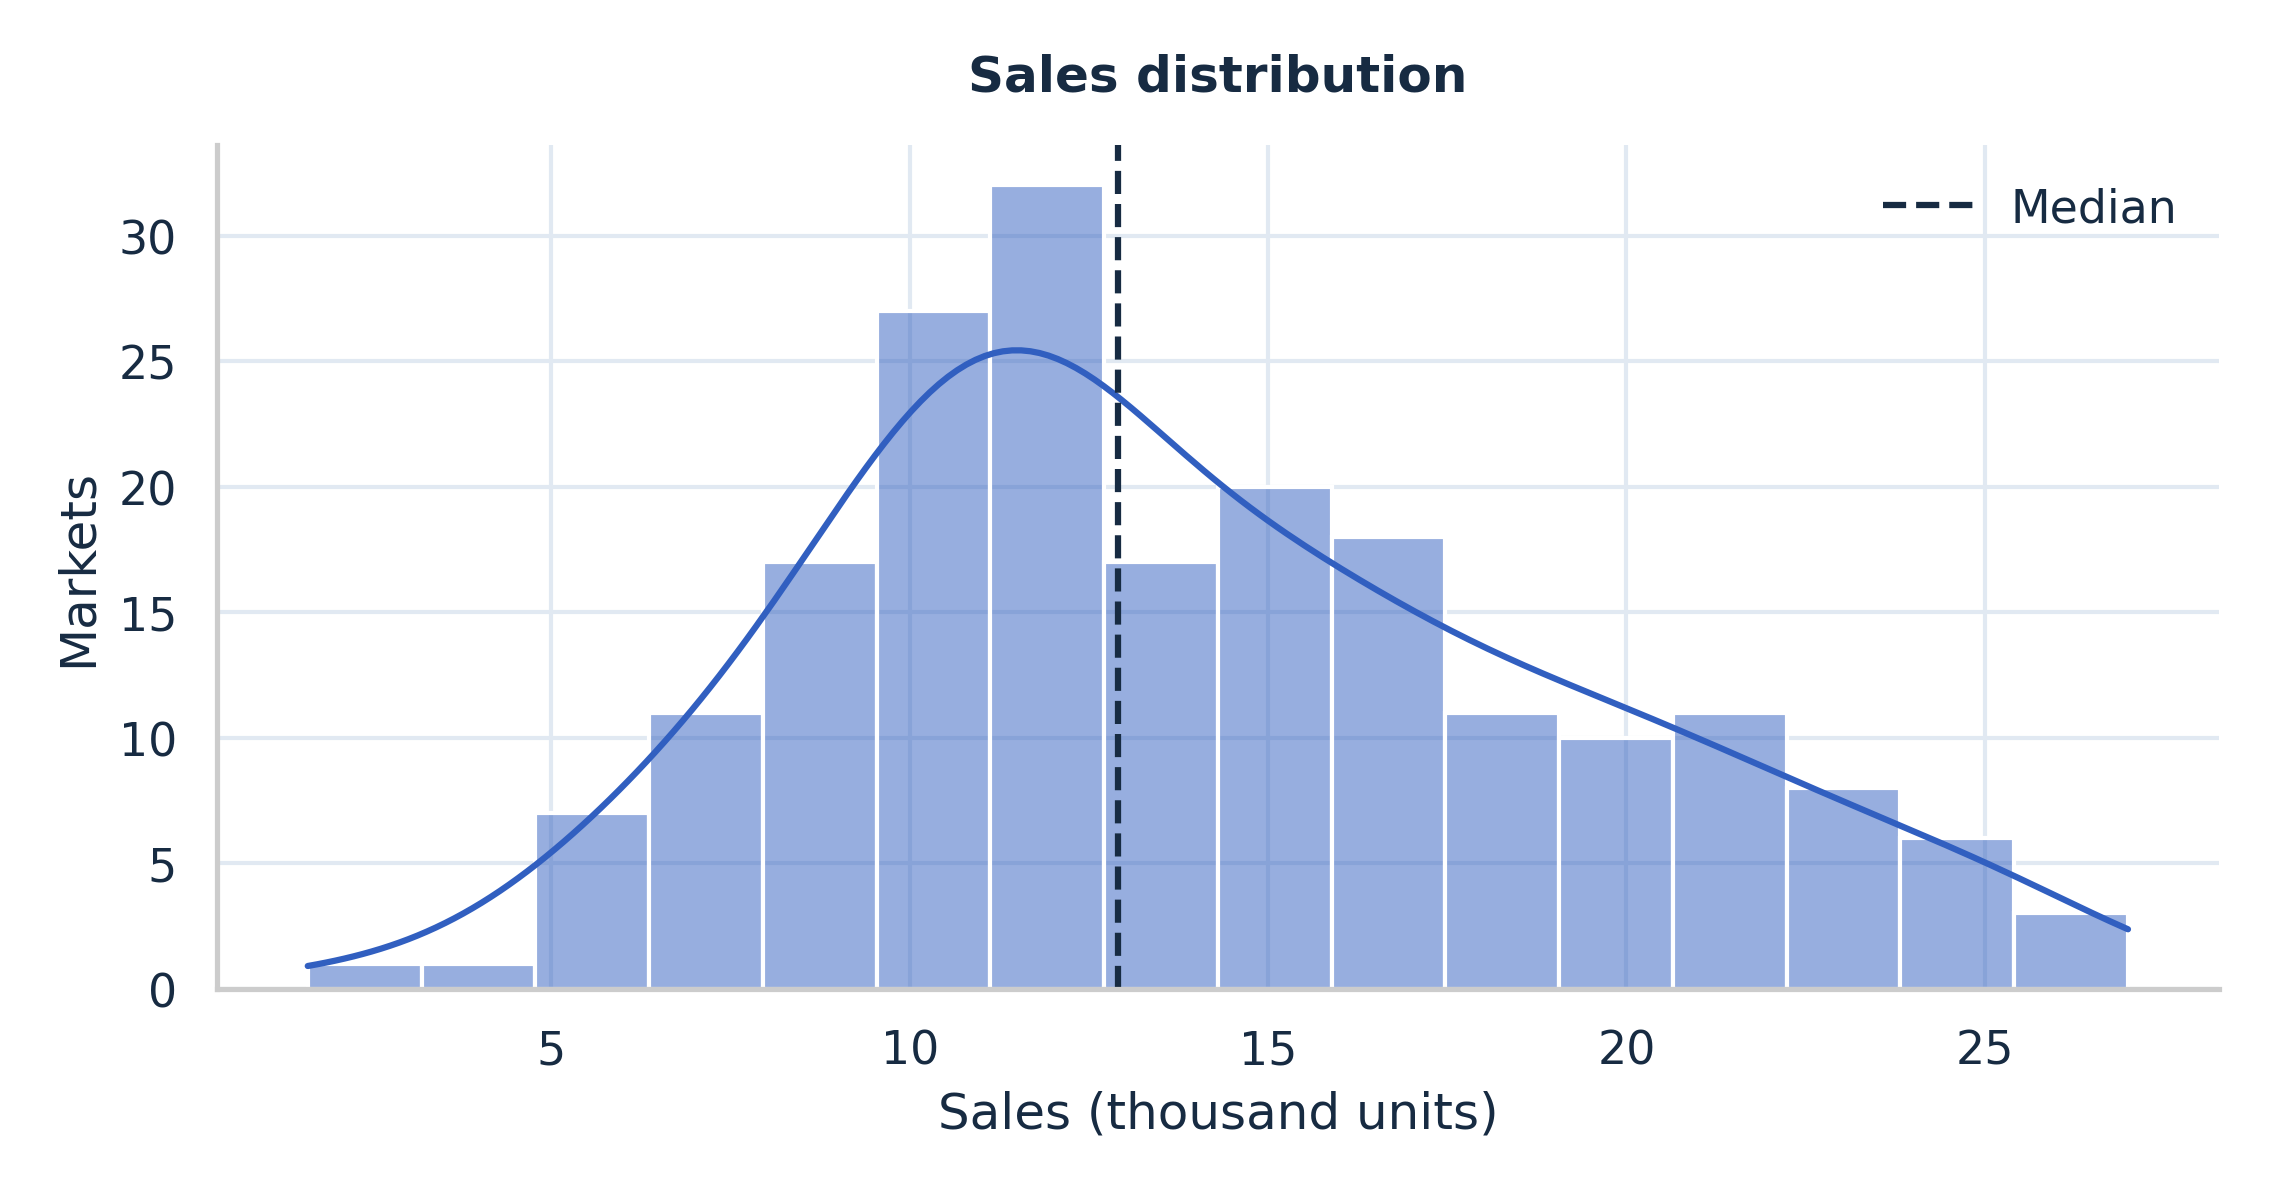

Sales averages 14.02 with a median of 12.90. Sample skewness is +0.41. The dashed line marks the median.

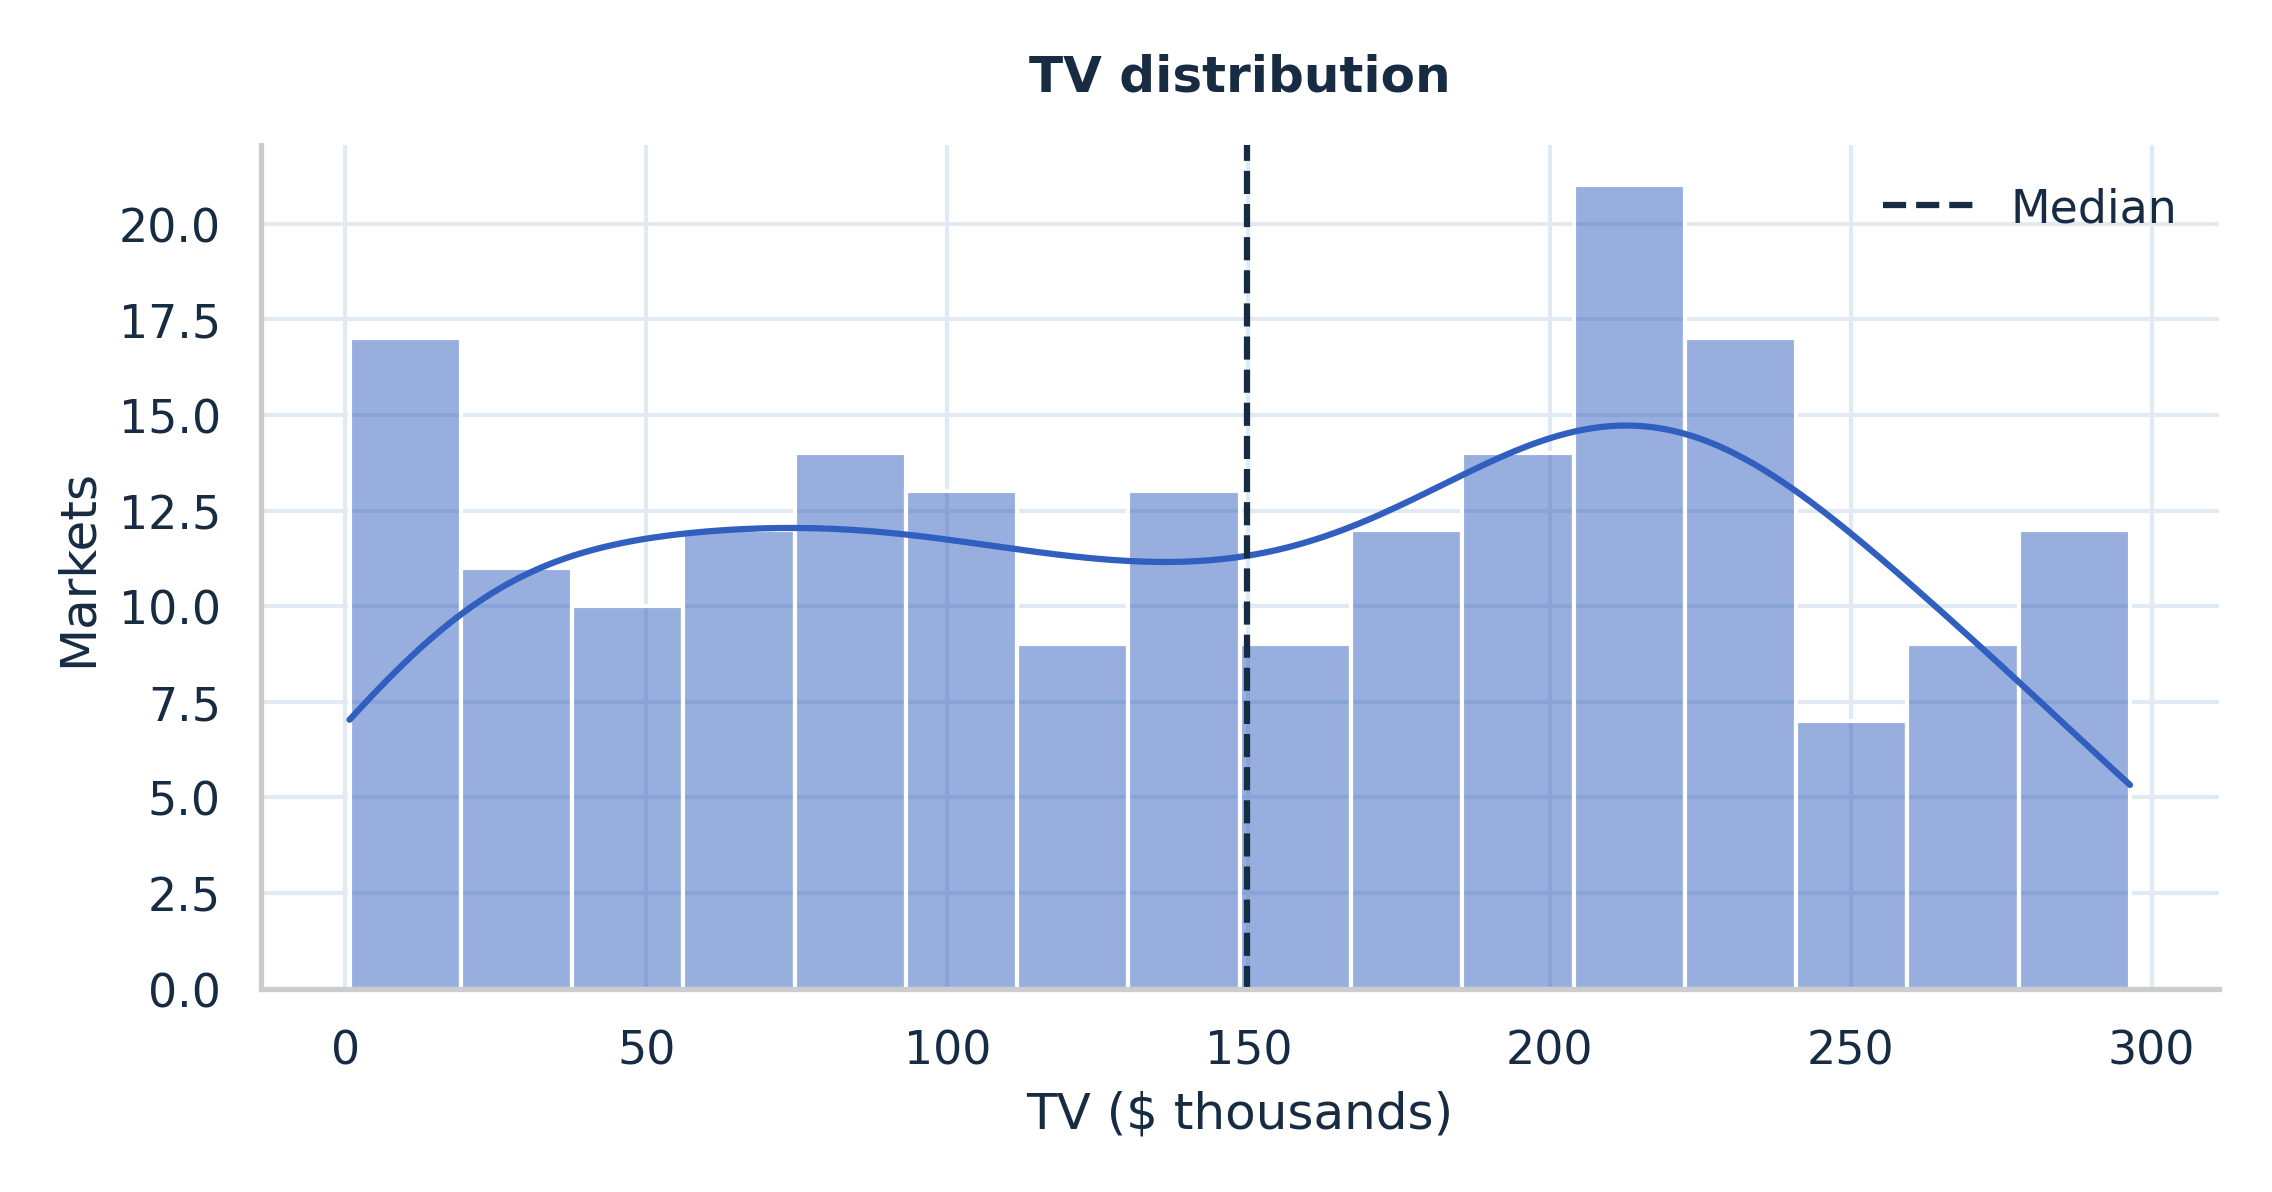

TV averages 147.04 with a median of 149.75. Sample skewness is -0.07. The dashed line marks the median.

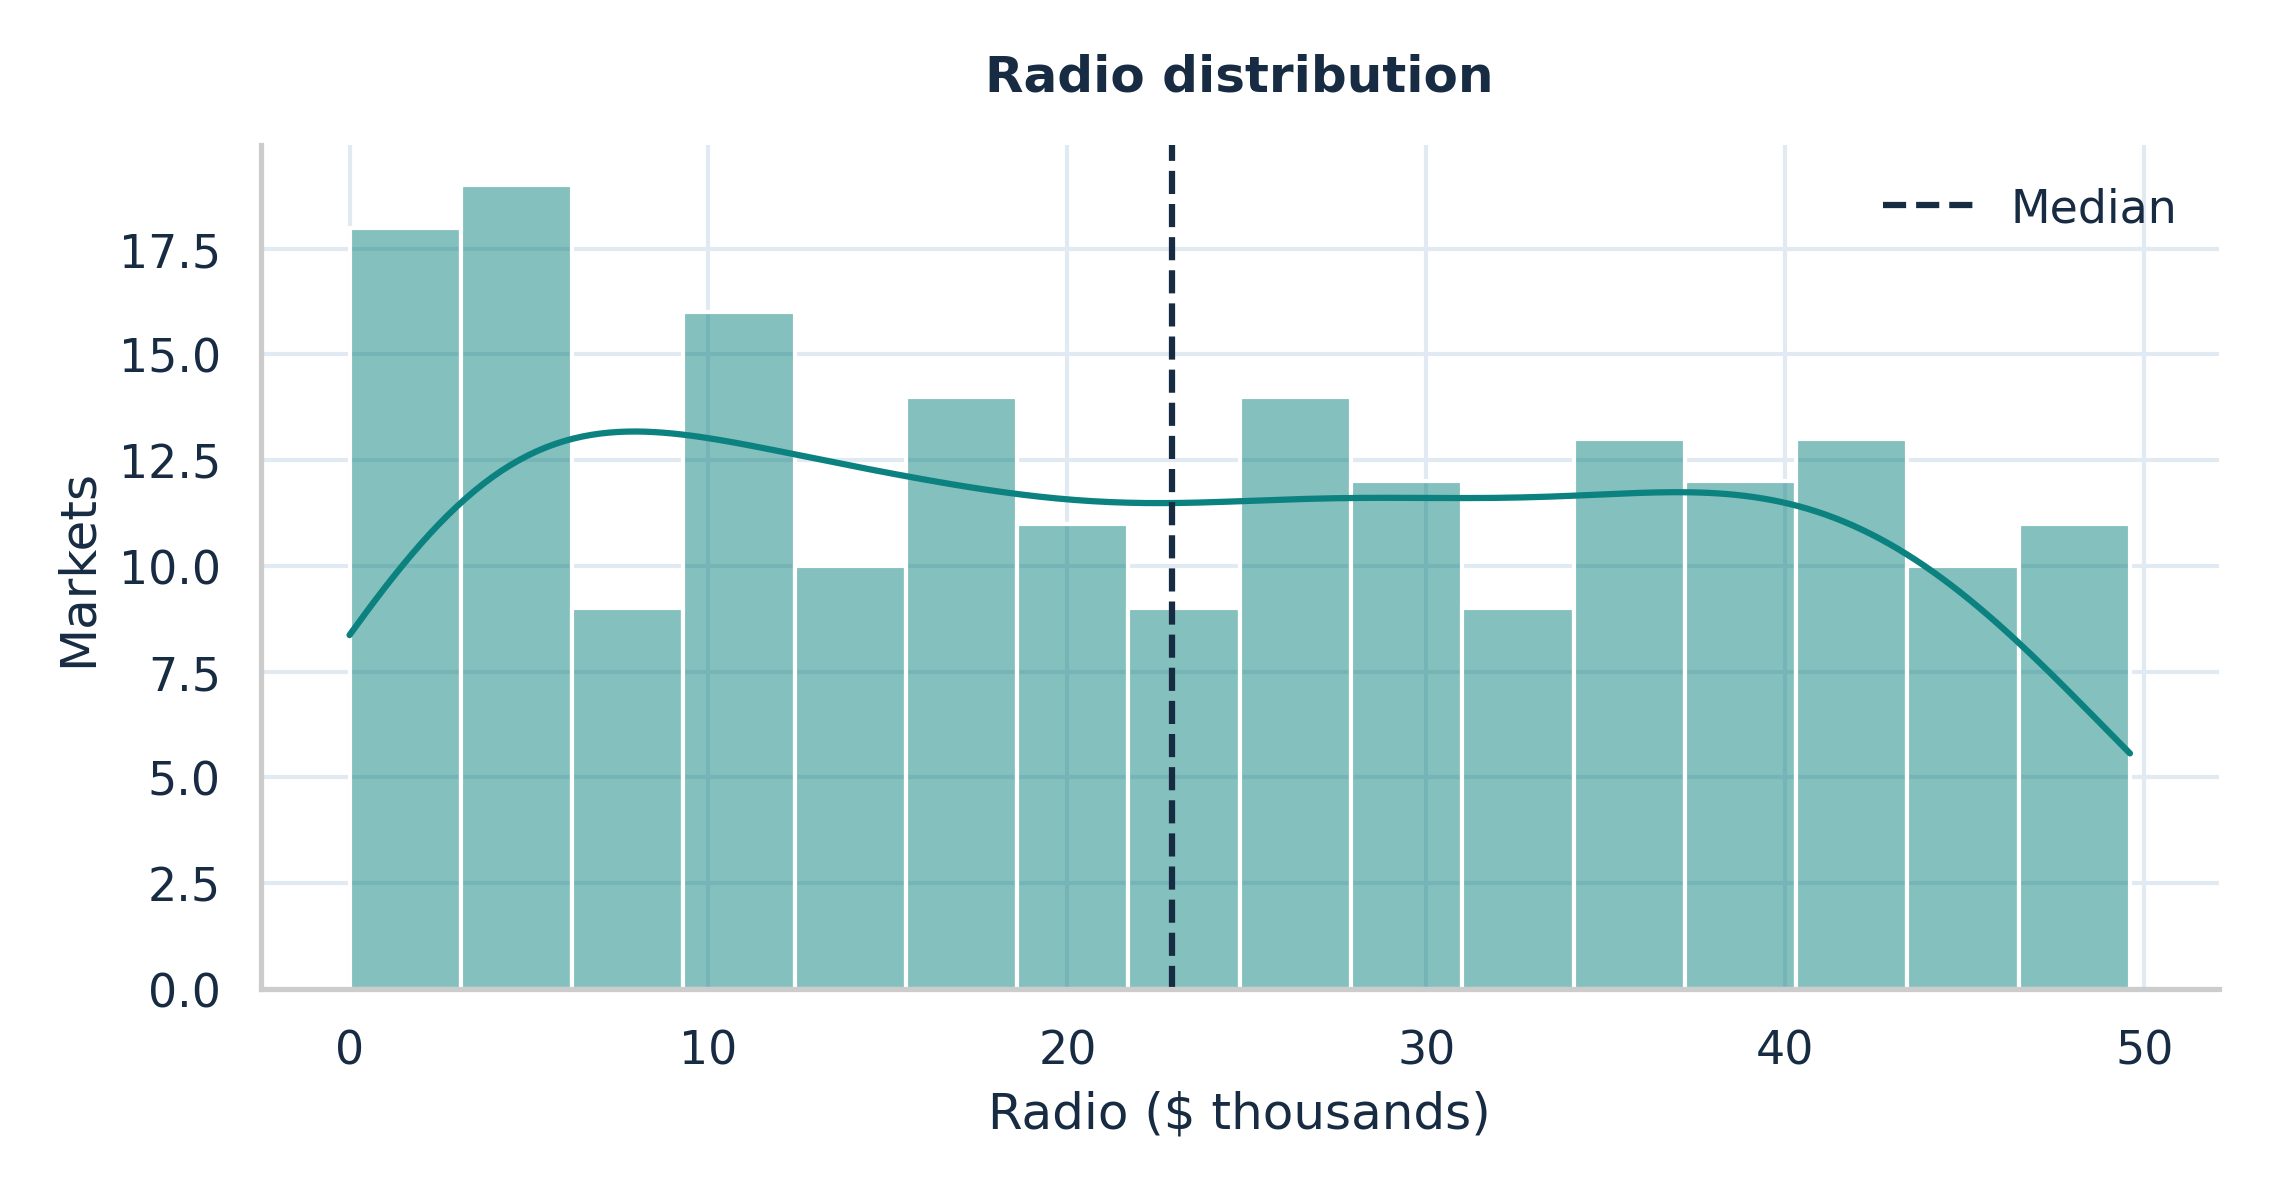

Radio averages 23.26 with a median of 22.90. Sample skewness is +0.09. The dashed line marks the median.

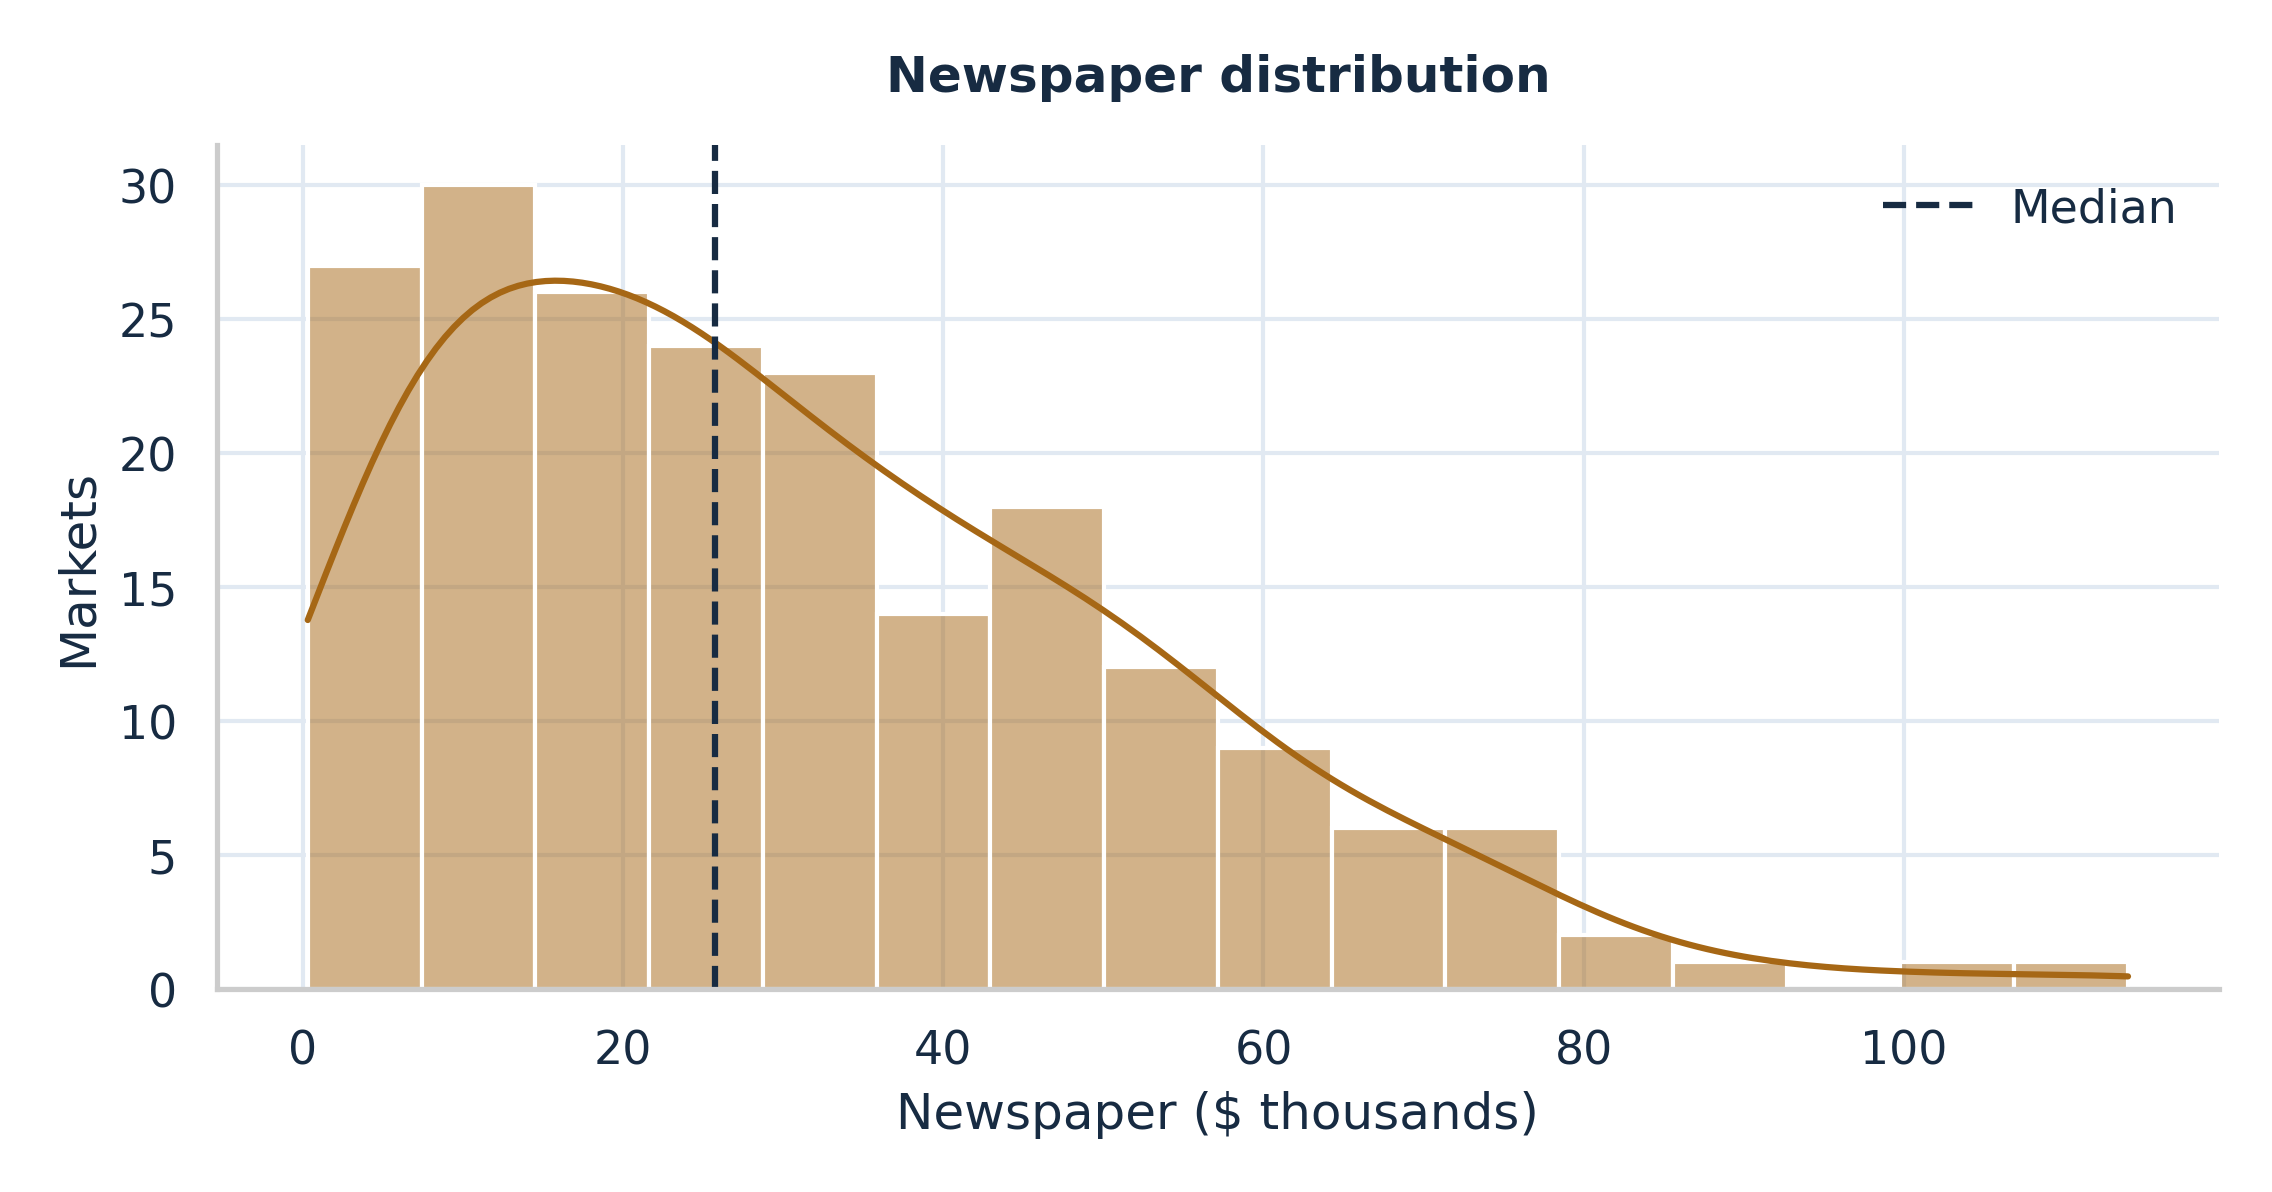

Newspaper averages 30.55 with a median of 25.75. Sample skewness is +0.89. The dashed line marks the median.

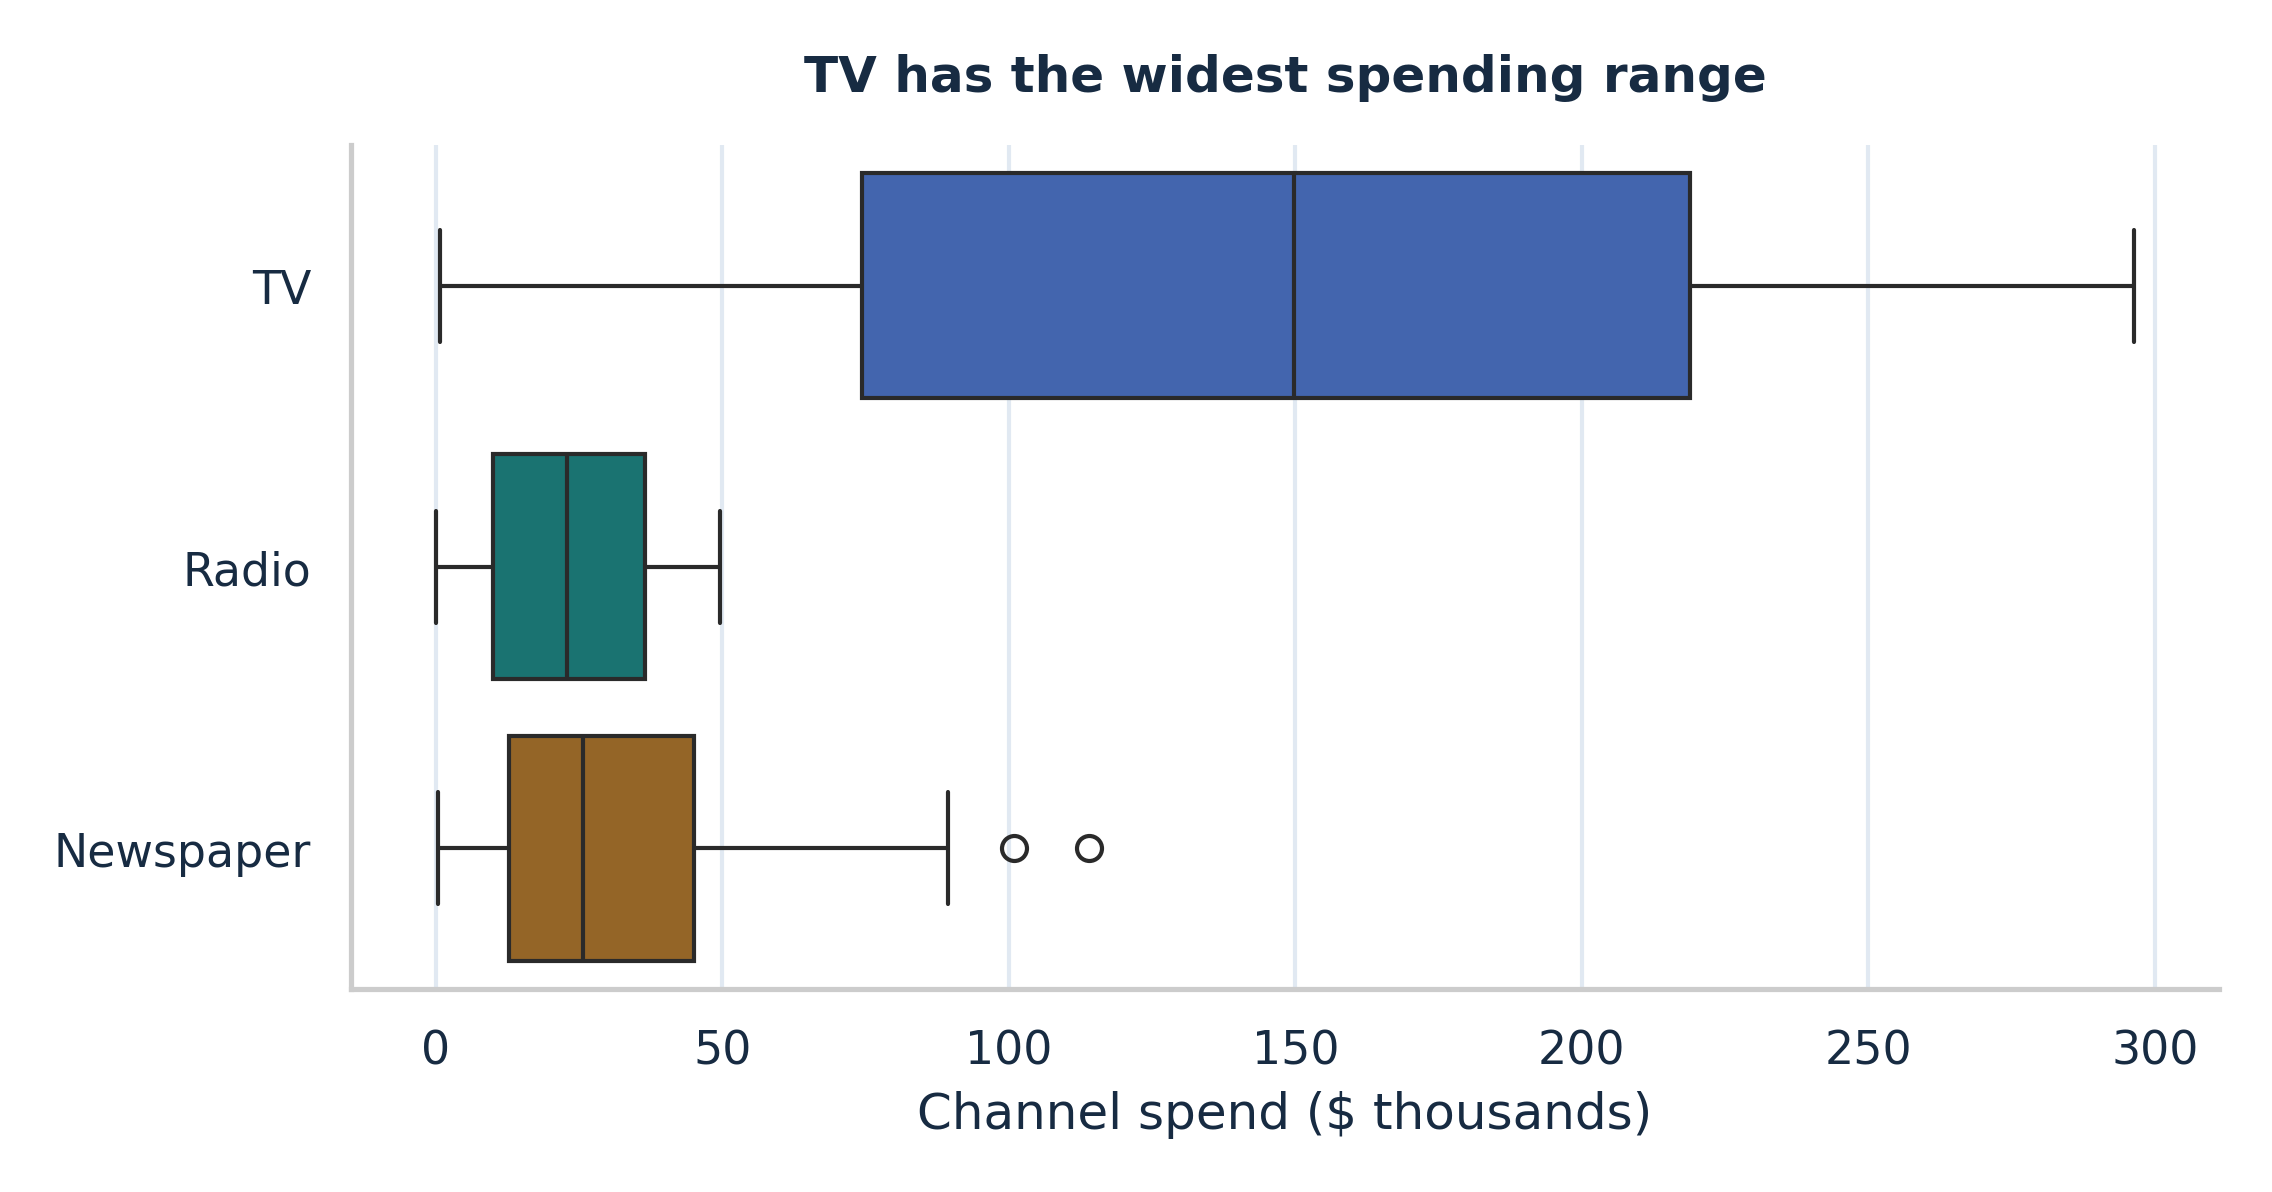

The IQR rule flags 2 markets across the measured fields. TV spans the widest budget range. Points beyond the boxplot whiskers are retained.

In [3]:
display(eda['descriptive_statistics'].round(4), eda['correlations'].round(3))

figure_dir = root / 'outputs' / 'figures'
published = json.loads((root / 'outputs' / 'reports' / 'findings.json').read_text(encoding='utf-8'))

def charts(*names, findings=published):
    for name in names:
        display(Image(filename=str(figure_dir / f'{name}.png'), width=720))
        display(Markdown(findings['captions'][name]))

charts('sales_distribution', 'tv_distribution', 'radio_distribution',
       'newspaper_distribution', 'channel_boxplots')

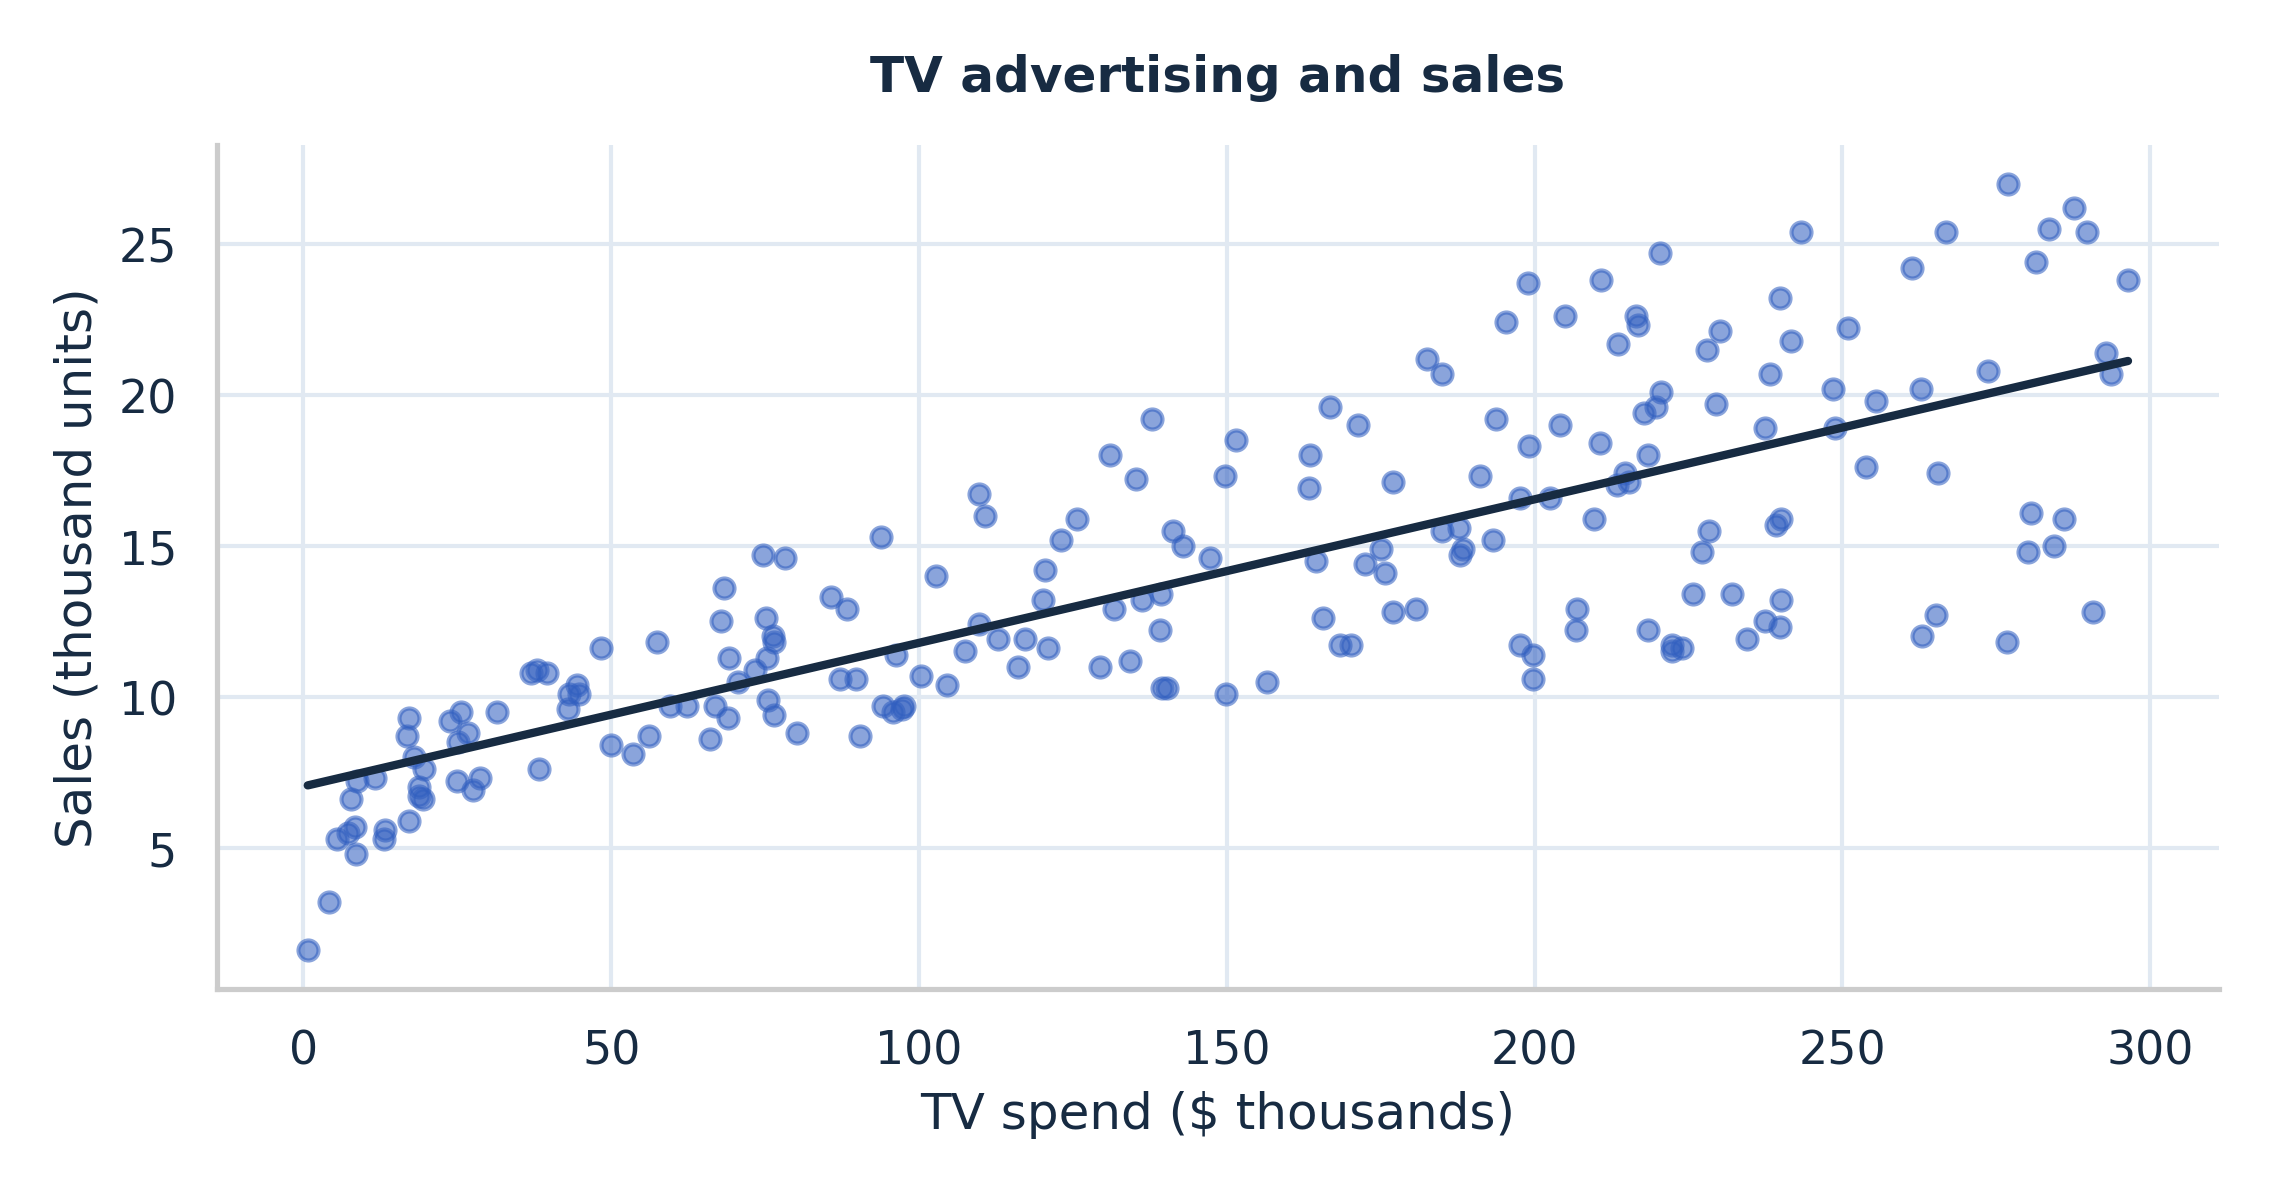

TV and sales have Pearson r = 0.78. The line summarizes the unadjusted relationship across markets. Spread around the line reflects variation at similar spend.

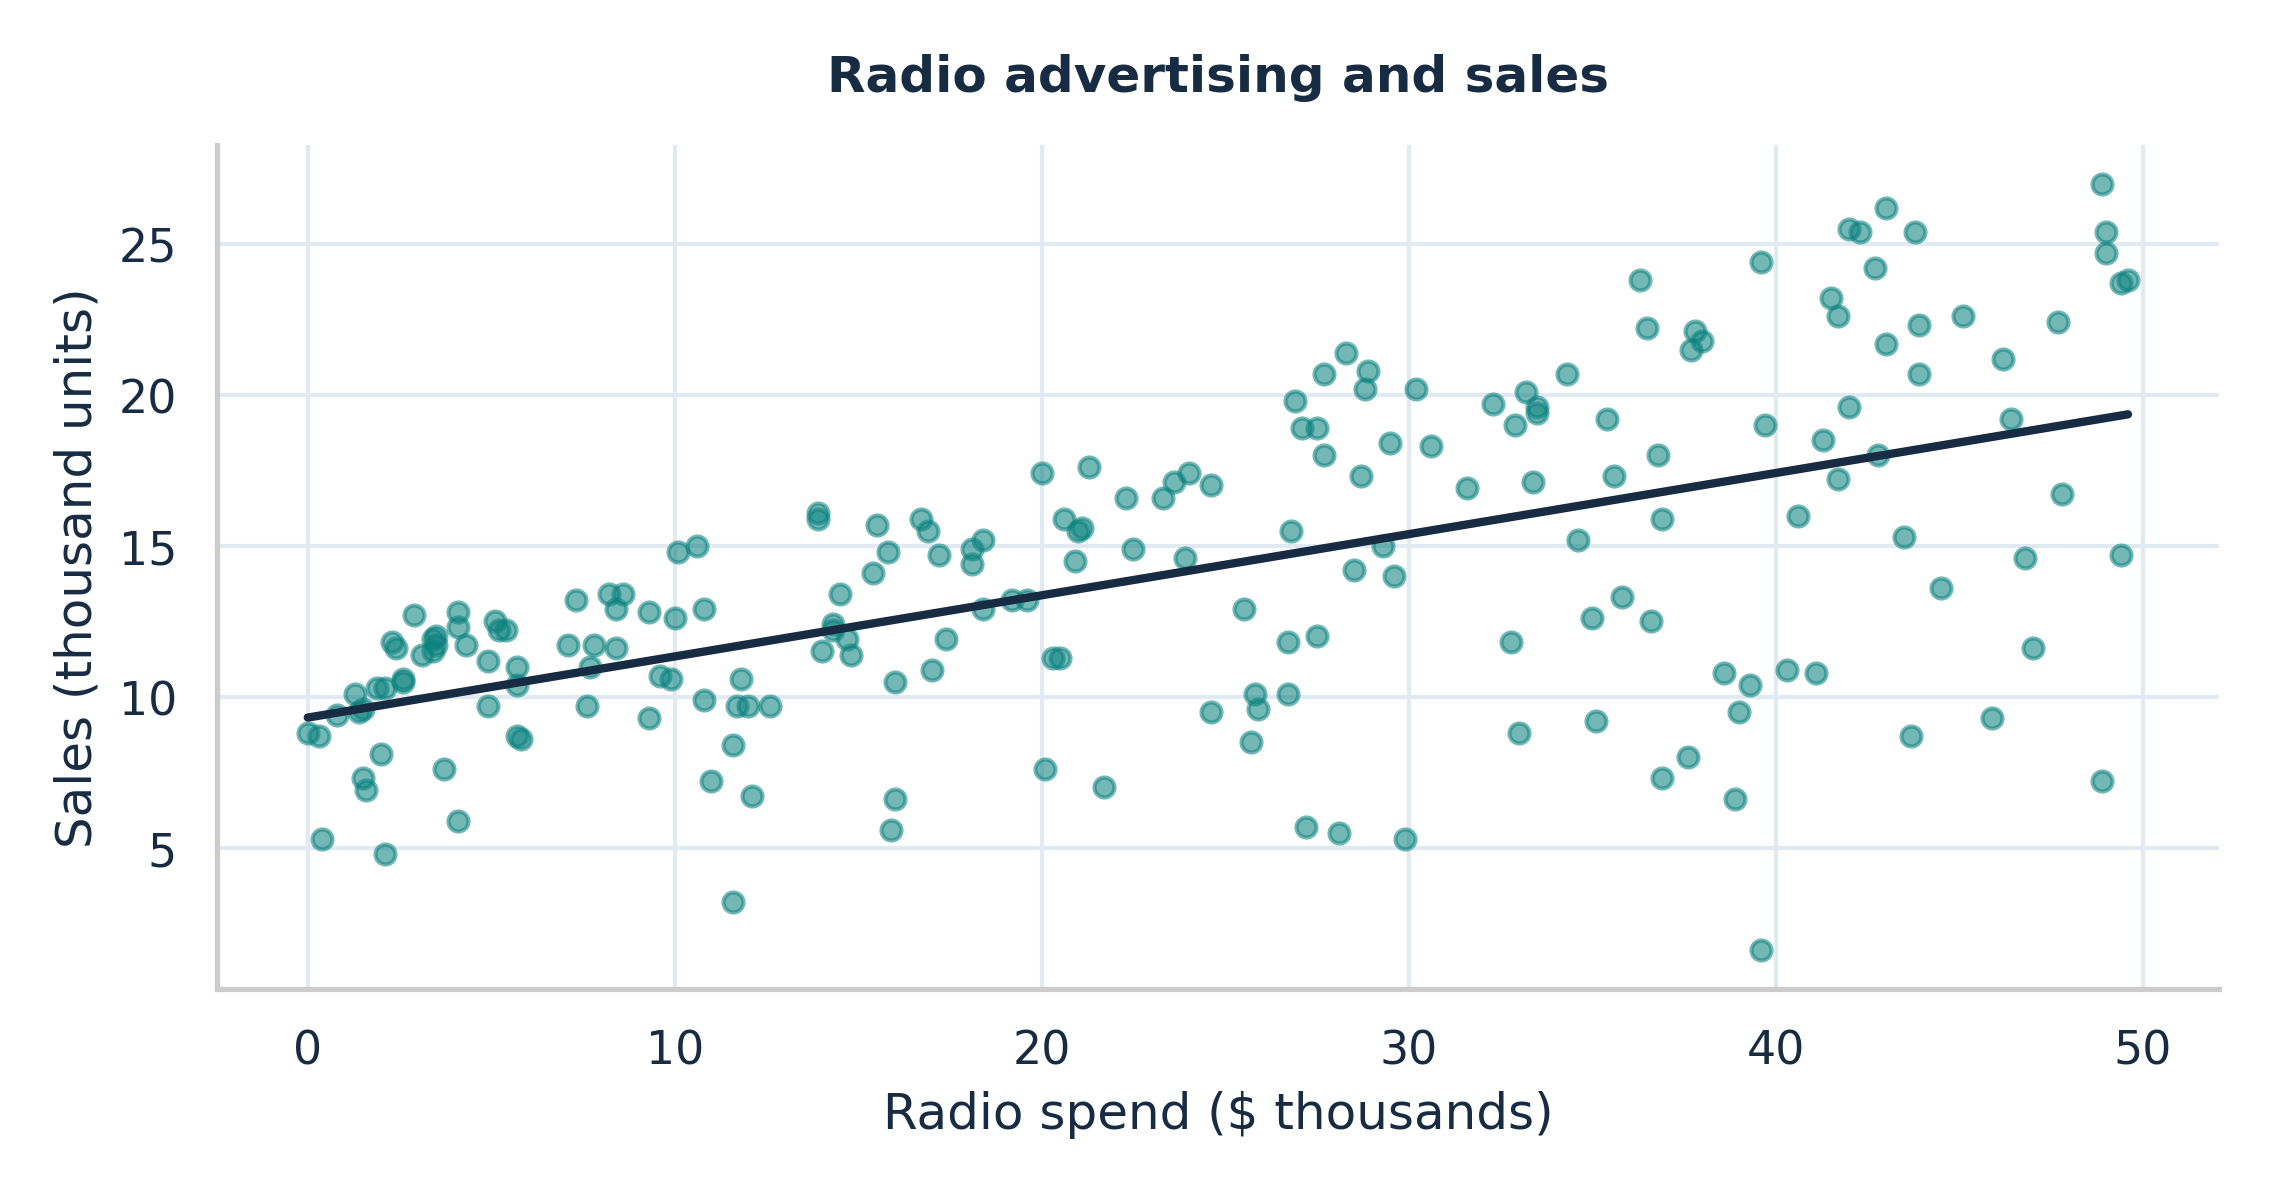

Radio and sales have Pearson r = 0.58. The line summarizes the unadjusted relationship across markets. Spread around the line reflects variation at similar spend.

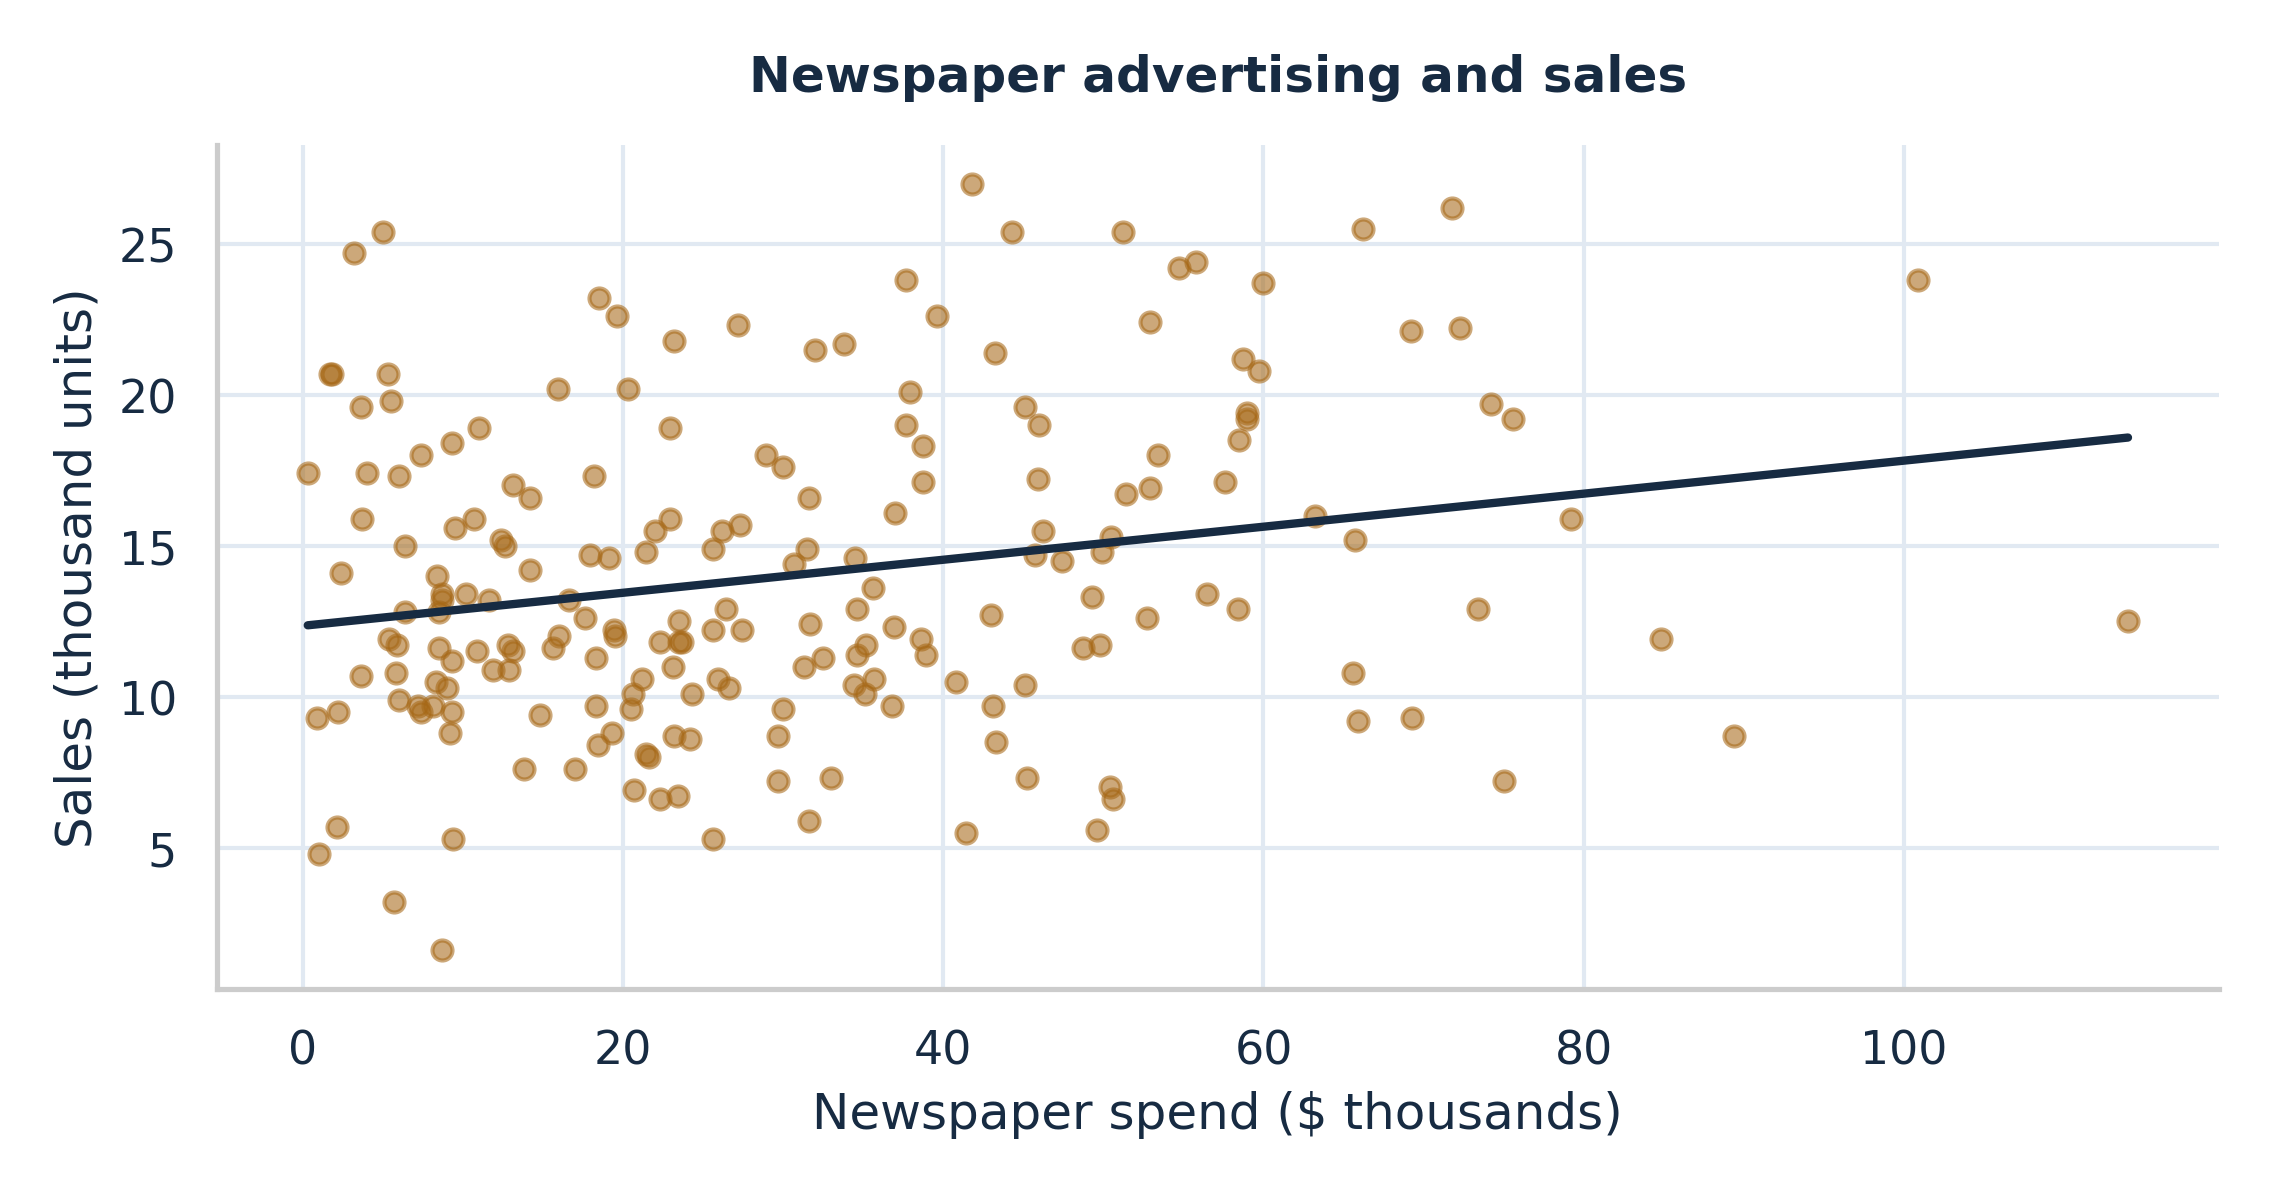

Newspaper and sales have Pearson r = 0.23. The line summarizes the unadjusted relationship across markets. Spread around the line reflects variation at similar spend.

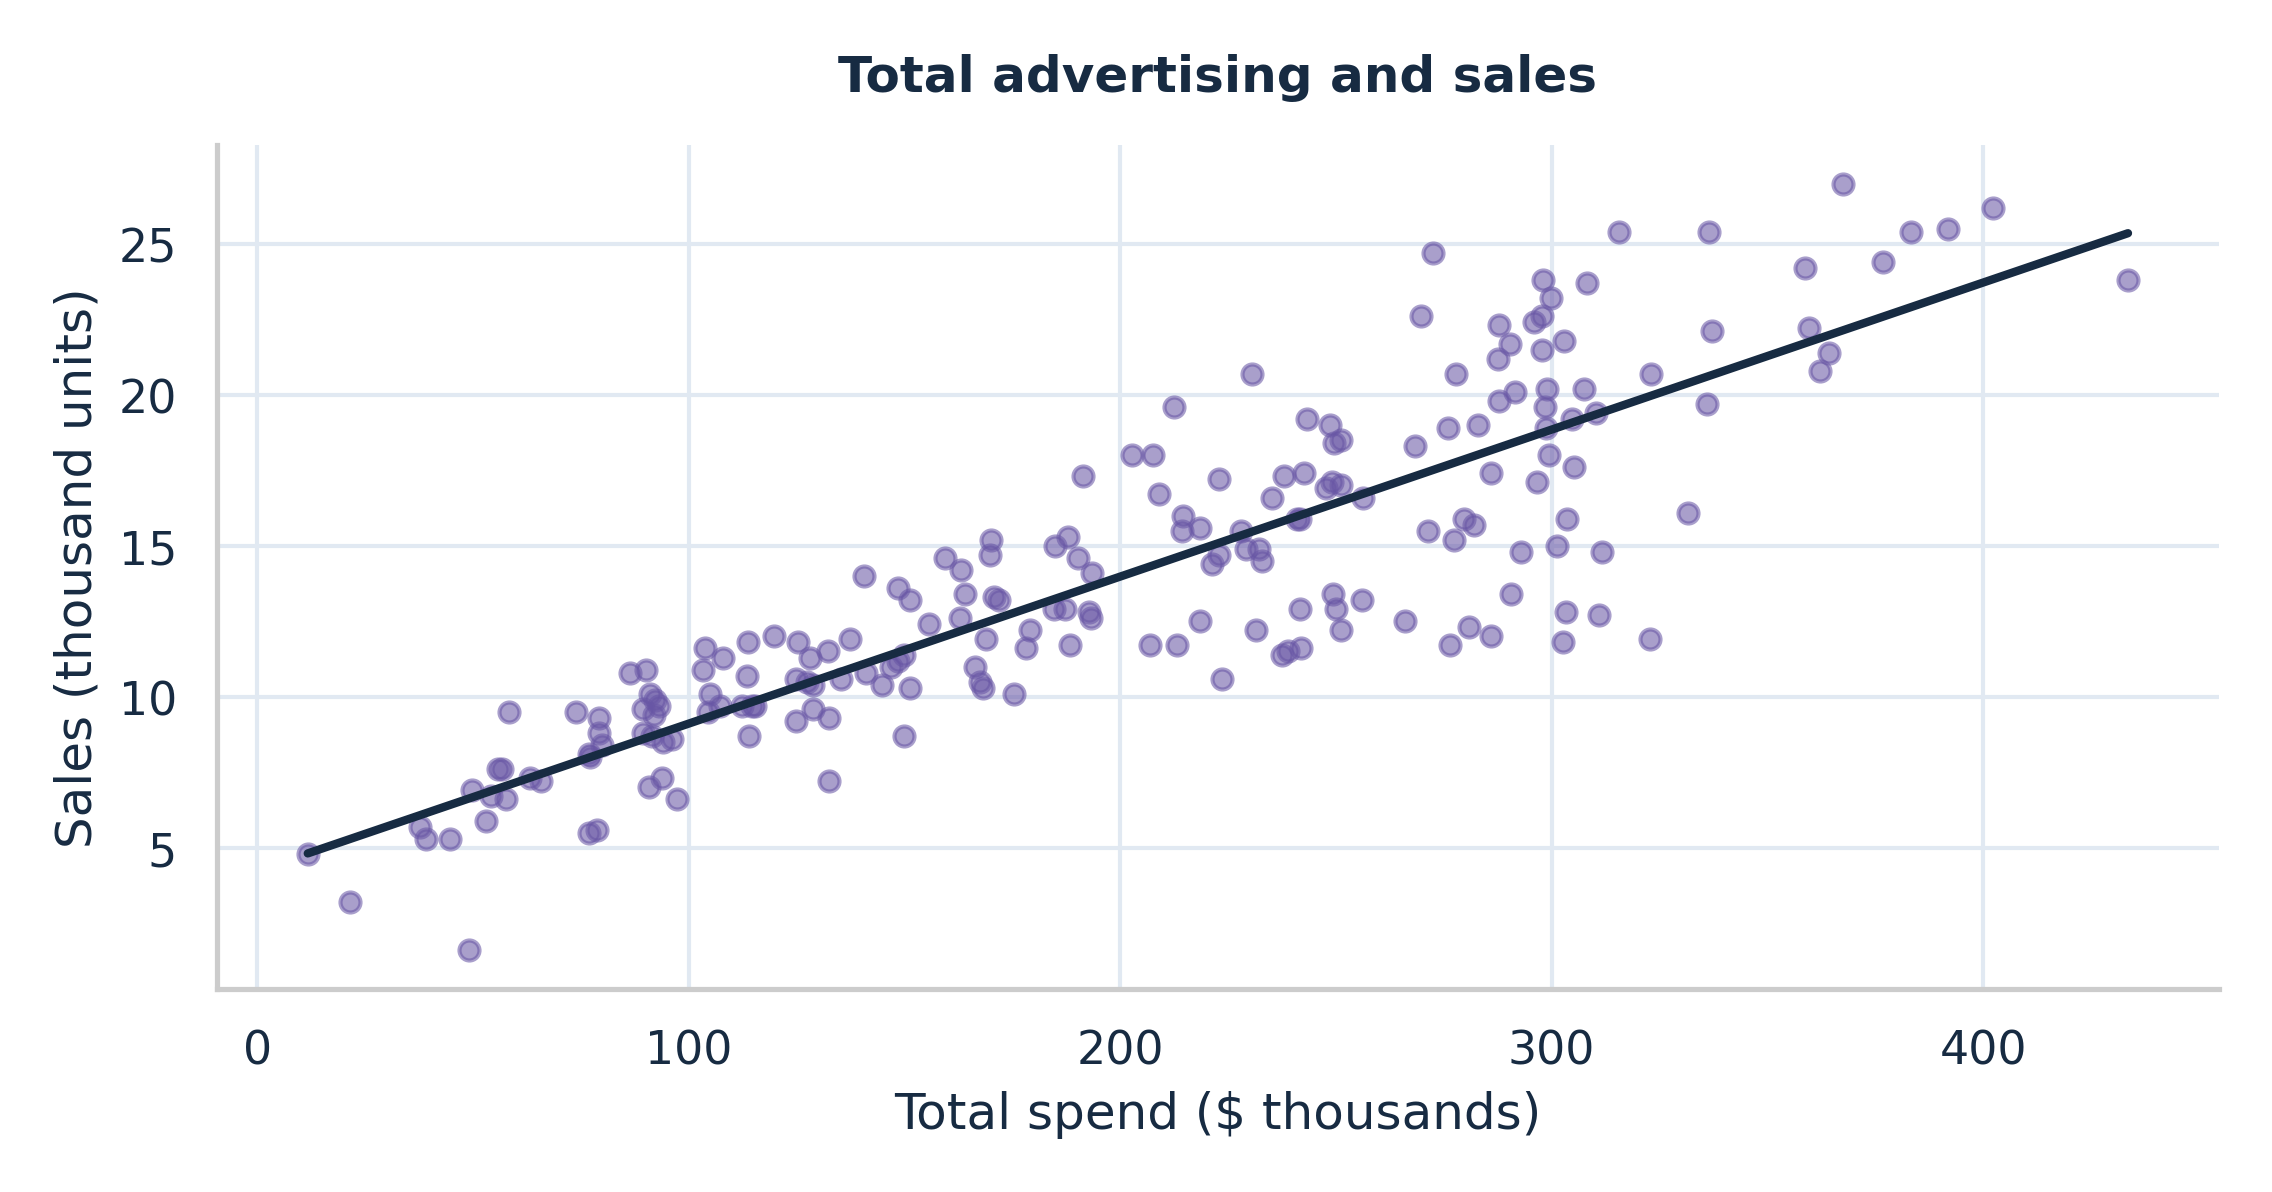

Total and sales have Pearson r = 0.87. The line summarizes the unadjusted relationship across markets. Spread around the line reflects variation at similar spend.

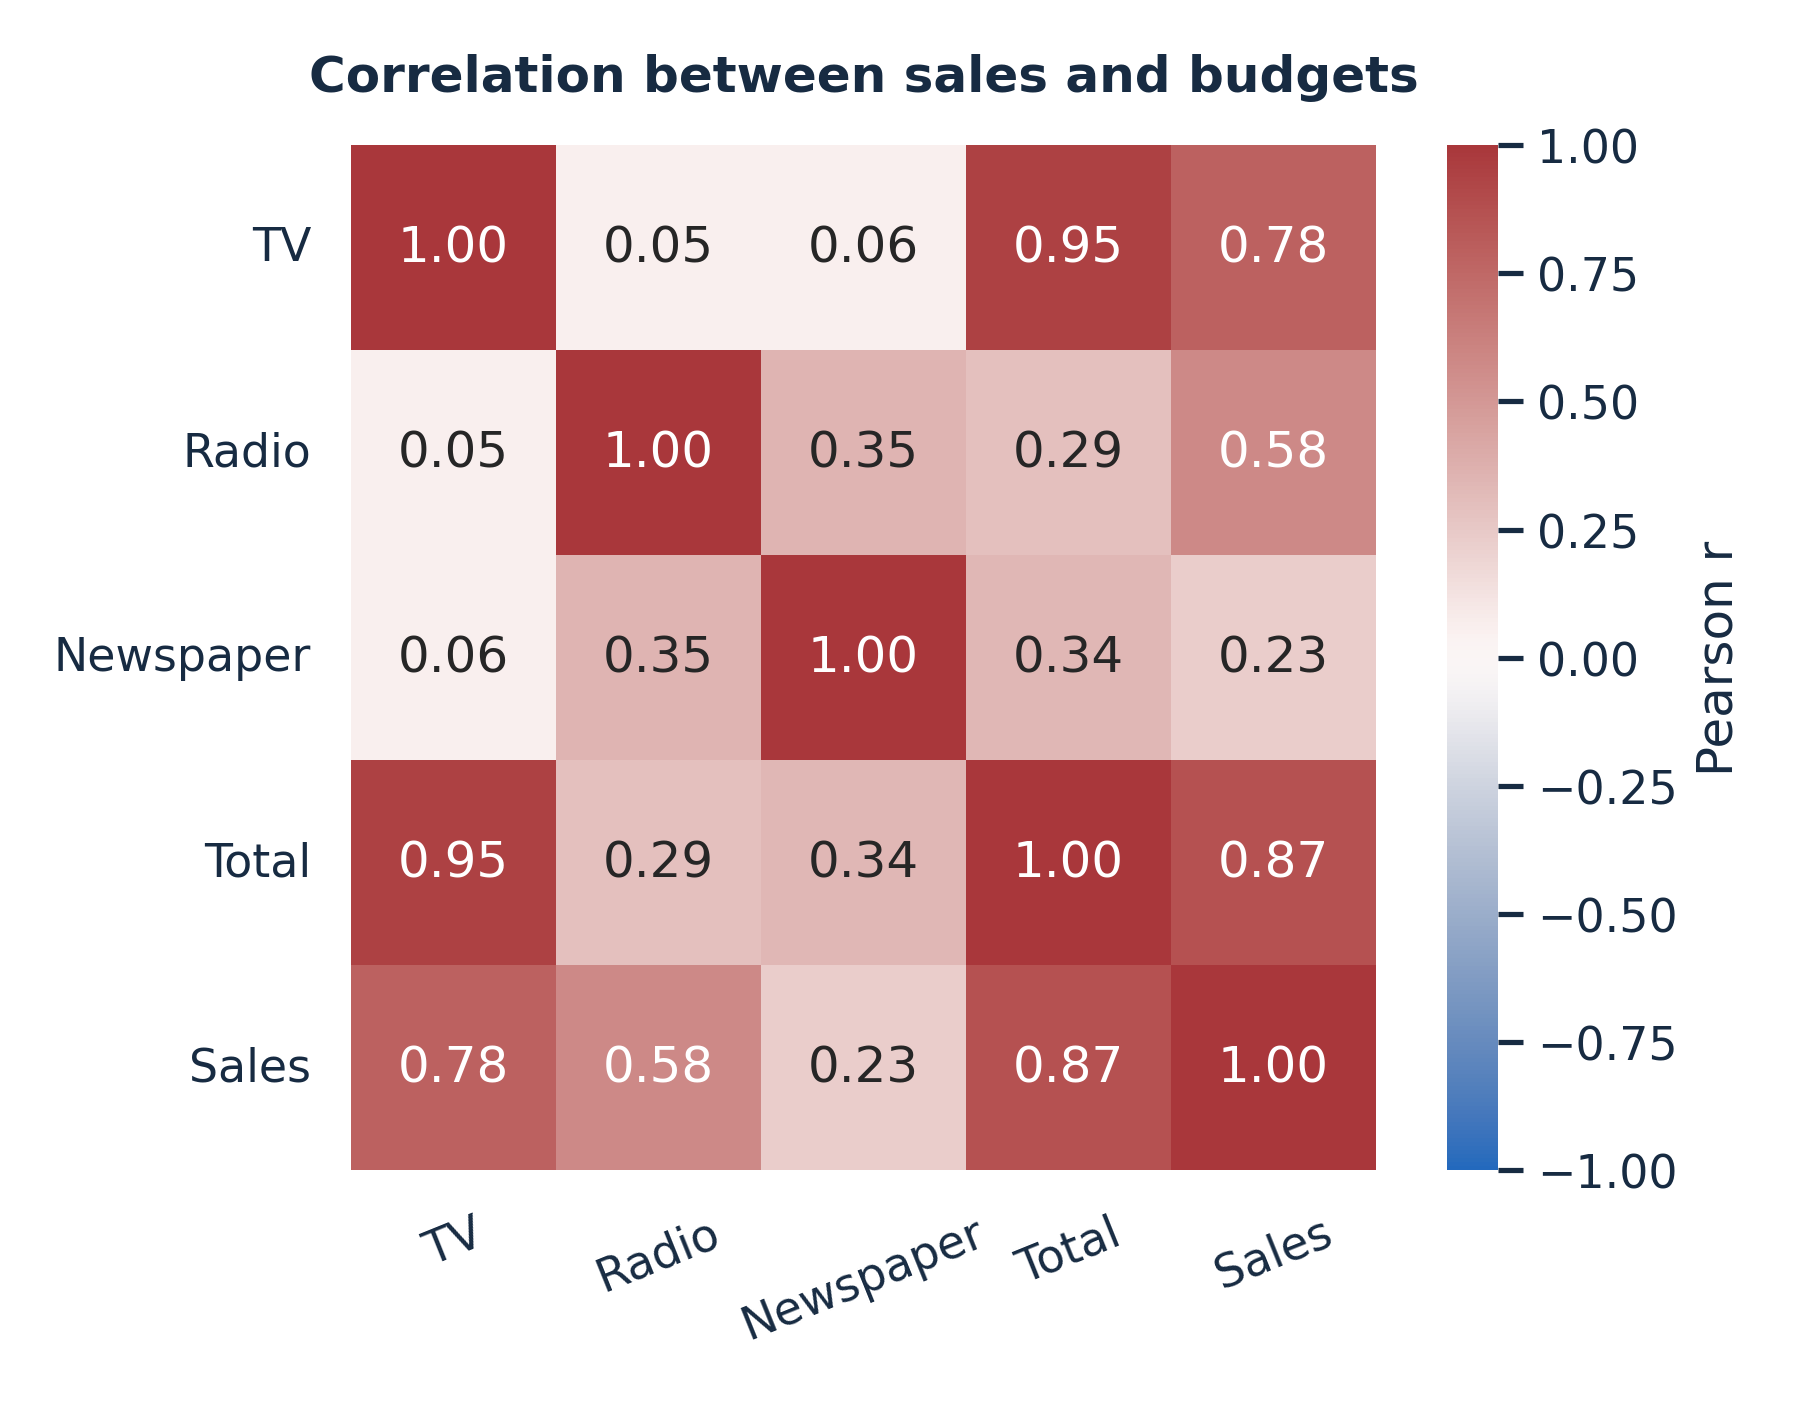

TV has r = 0.78 with sales and total spend has r = 0.87. Total inherits information from its component budgets.

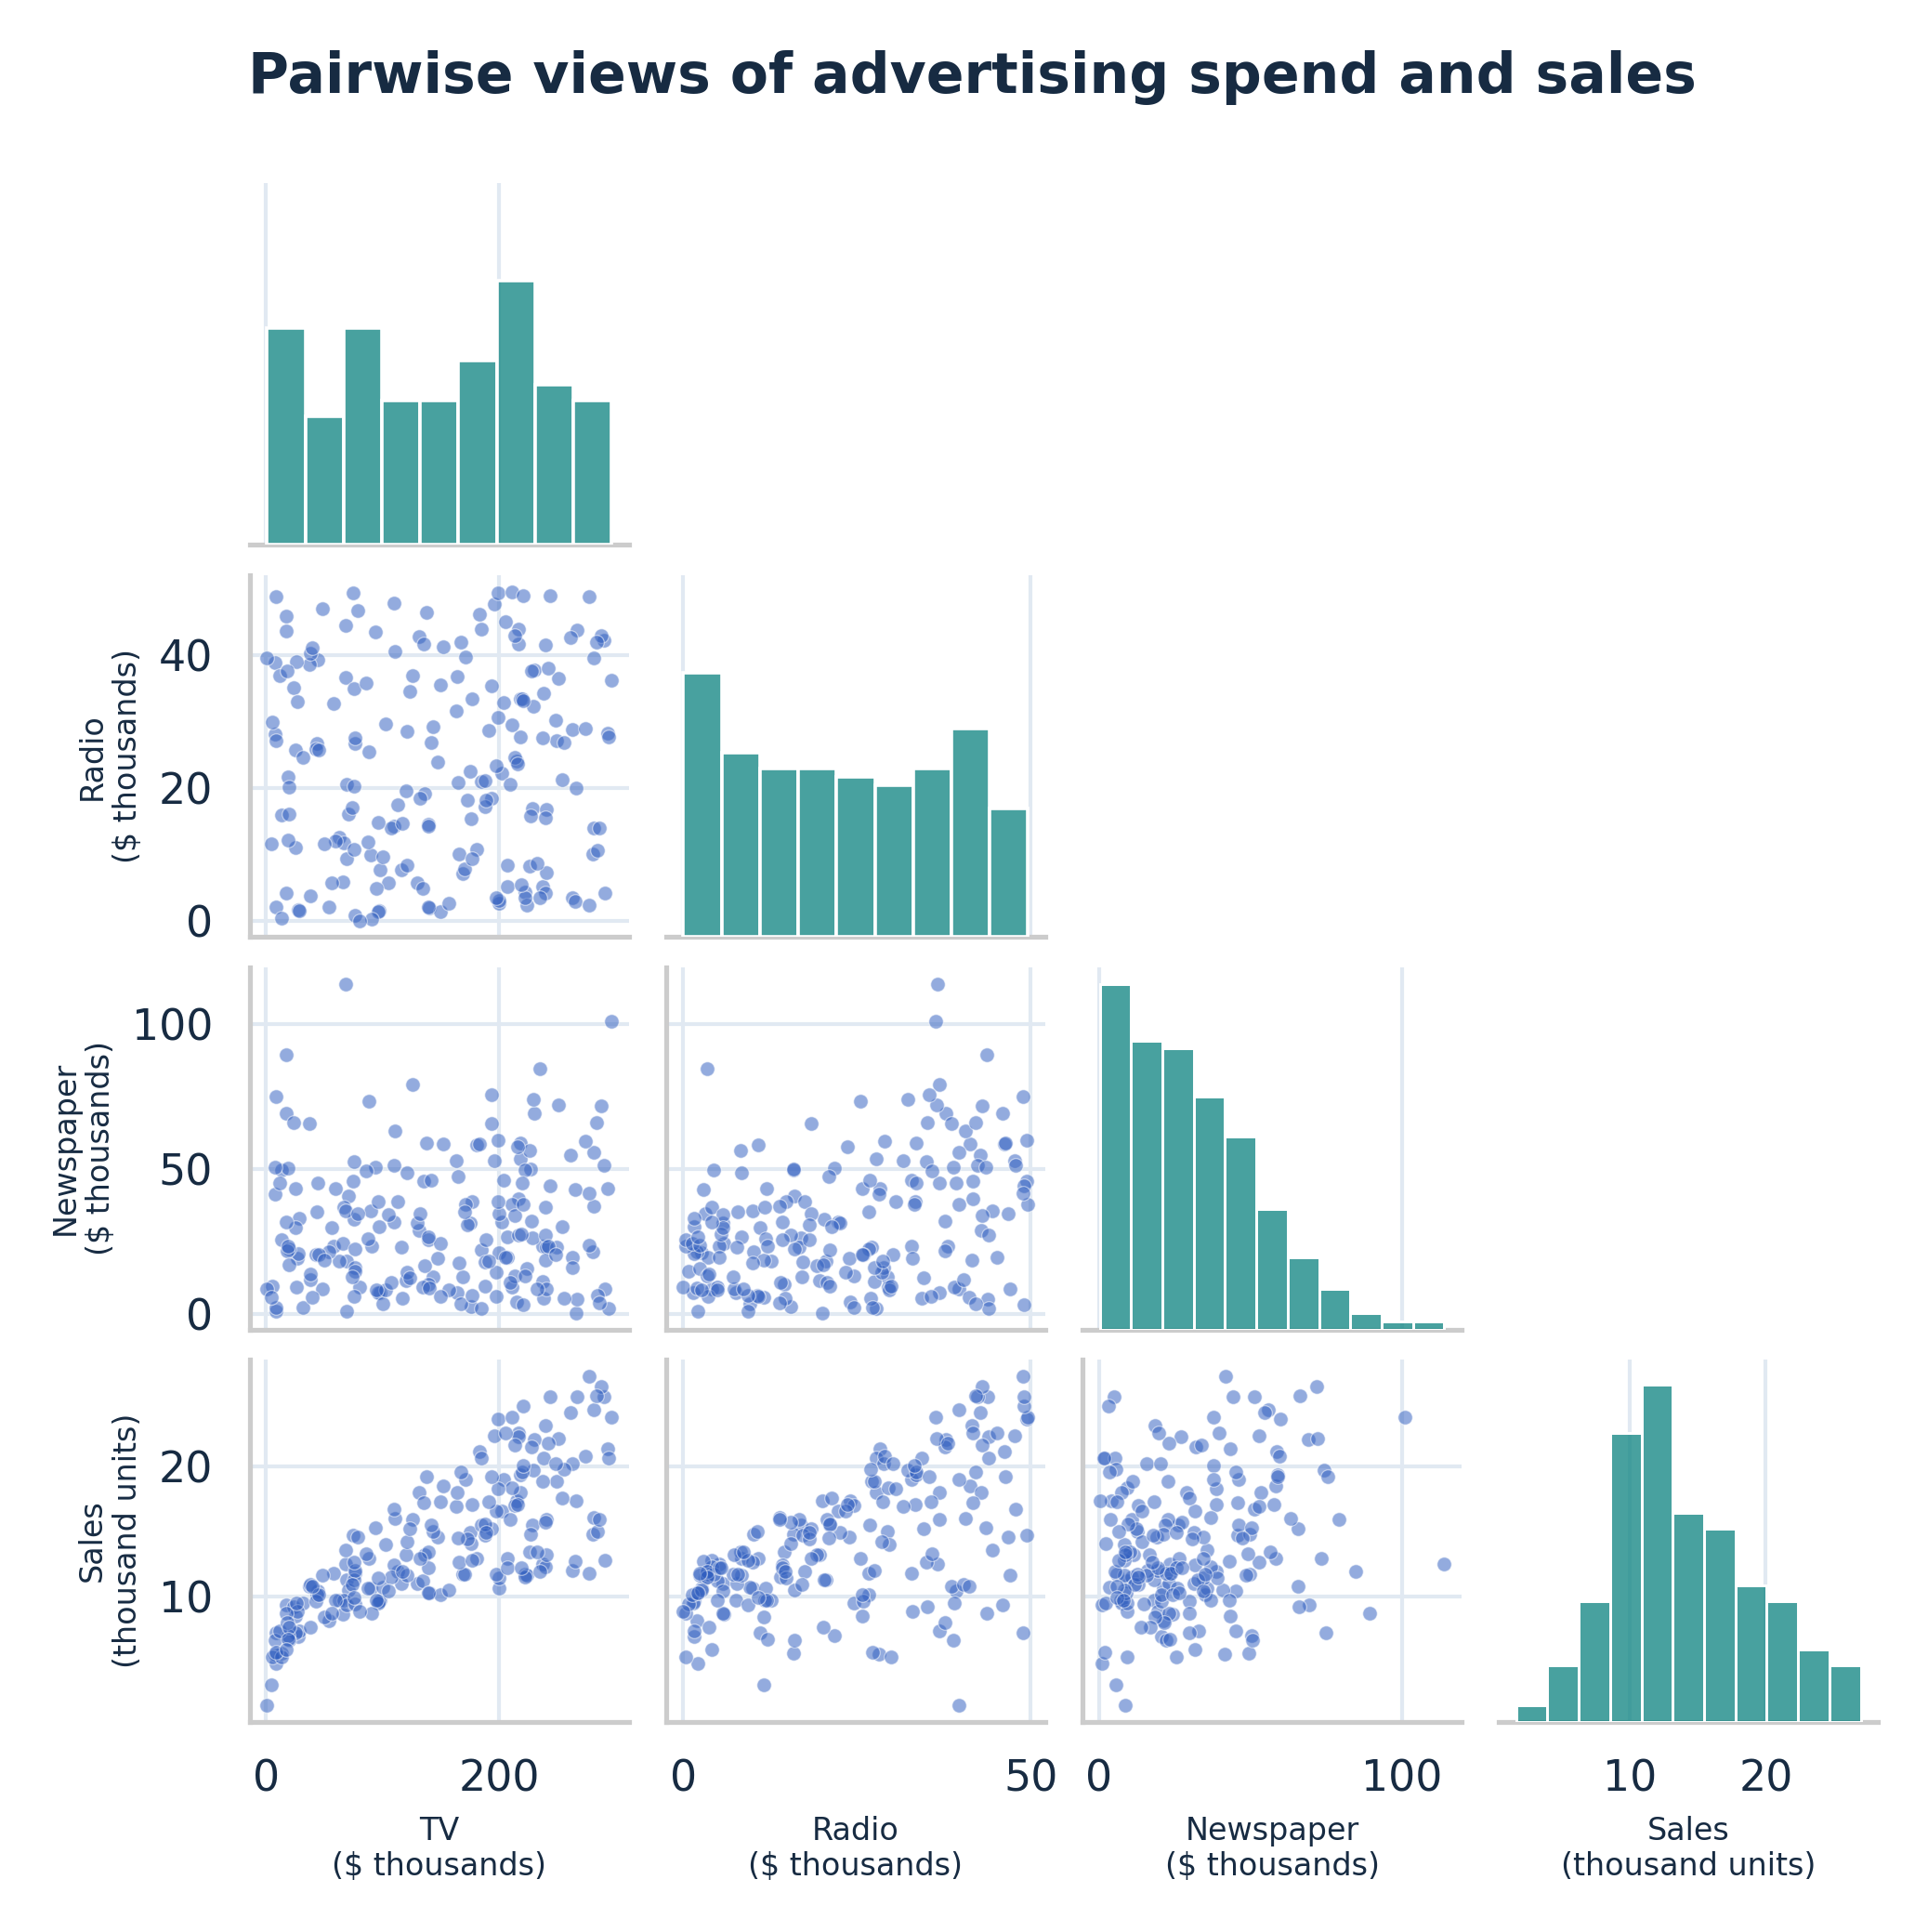

The diagonal shows each distribution. The lower panels show joint coverage and scatter, including the wider spread in sales at higher TV budgets.

In [4]:
charts('tv_vs_sales', 'radio_vs_sales', 'newspaper_vs_sales',
       'total_vs_sales', 'correlation_heatmap', 'pairplot')

## 5. Feature engineering and selection
Total spend is the sum of the three budgets. Channel shares divide each budget by total spend, with zero shares when all budgets are zero. The candidates compare raw budgets, total alone, total with two shares, and selected TV and Radio interaction and quadratic terms. Keeping total separate from its three components avoids exact multicollinearity. Feature selection depends on training cross-validation performance.

In [5]:
X_train, X_test, y_train, y_test = split_data(clean)
assert X_train.index.intersection(X_test.index).empty
print(f'{len(X_train)} training markets and {len(X_test)} untouched holdout markets')
display(make_features(X_train, 'Total and two shares').head().round(3))
display(make_features(X_train, 'Quadratic TV and Radio').head().round(2))

160 training markets and 40 untouched holdout markets


,Total,TV_share,Radio_share
79,146.8,0.790,0.052
197,192.7,0.919,0.048
38,104.9,0.411,0.255
24,93.2,0.668,0.135
122,242.0,0.926,0.010


,TV,Radio,TV_squared,Radio_squared,TV_x_Radio
79,116.0,7.7,13456.00,59.29,893.20
197,177.0,9.3,31329.00,86.49,1646.10
38,43.1,26.7,1857.61,712.89,1150.77
24,62.3,12.6,3881.29,158.76,784.98
122,224.0,2.4,50176.00,5.76,537.60


## 6. Model development and repeated cross-validation
A mean dummy provides a baseline. Candidates include simple and multiple linear regression, Ridge, Lasso, ElasticNet, Random Forest, Extra Trees, Gradient Boosting and OLS feature variants. The same 25 training splits come from five repeats of five-fold cross-validation. Linear candidates scale inside their pipelines. Compact grids tune the regularized models and ensembles. Mean validation RMSE determines the ranking before holdout evaluation.

In [6]:
ranking, folds, fitted = train_models(X_train, y_train)
display(ranking[['rank', 'model', 'feature_set', 'parameters', 'cv_rmse_mean', 'cv_rmse_std',
                 'cv_mae_mean', 'cv_r2_mean']].round(4))
display(folds.groupby('model')['rmse'].agg(['count', 'mean', 'std']).round(4))

,rank,model,feature_set,parameters,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
0,1,Extra Trees,TV and Radio,"{""features__spec"": ""TV and Radio"", ""model__min...",0.5818,0.2219,0.4038,0.9853
1,2,Quadratic TV and Radio OLS,Quadratic TV and Radio,{},0.6140,0.2674,0.4229,0.9830
2,3,Quadratic plus Newspaper OLS,Quadratic plus Newspaper,{},0.6238,0.2651,0.4340,0.9826
3,4,Gradient Boosting,TV and Radio,"{""features__spec"": ""TV and Radio"", ""model__max...",0.7980,0.1780,0.5842,0.9731
4,5,Random Forest,Three channels,"{""model__max_features"": 1.0, ""model__min_sampl...",0.8646,0.2060,0.6333,0.9691
5,6,TV and Radio interaction OLS,TV and Radio interaction,{},0.9432,0.3087,0.6686,0.9618
6,7,TV and Radio OLS,TV and Radio,{},1.6492,0.3508,1.2227,0.8842
7,8,Lasso Regression,Three channels,"{""model__alpha"": 0.1}",1.6615,0.3446,1.2304,0.8832
8,9,ElasticNet Regression,Three channels,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.75}",1.6630,0.3475,1.2327,0.8825
9,10,Multiple Linear Regression,Three channels,{},1.6638,0.3482,1.2331,0.8823


,count,mean,std
model,,,
Dummy Mean Baseline,25,5.1034,0.5254
ElasticNet Regression,25,1.6630,0.3547
Extra Trees,25,0.5818,0.2265
Gradient Boosting,25,0.7980,0.1817
Lasso Regression,25,1.6615,0.3517
Multiple Linear Regression,25,1.6638,0.3554
Quadratic TV and Radio OLS,25,0.6140,0.2729
Quadratic plus Newspaper OLS,25,0.6238,0.2706
Random Forest,25,0.8646,0.2102


## 7. Holdout model evaluation
The locked split measures generalization. MAE gives the typical absolute prediction error, MSE squares misses, and RMSE expresses that loss in the original sales units. R² compares squared error with the holdout mean baseline. Adjusted R² applies to the training OLS fits, where it penalizes additional predictors.

The test and scenario exports are generated with the saved model. The cell below checks that the refitted winner agrees with the saved model on every holdout observation.

,model,train_adjusted_r2_ols,test_mae,test_mse,test_rmse,test_r2
0,Extra Trees,NaN,0.3806,0.2362,0.4860,0.9925
1,Quadratic TV and Radio OLS,0.9848,0.4935,0.3642,0.6035,0.9885
2,Quadratic plus Newspaper OLS,0.9849,0.4922,0.3679,0.6065,0.9883
3,Gradient Boosting,NaN,0.5458,0.4257,0.6525,0.9865
4,Random Forest,NaN,0.6130,0.5709,0.7556,0.9819
5,TV and Radio interaction OLS,0.9649,0.6664,0.8127,0.9015,0.9743
6,TV and Radio OLS,0.8943,1.4443,3.1379,1.7714,0.9006
7,Lasso Regression,NaN,1.4613,3.2089,1.7913,0.8983
8,ElasticNet Regression,NaN,1.4608,3.1819,1.7838,0.8992
9,Multiple Linear Regression,0.8937,1.4608,3.1741,1.7816,0.8994


,Source_Row_Zero_Based,TV,Radio,Newspaper,Actual_Sales,Predicted_Sales,Prediction_Error,Absolute_Error
0,95,163.3,31.6,52.9,16.9,16.802,0.098,0.098
1,15,195.4,47.7,52.9,22.4,22.048,0.352,0.352
2,30,292.9,28.3,43.2,21.4,20.619,0.781,0.781
3,158,11.7,36.9,45.2,7.3,7.127,0.173,0.173
4,128,220.3,49.0,3.2,24.7,24.050,0.650,0.650


,mean_residual,median_residual,residual_vs_prediction_spearman,residual_vs_prediction_p,largest_absolute_error,largest_error_source_row
0,-0.0467,-0.1146,0.157,0.3332,1.19,67


,channel,rmse_increase_mean,rmse_increase_std
0,TV,6.1264,0.5850
1,Radio,3.7691,0.3893
2,Newspaper,0.0000,0.0000


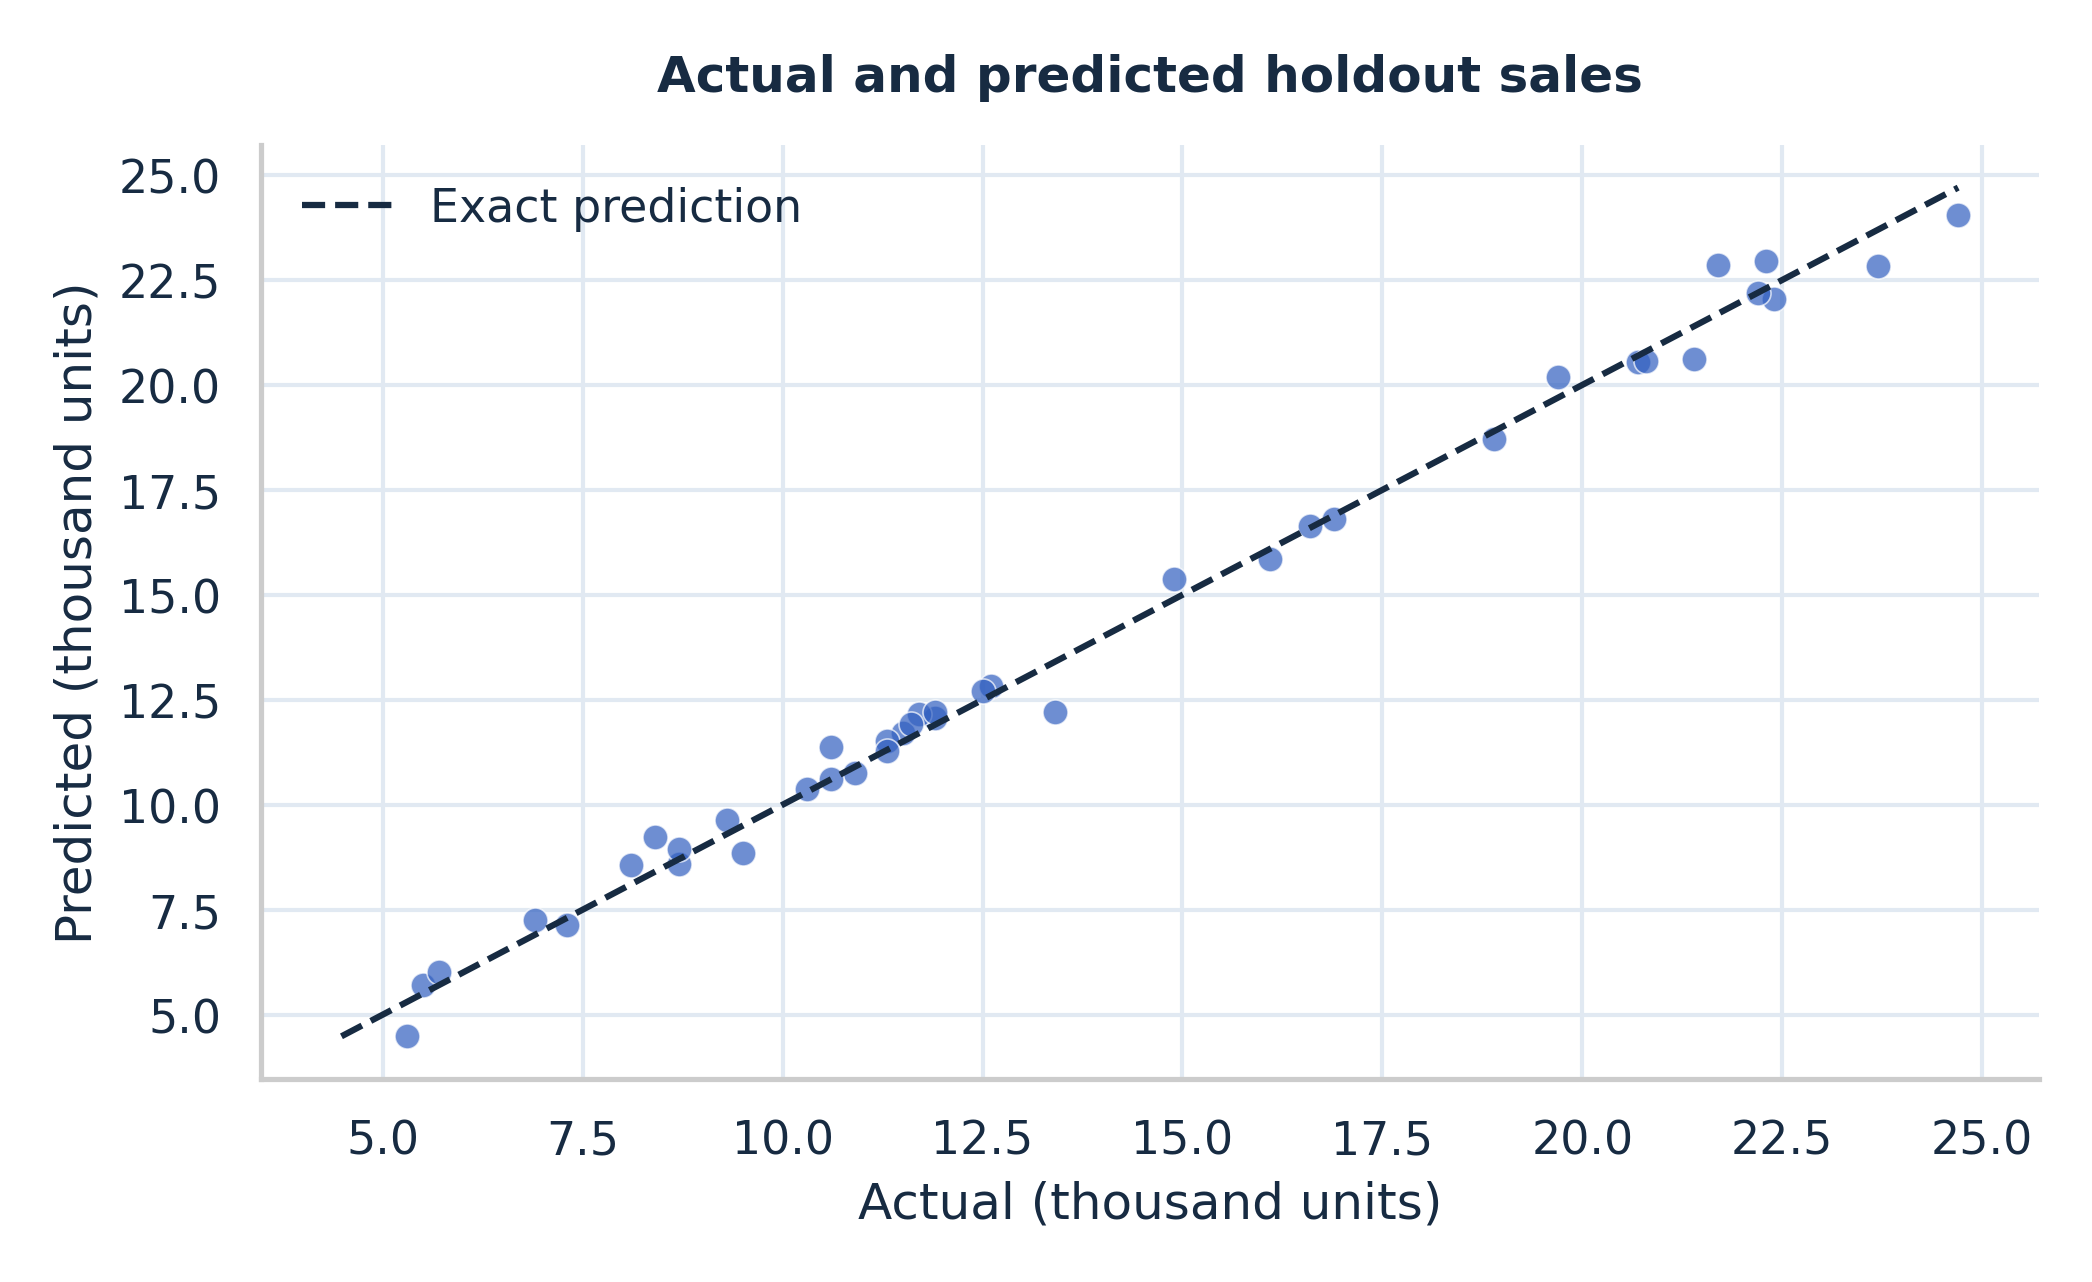

Points close to the diagonal are better predictions. Points above it are overpredictions.

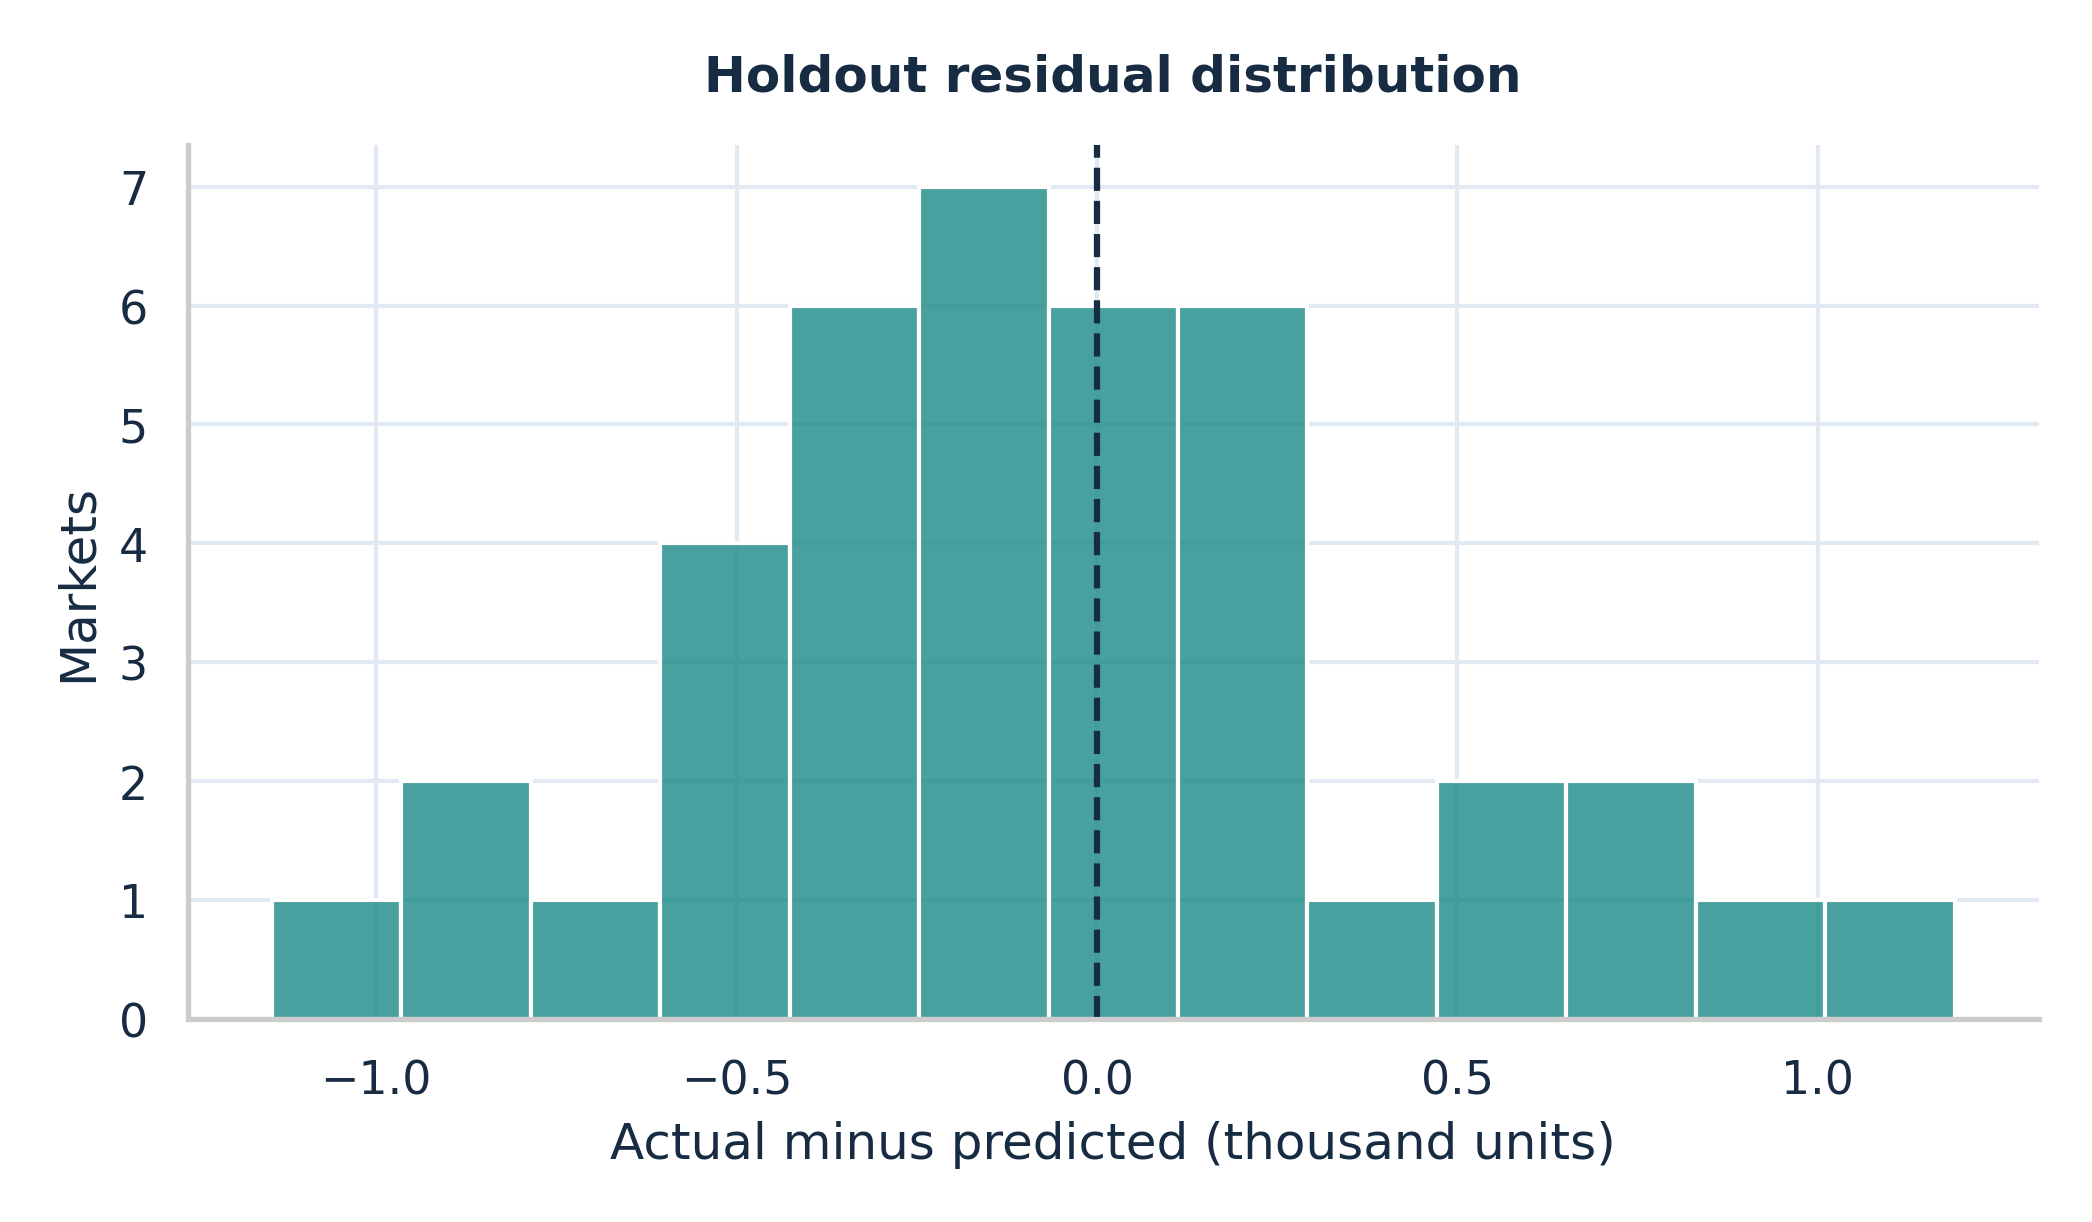

The residual histogram centers around a mean of -0.047. Negative residuals represent overprediction.

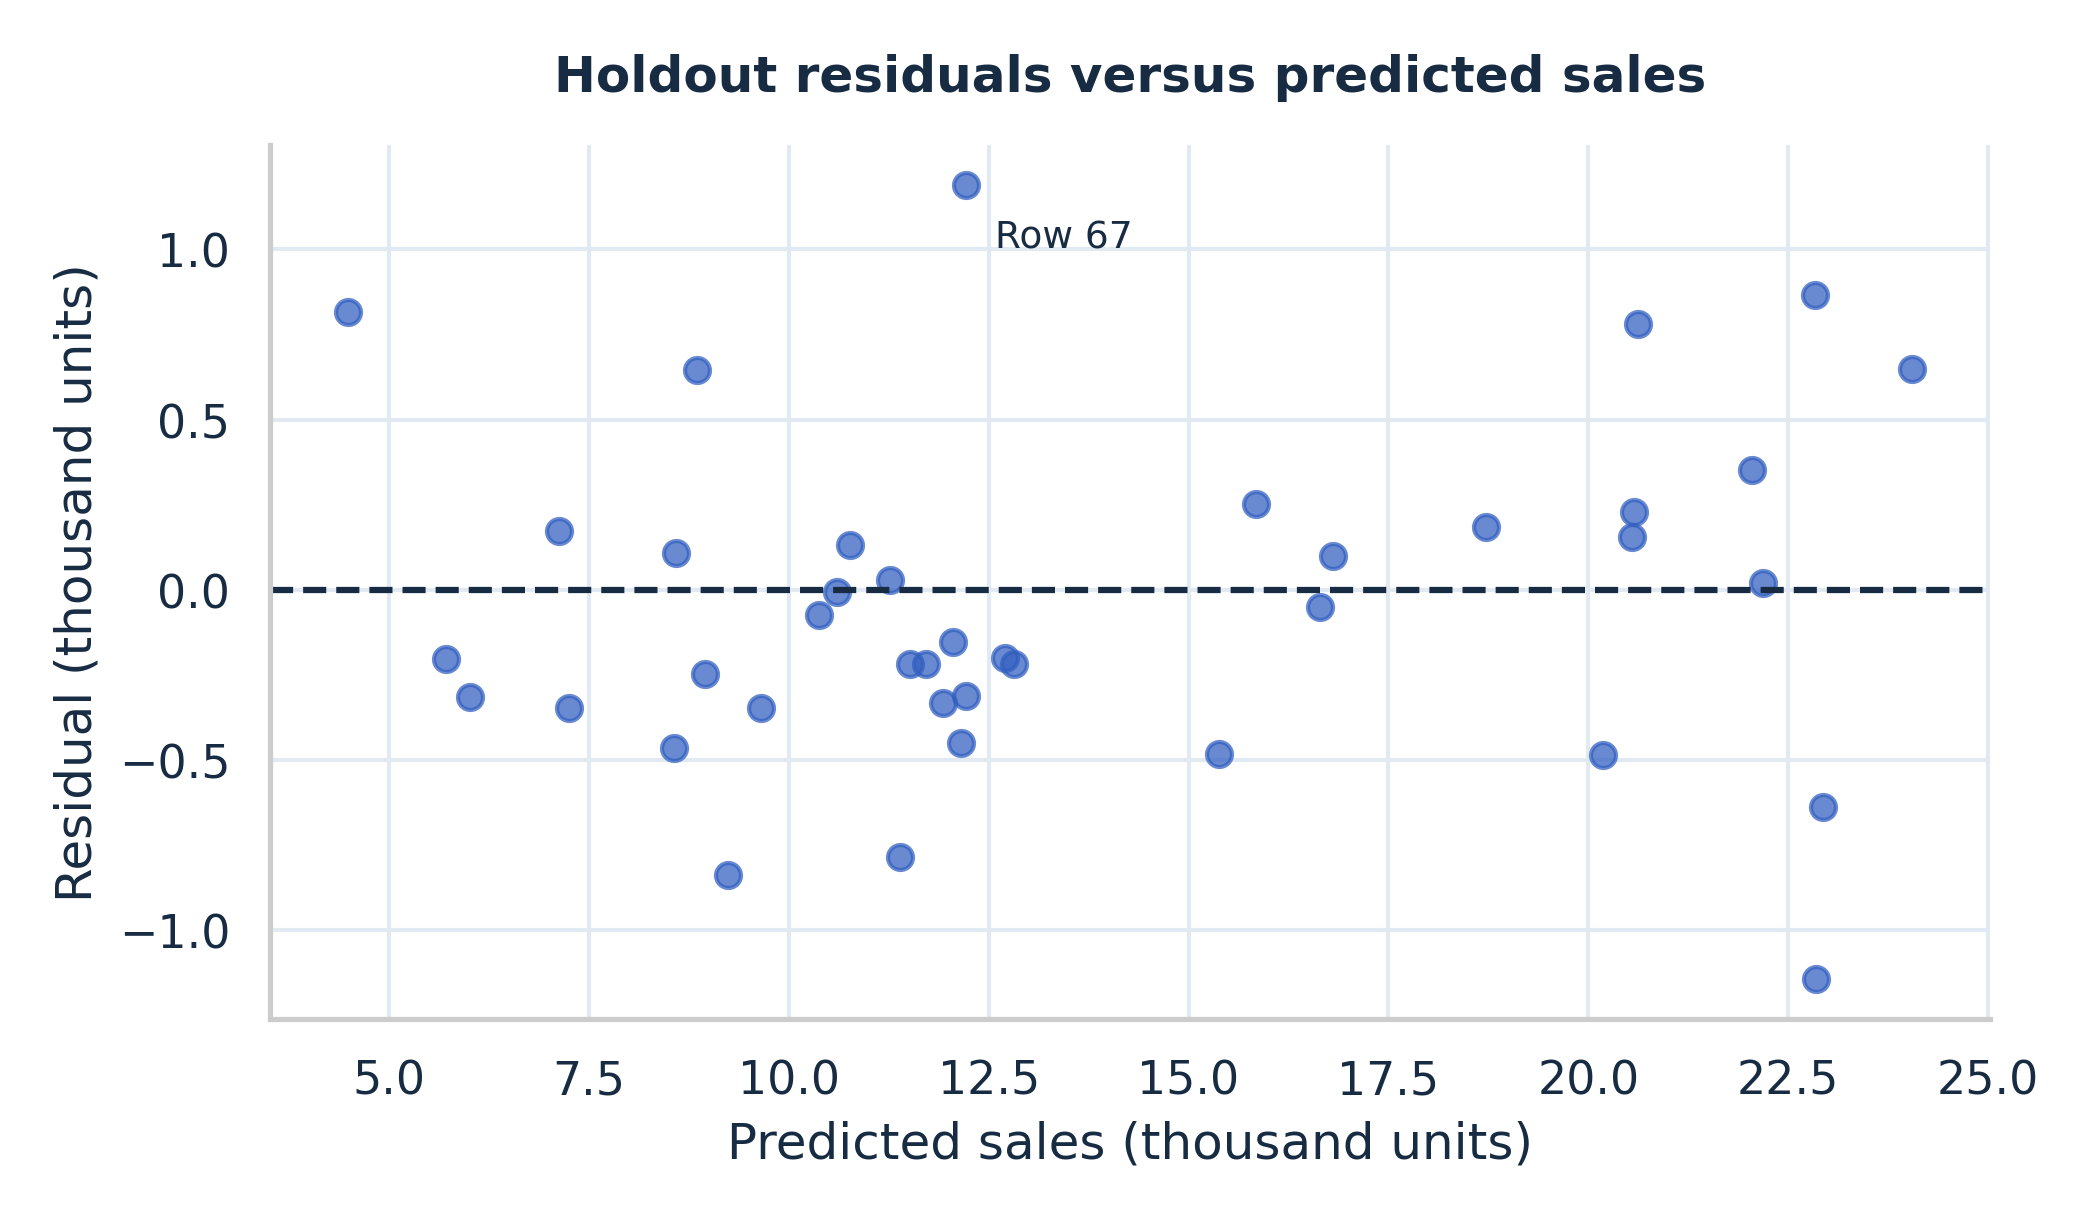

Mean holdout residual is -0.047 thousand units. Spearman correlation of residual with prediction is +0.16 (p = 0.333). The largest absolute miss is 1.19 at source row 67 (zero-based). Winner train-fold RMSE averages 0.001 versus 0.582 on validation folds. The near-zero training error shows the flexibility of the fit. Holdout RMSE (0.486) is close to validation RMSE, and the residuals show little monotone trend.

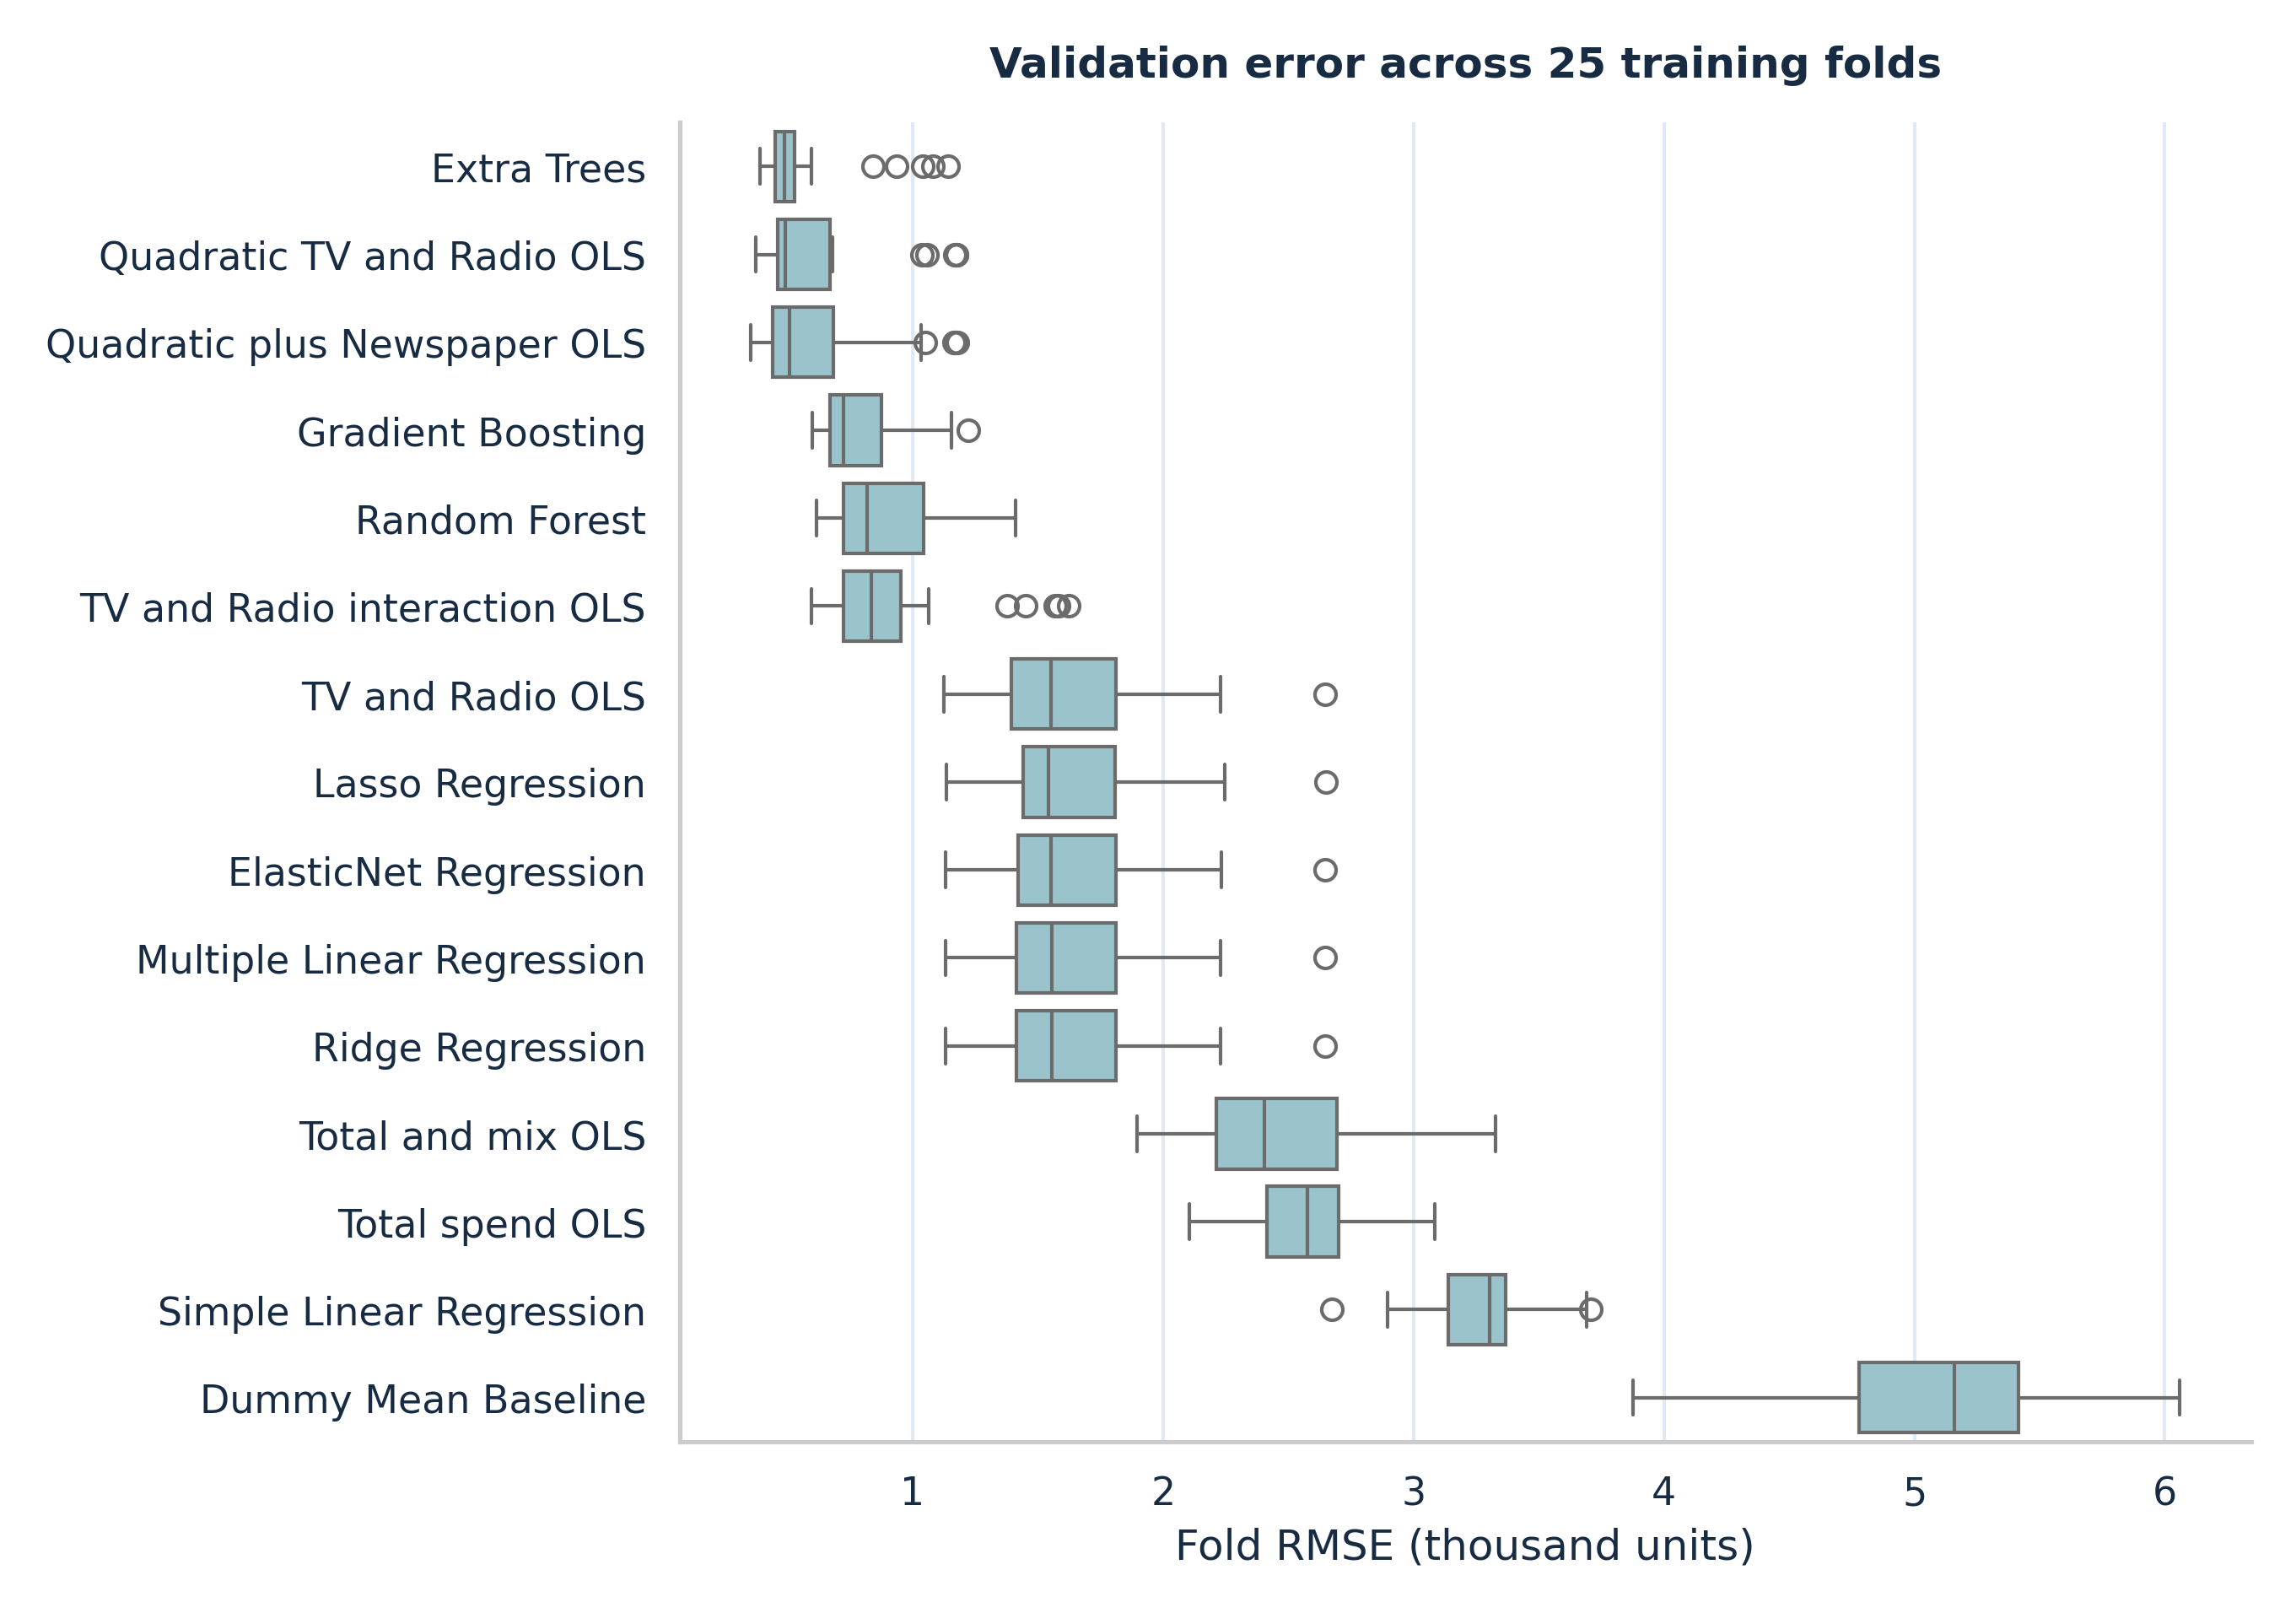

Across the shared folds, the winner averages 0.582 RMSE with fold SD 0.222. Fold SD describes stability across overlapping splits.

In [7]:
comparison = evaluate_models(ranking, fitted, X_train, y_train, X_test, y_test)
selected = comparison.iloc[0]
saved = joblib.load(root / 'models' / 'best_sales_model.joblib')
np.testing.assert_allclose(saved.predict(X_test), fitted[selected['model']].predict(X_test))
test = holdout_predictions(saved, X_test, y_test)
importance, diagnostics = diagnose_predictions(saved, X_test, y_test, test)
display(comparison[['model', 'train_adjusted_r2_ols', 'test_mae', 'test_mse',
                    'test_rmse', 'test_r2']].round(4))
display(test.head().round(3), diagnostics.round(4), importance.round(4))
charts('actual_vs_predicted', 'residual_distribution', 'residuals_vs_predicted',
       'cross_validation_stability')

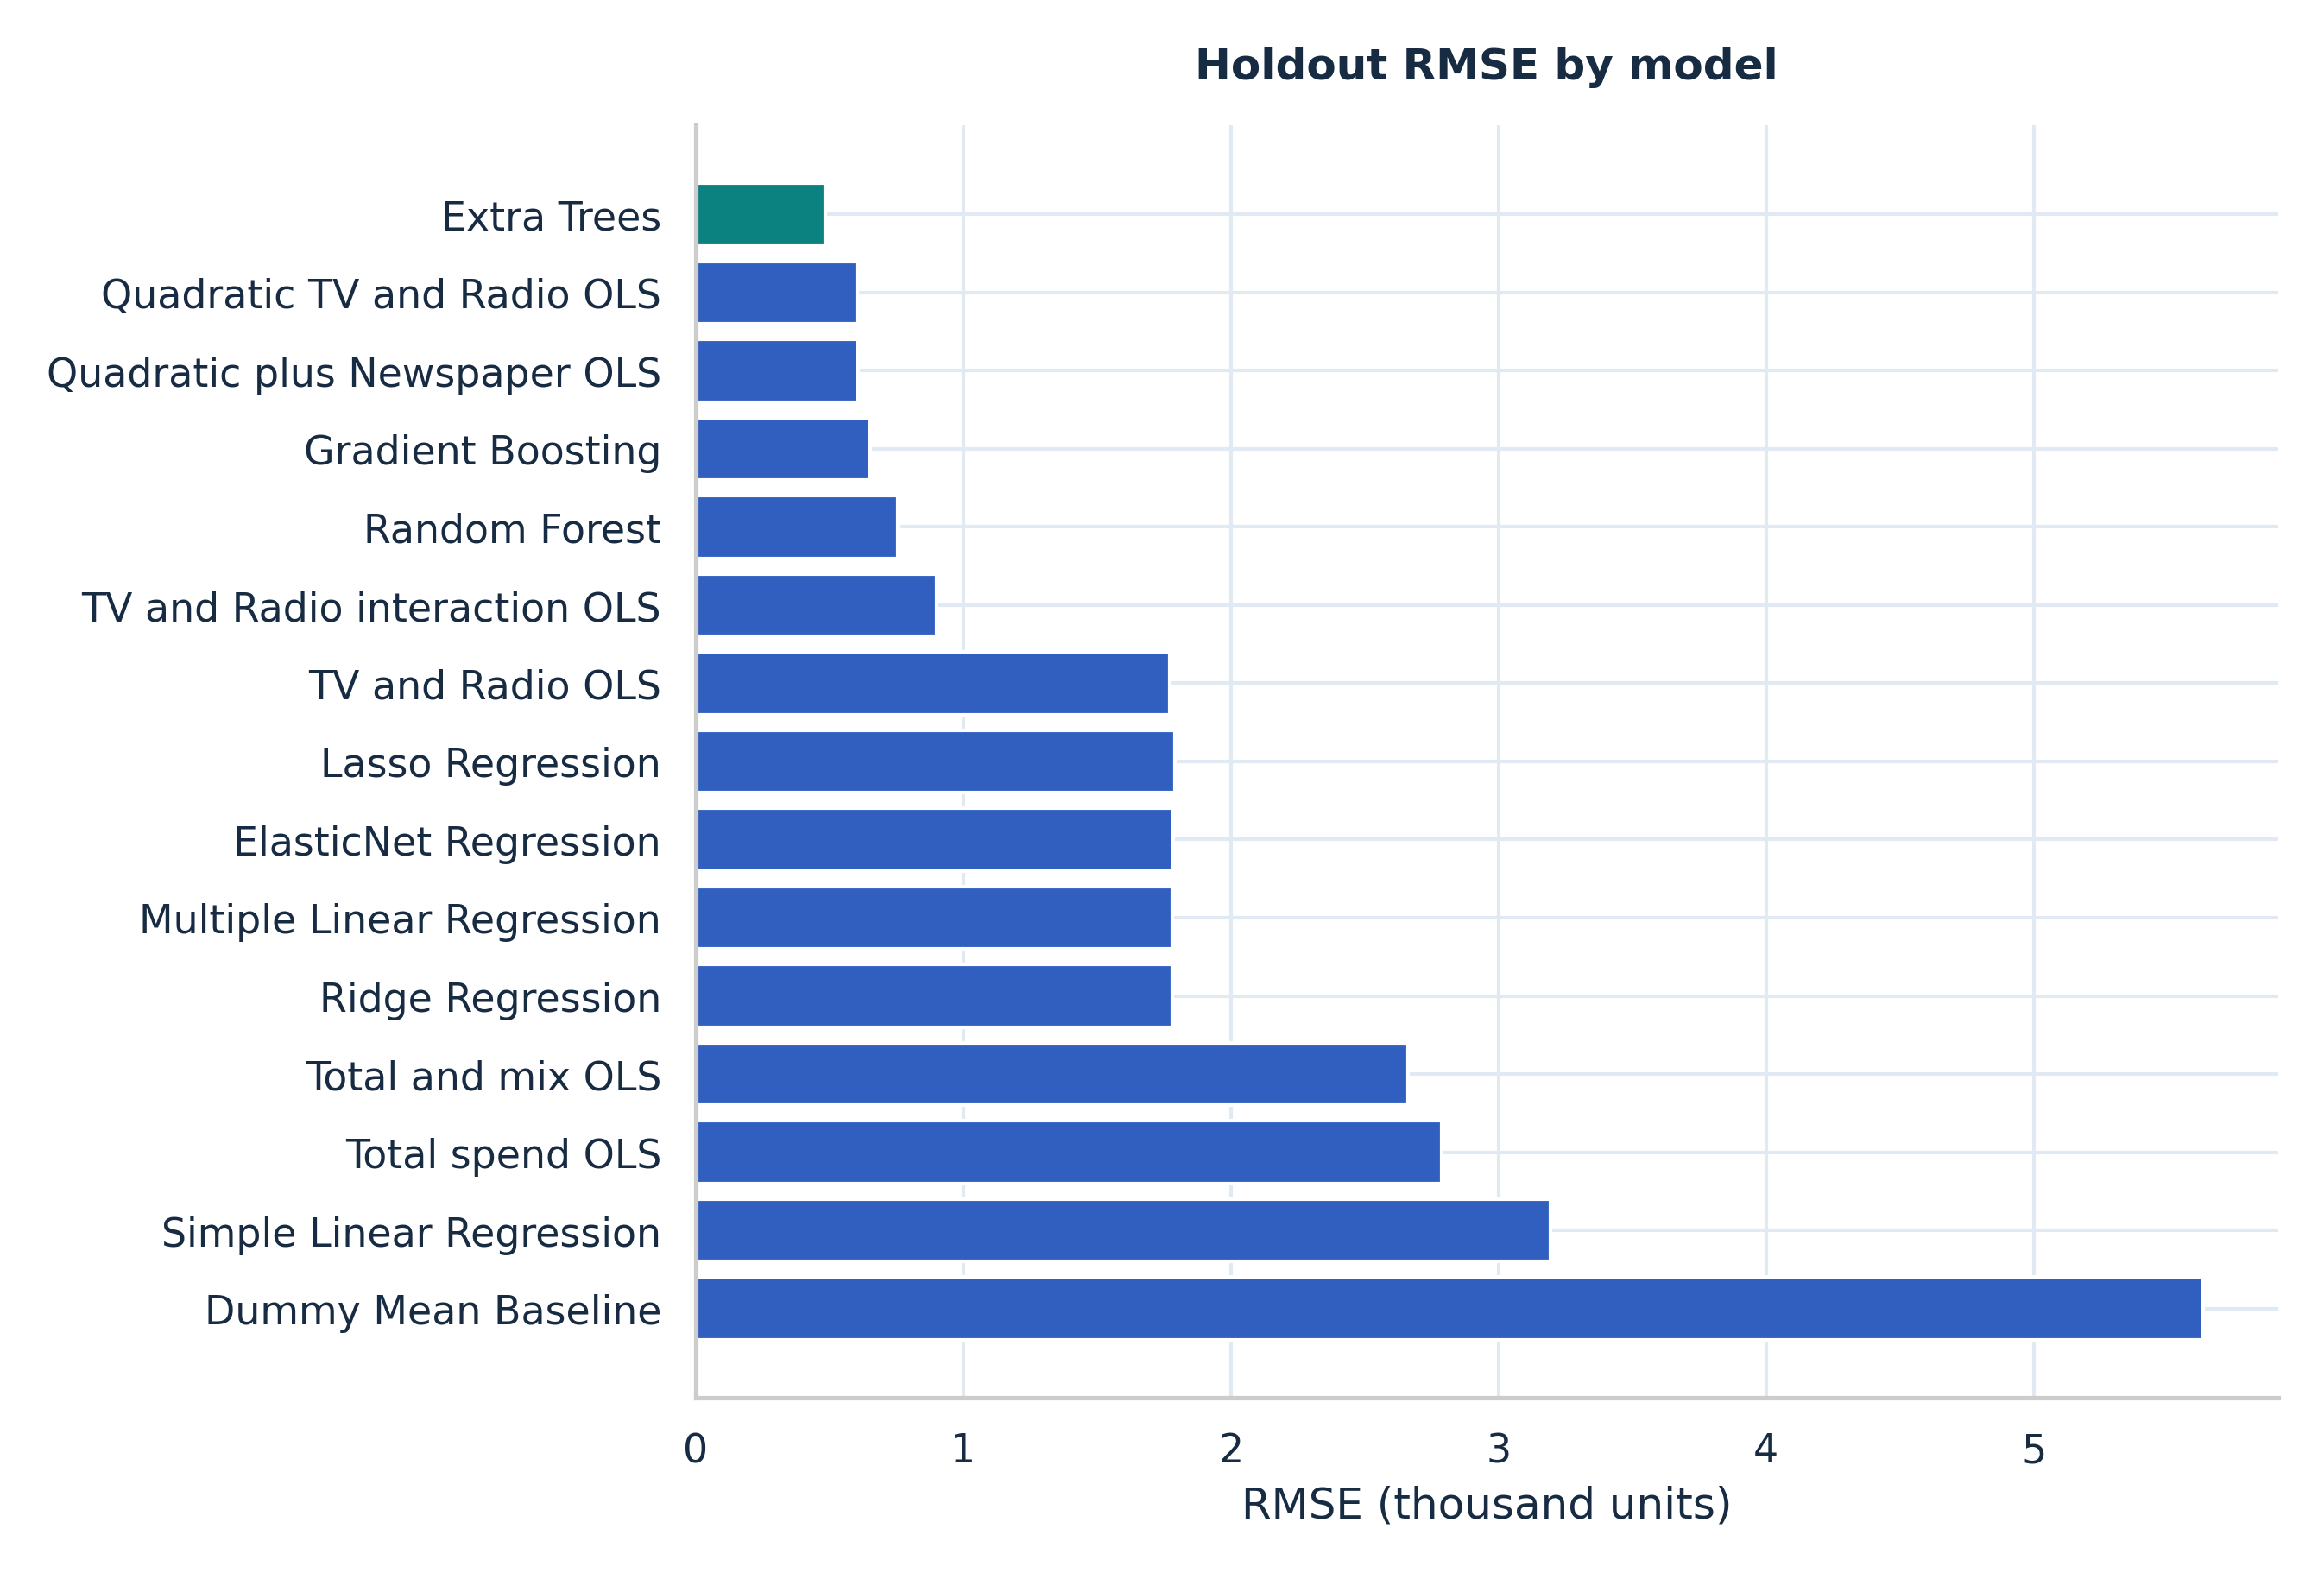

The selected model’s holdout RMSE is 0.486. The teal bar identifies the training-CV winner in all comparison charts.

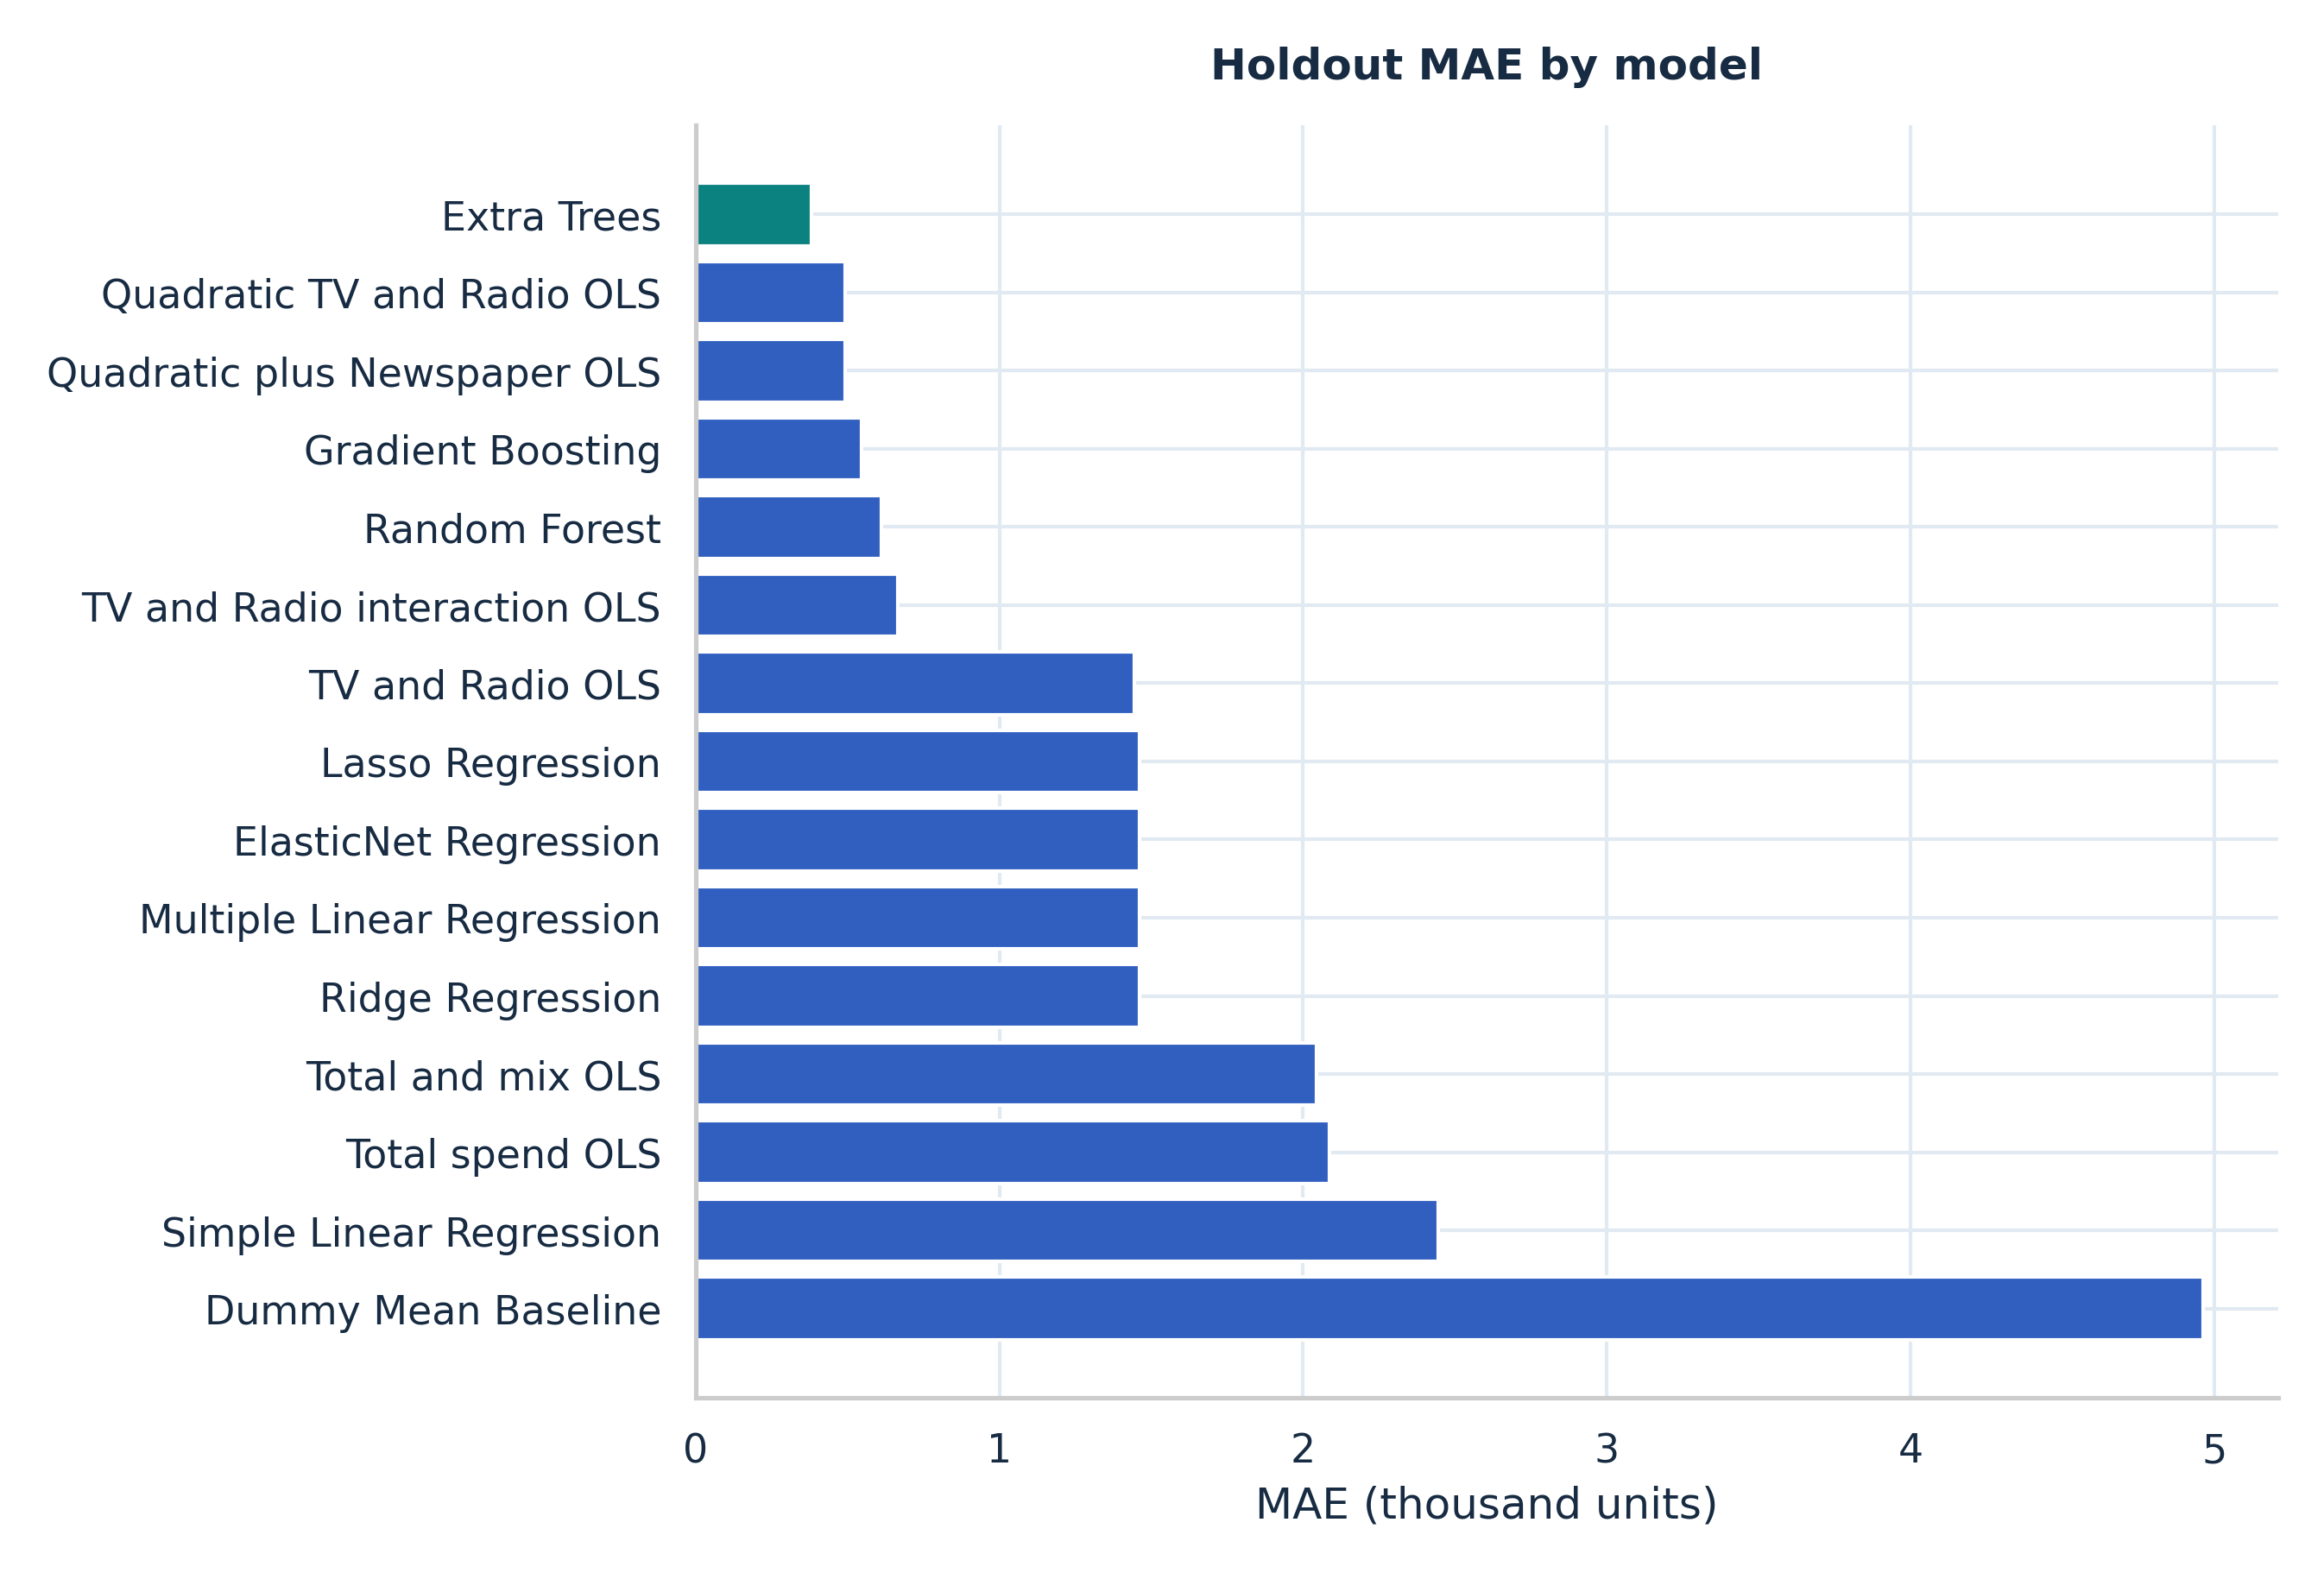

The selected model’s mean absolute holdout error is 0.381 thousand units.

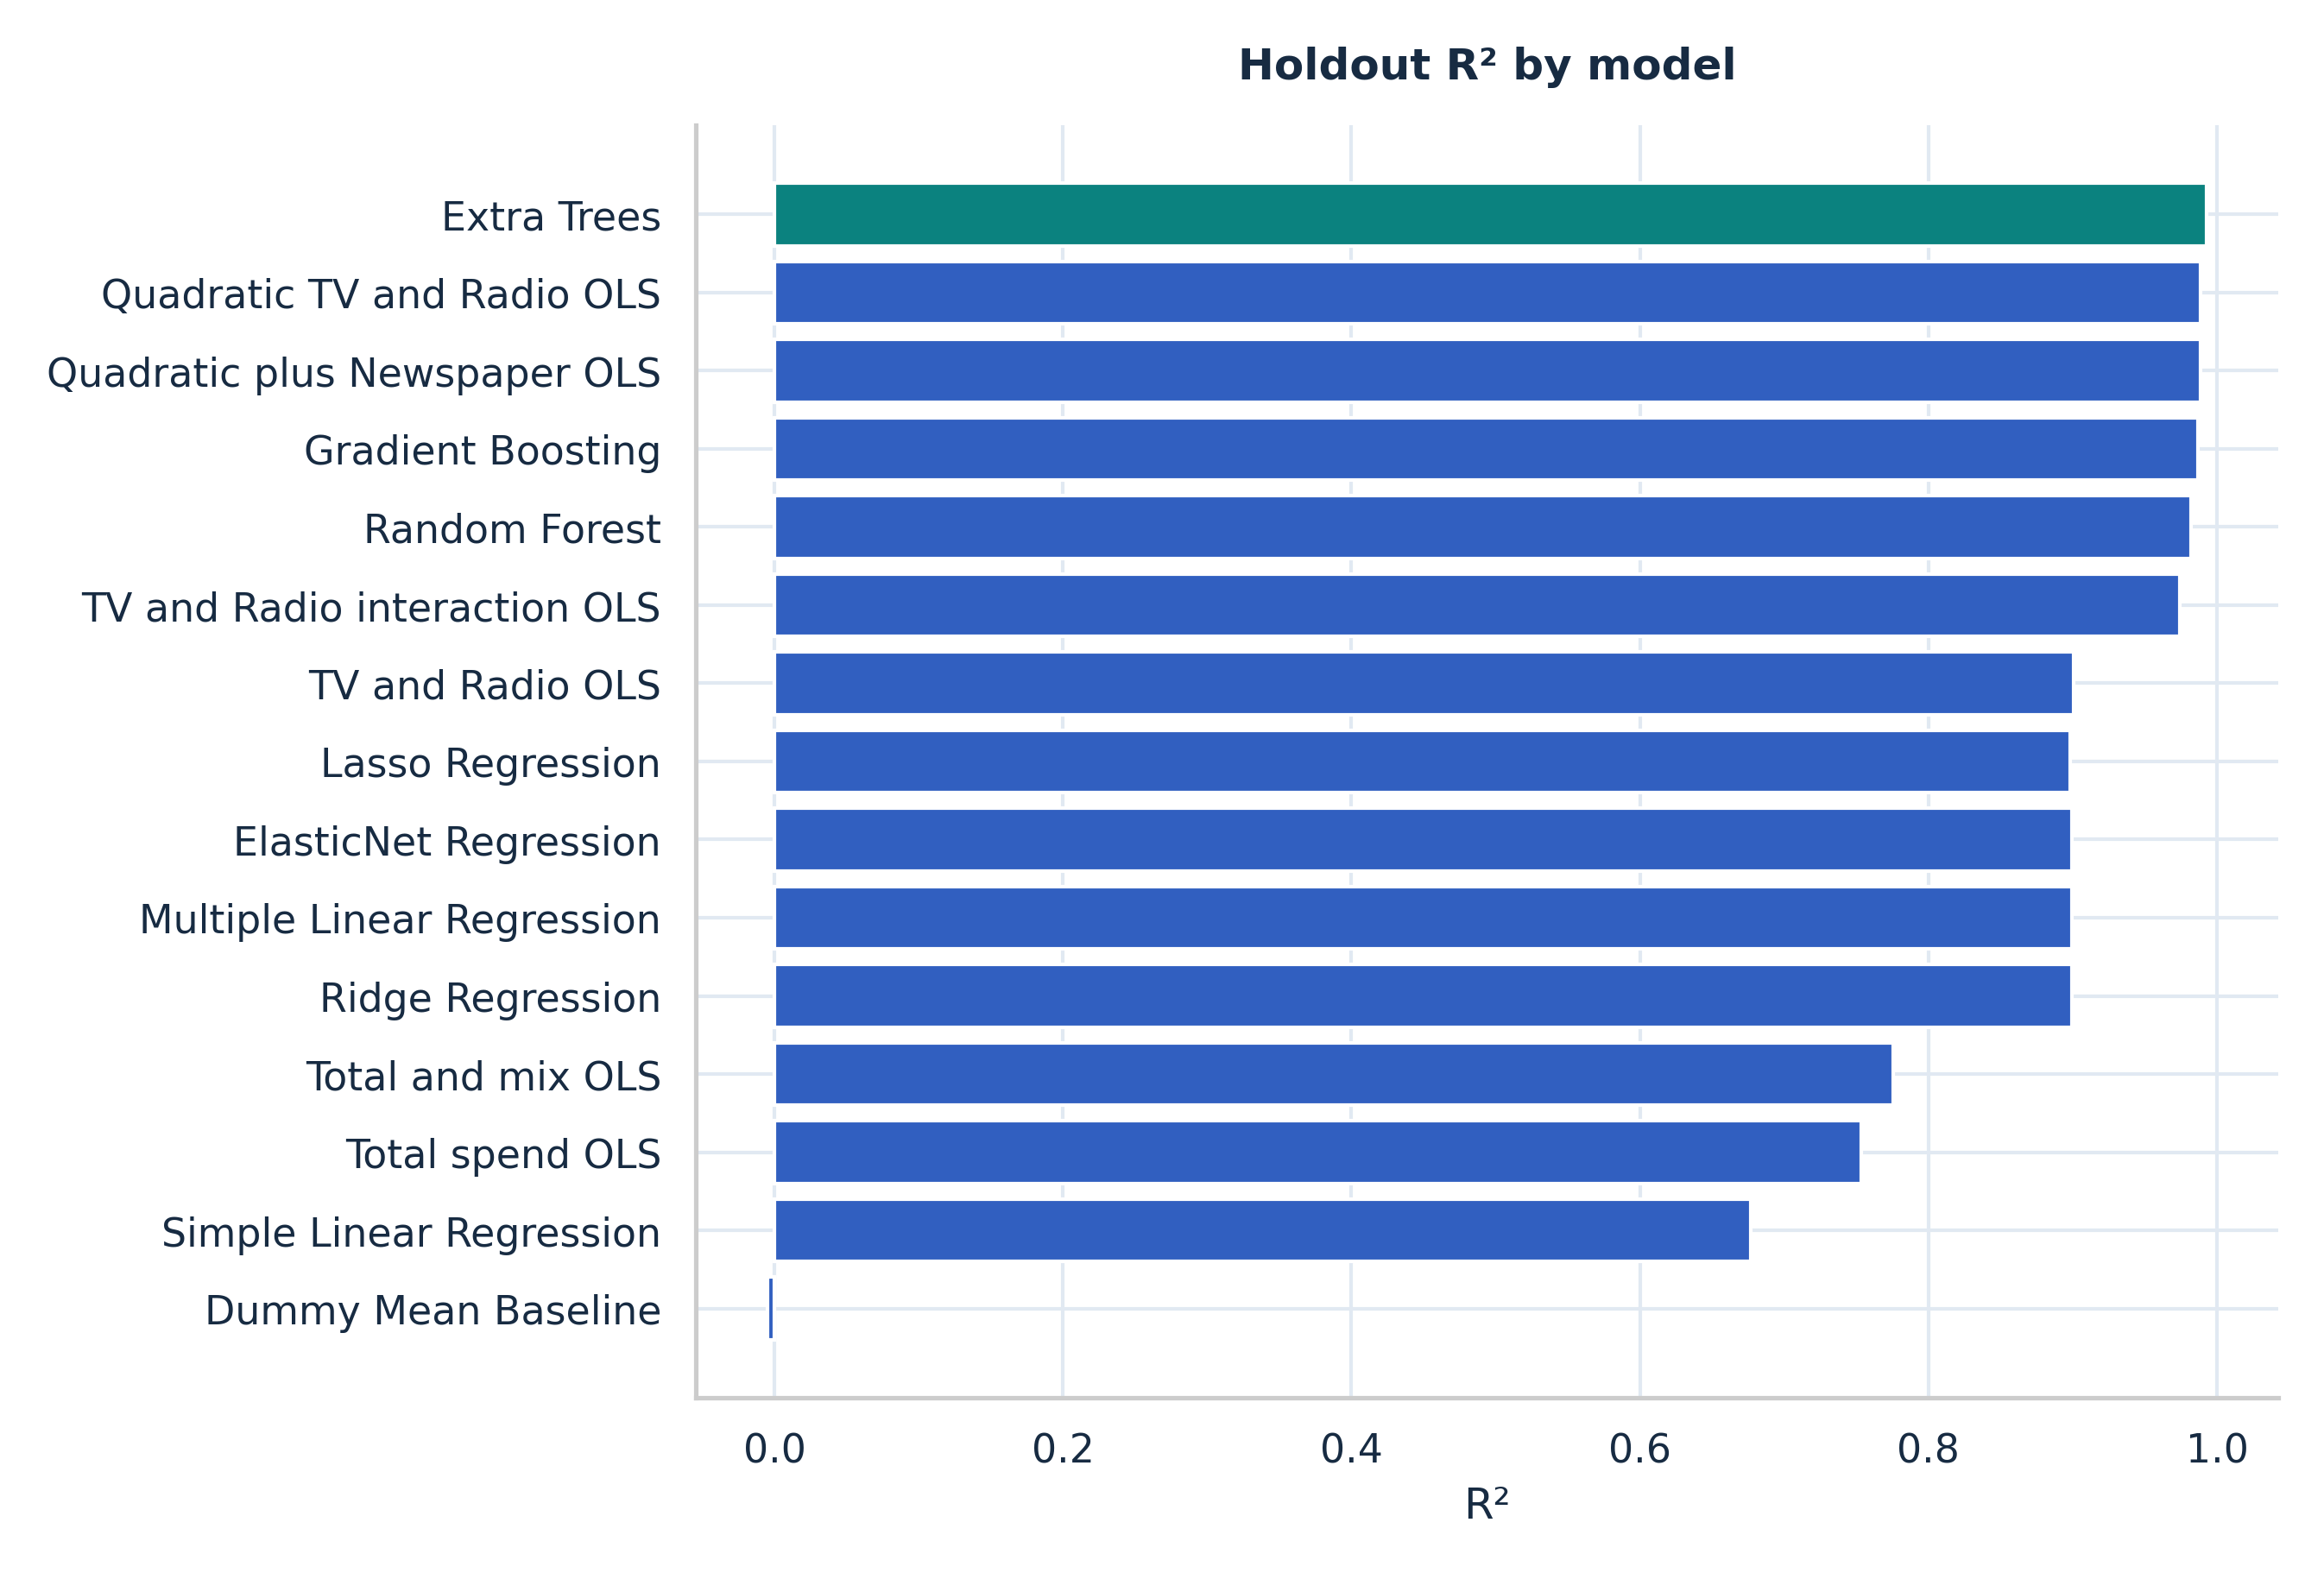

The selected model has holdout R² of 0.993. Negative scores indicate squared error greater than predicting the holdout mean.

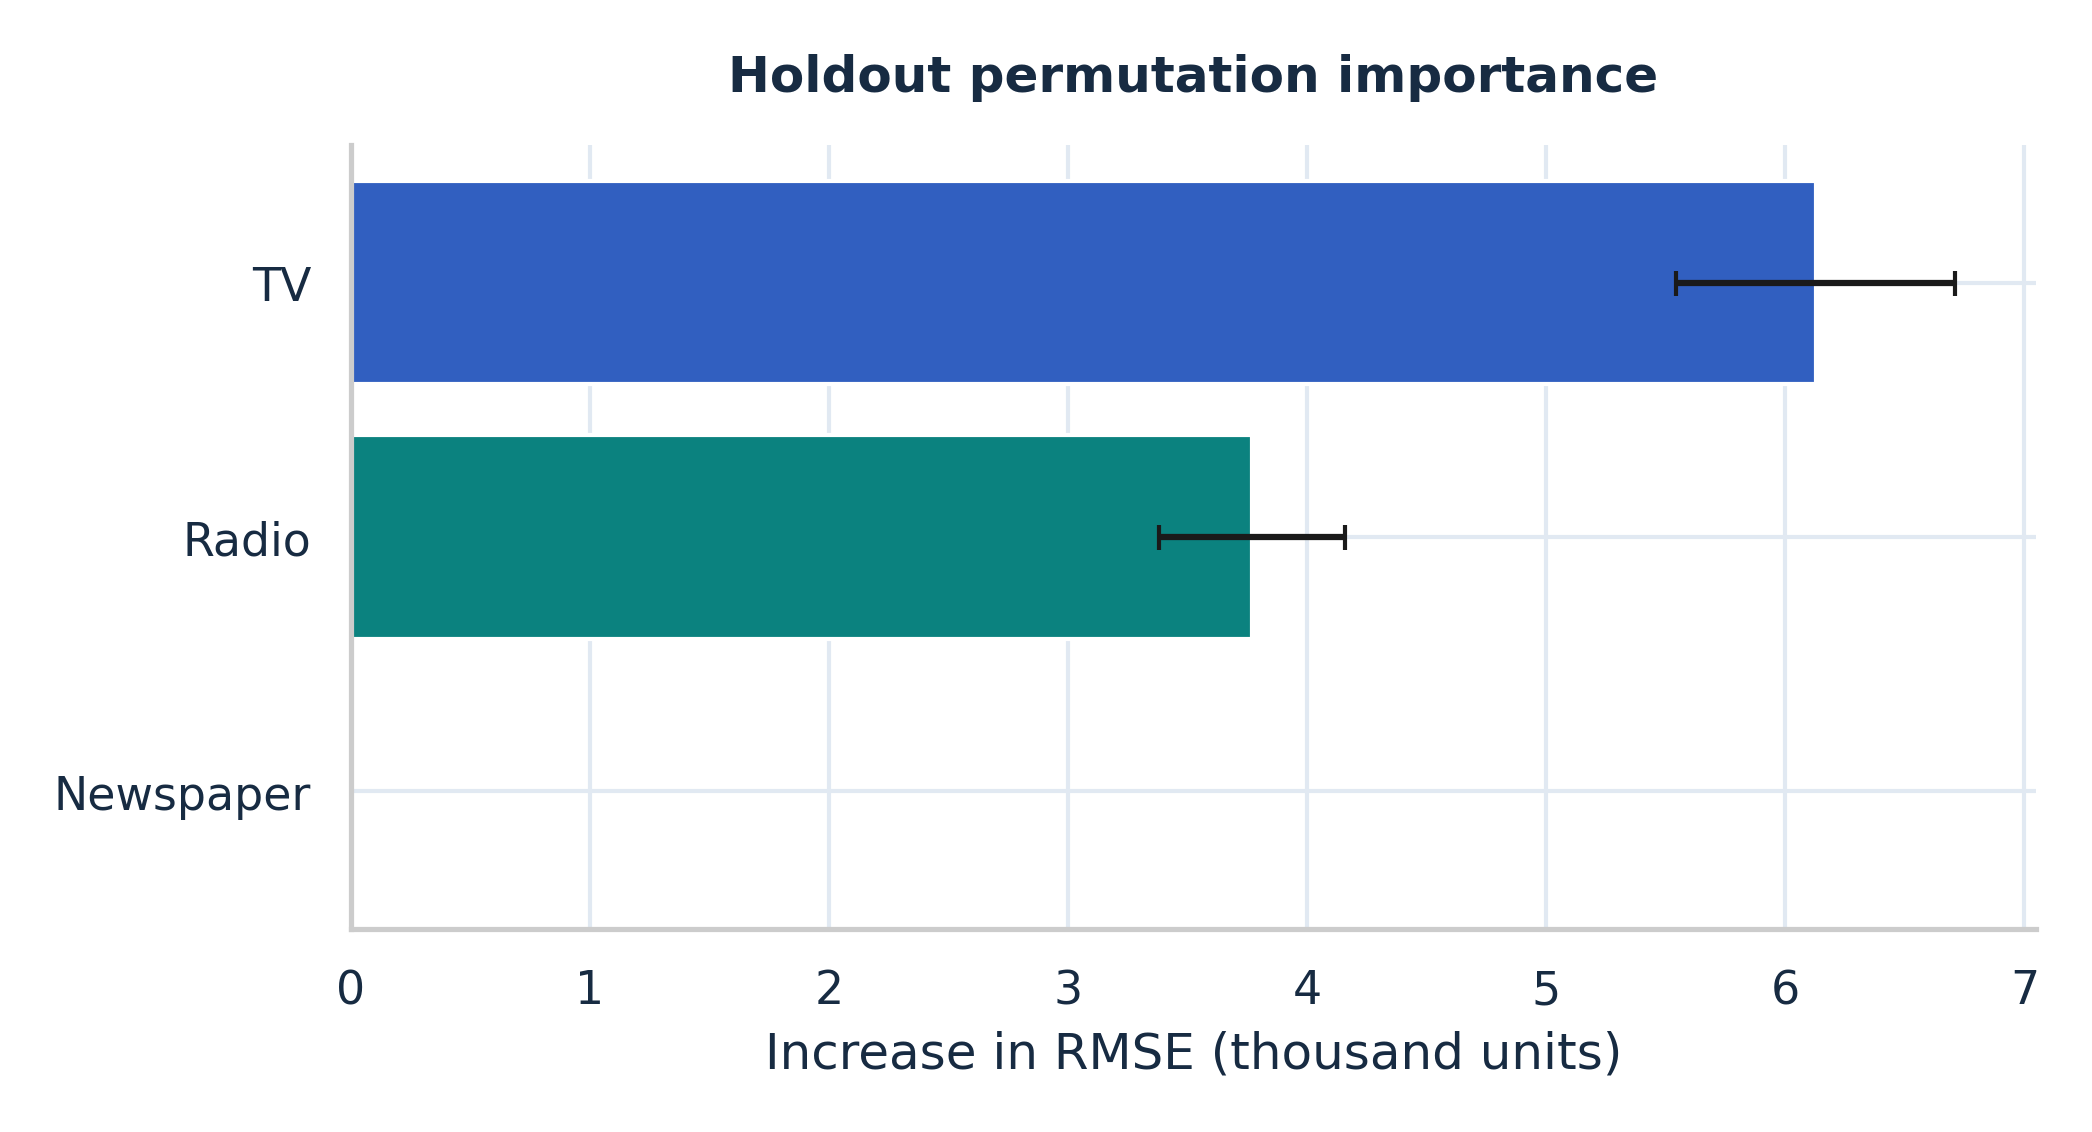

Shuffling TV produces the largest mean increase in holdout RMSE. Error bars show shuffle-to-shuffle SD.

In [8]:
charts('model_rmse_comparison', 'model_mae_comparison', 'model_r2_comparison', 'permutation_importance')

## 8. Advertising effectiveness
The explanatory model is separate from the selected prediction pipeline. It fits all three channel budgets on the training split. The unstandardized slope compares a one-thousand-dollar budget increase with the other channels fixed. A standardized slope compares a one-standard-deviation increase. HC3 intervals and p-values account for unequal residual variance. VIF describes how the other budgets inflate the variance of each slope.

,term,coefficient,hc3_std_error,p_value,ci_95_low,ci_95_high,standardized_coefficient,vif,sales_change_per_10_budget_units
0,const,2.97907,0.39692,0.00000,2.20111,3.75702,NaN,NaN,NaN
1,TV,0.04473,0.00233,0.00000,0.04016,0.04930,0.73913,1.00291,0.44730
2,Radio,0.18920,0.01303,0.00000,0.16366,0.21473,0.54829,1.18031,1.89195
3,Newspaper,0.00276,0.00833,0.74017,-0.01356,0.01908,0.01099,1.17731,0.02761


,r2,adjusted_r2,hc3_f_statistic,hc3_f_p_value,n
0,0.8957,0.8937,474.4952,0.0,160


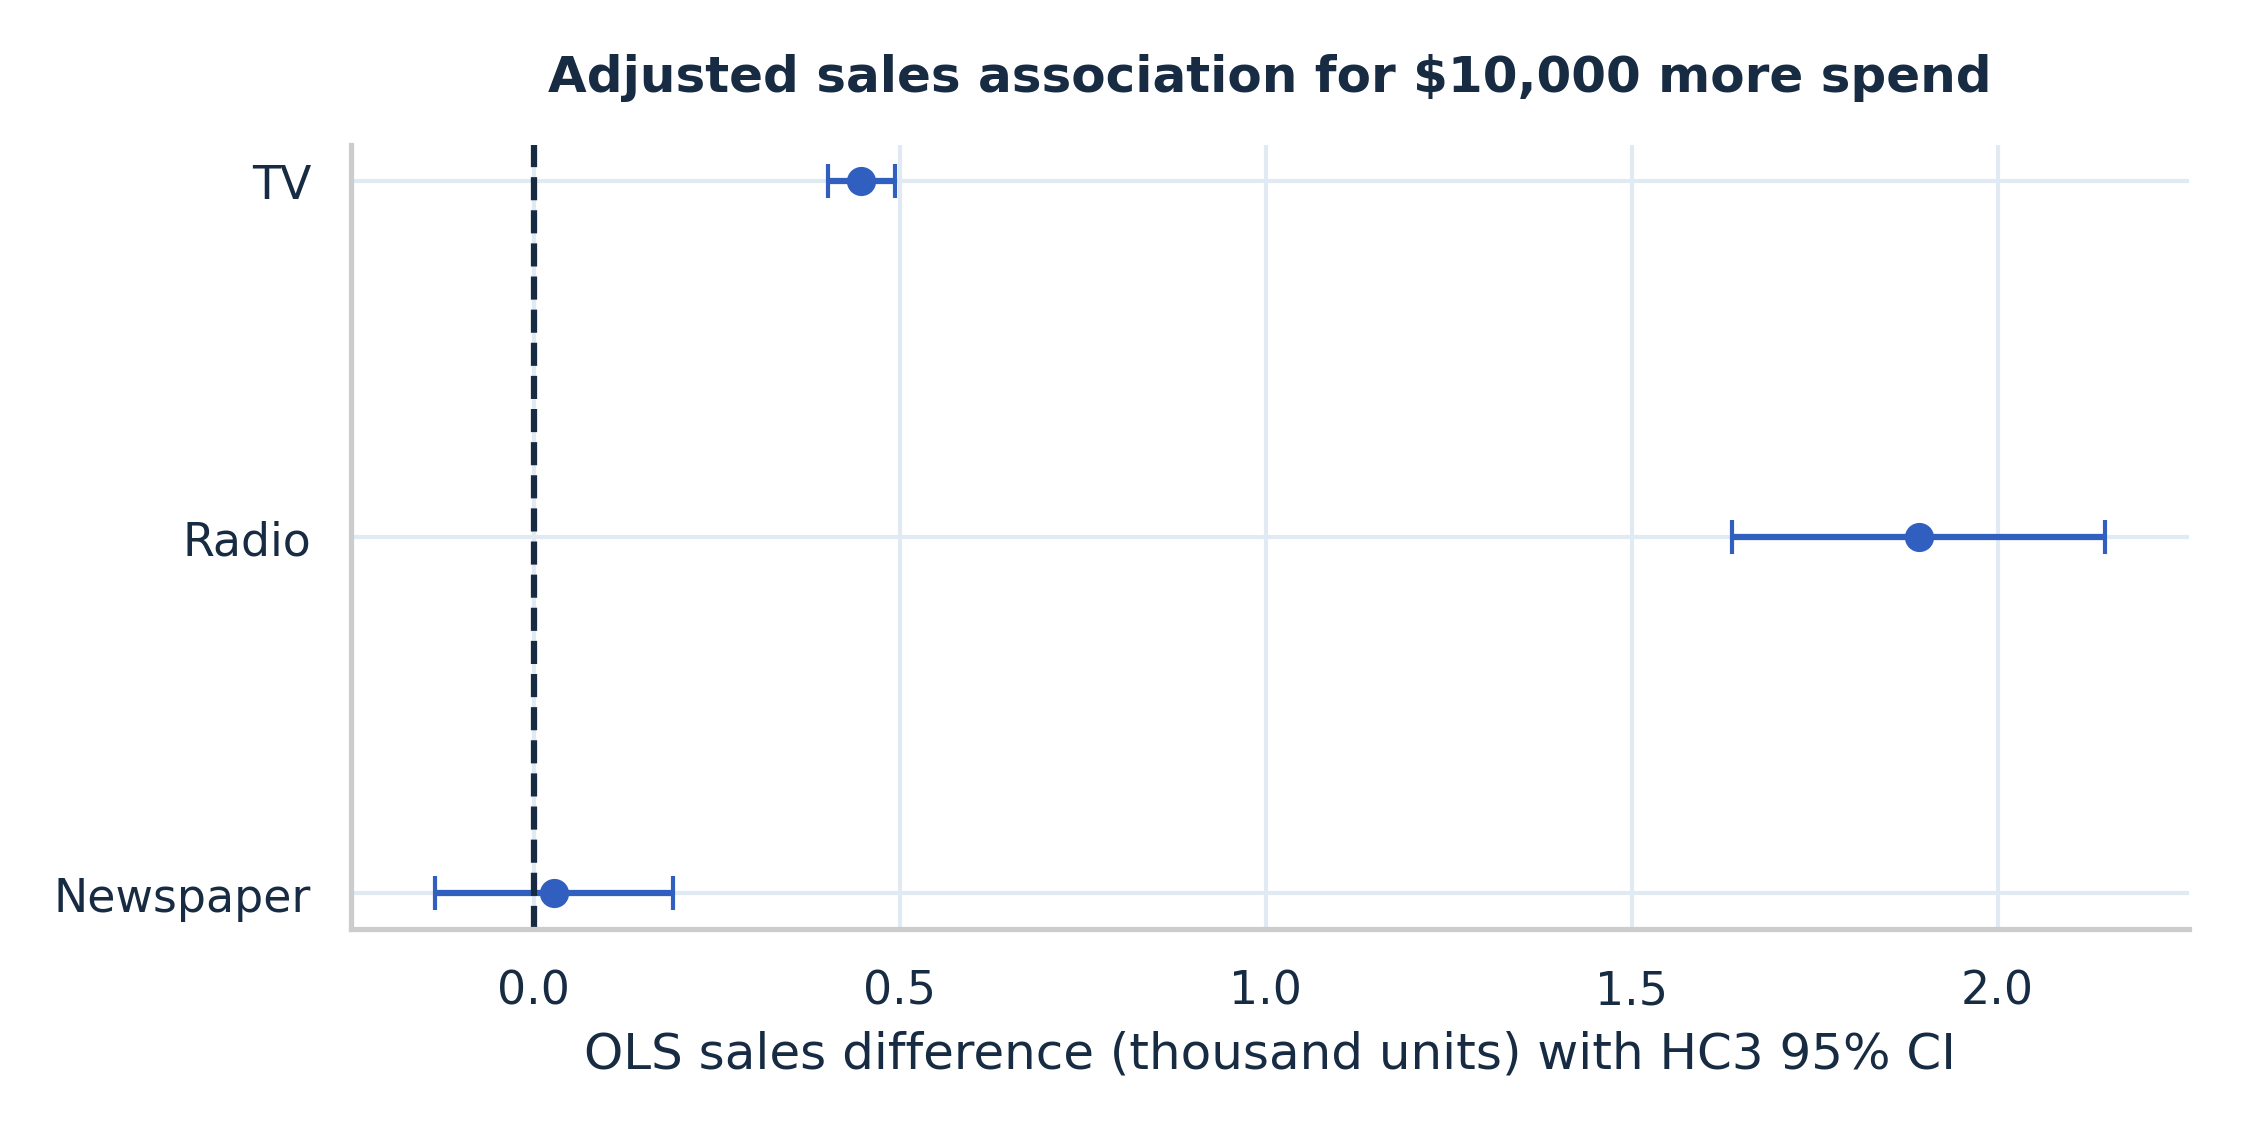

TV has the largest absolute standardized coefficient. Newspaper has the smallest, and its HC3 95% interval (-0.014 to 0.019) includes zero. The largest holdout permutation effect belongs to TV.

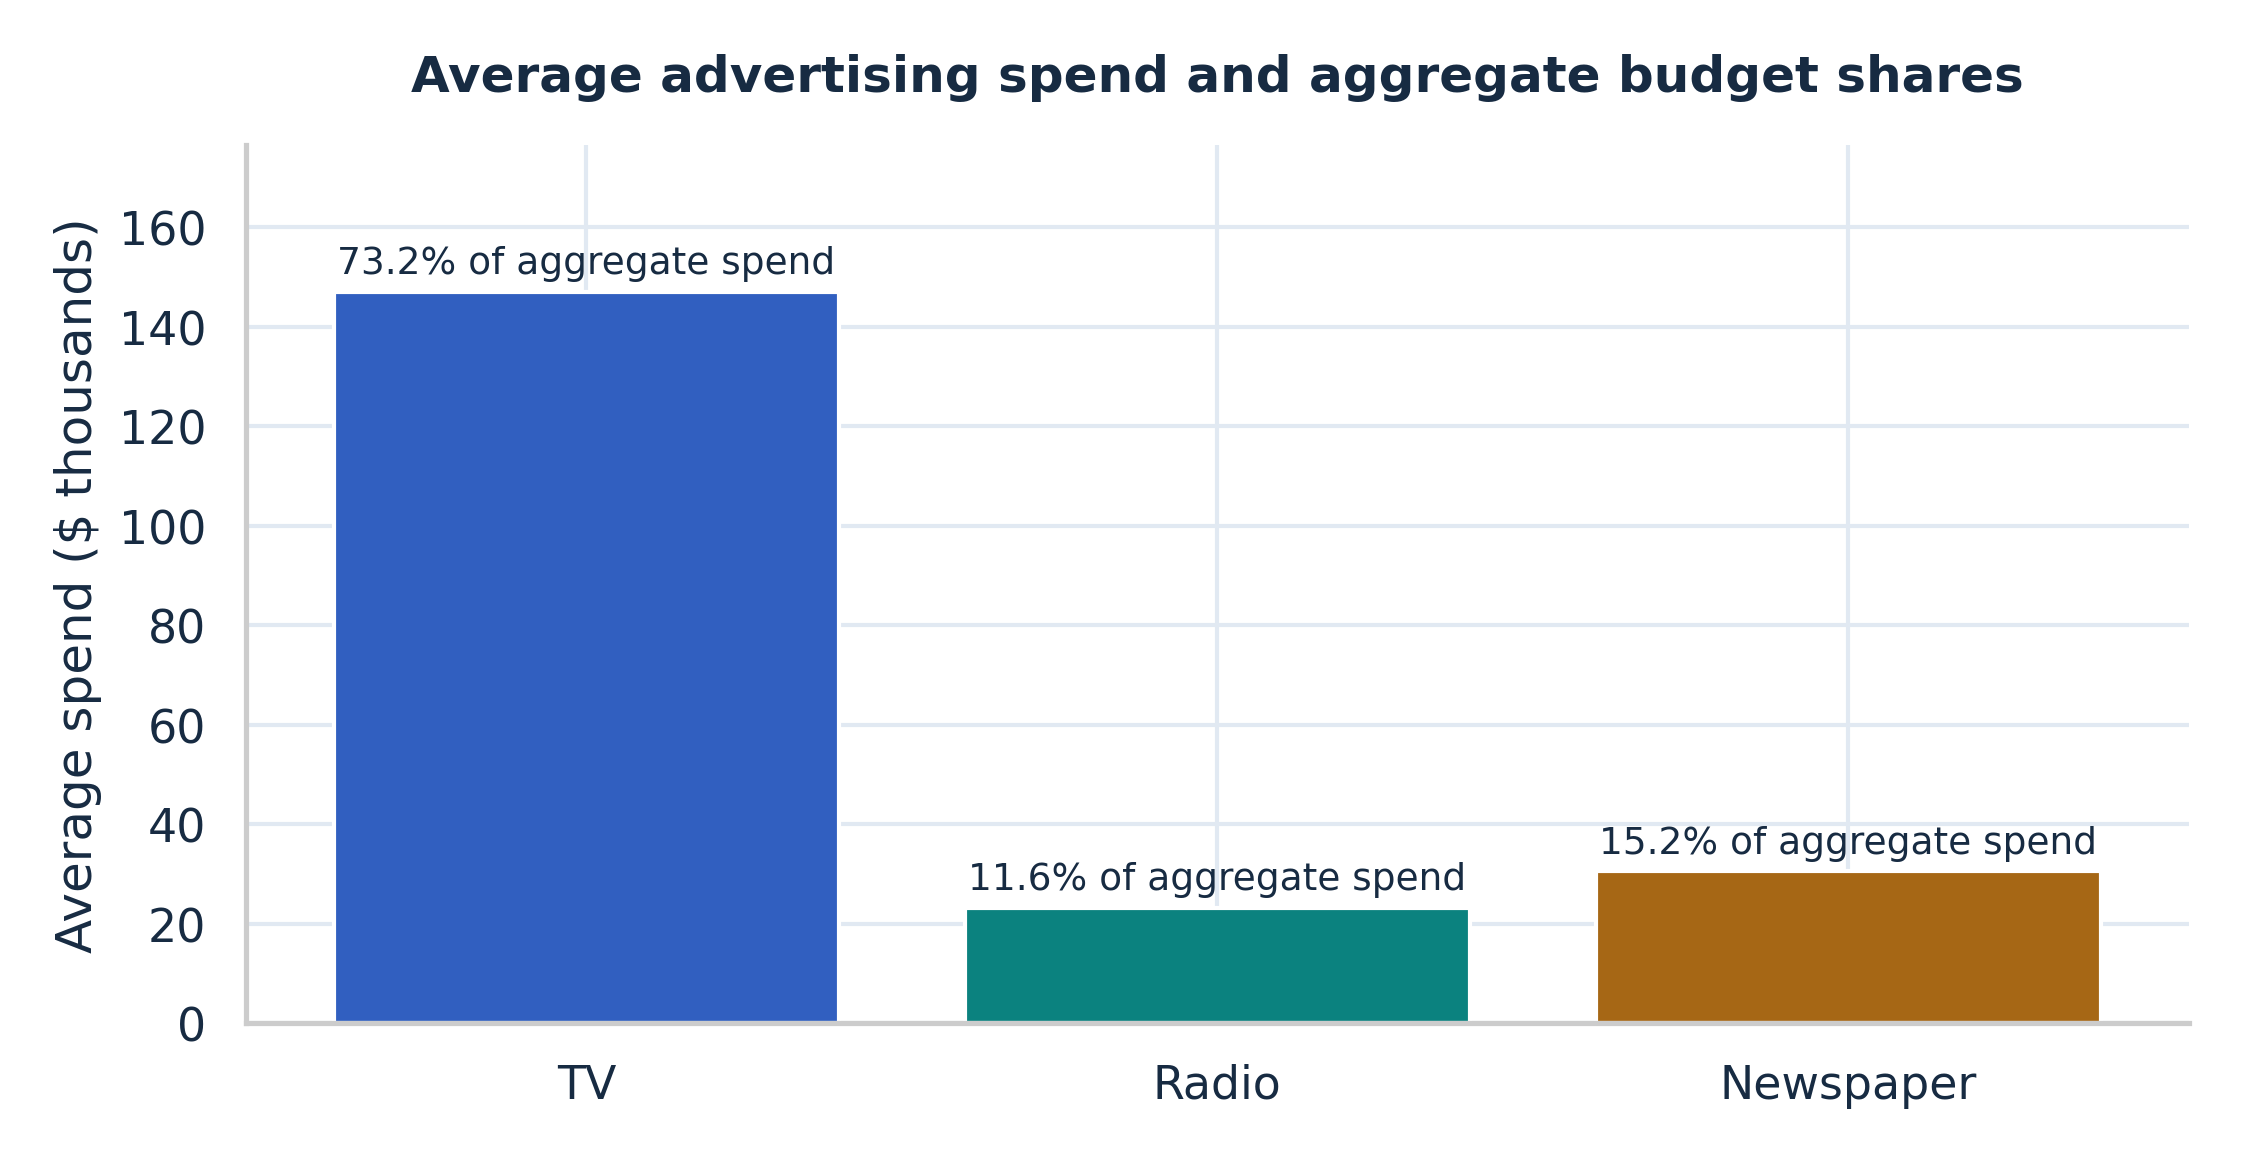

TV accounts for 73.2% of aggregate spend. Shares compare total spending across channels, giving larger markets more weight.

In [9]:
coefficients, ols_fit = analyze_channels(X_train, y_train)
display(coefficients.round(5), ols_fit.round(4))
charts('channel_marginal_effects', 'spend_mix')

## 9. Scenario-based sales prediction
Use the training medians as the baseline. The scenarios include individual increases, combined increases and two constant-budget transfers. Channel ranges flag extrapolation. A nearest-neighbor rule in range-scaled budget space flags unusual mixes within those ranges. The response surface keeps Newspaper at its training median and shades out sparsely supported mixes.

,Scenario,TV,Radio,Newspaper,Total,Predicted_Sales,Sales_Change,Inside_Training_Range,Training_Mix_Supported
0,Training median baseline,150.650,21.20,25.60,197.450,14.374,0.000,True,True
1,TV +10%,165.715,21.20,25.60,212.515,14.642,0.267,True,True
2,TV +20%,180.780,21.20,25.60,227.580,15.342,0.968,True,True
3,Radio +10%,150.650,23.32,25.60,199.570,14.796,0.422,True,True
4,Radio +20%,150.650,25.44,25.60,201.690,15.163,0.789,True,True
5,Newspaper +10%,150.650,21.20,28.16,200.010,14.374,0.000,True,True
6,Newspaper +20%,150.650,21.20,30.72,202.570,14.374,0.000,True,True
7,All channels +10%,165.715,23.32,28.16,217.195,15.148,0.774,True,True
8,TV and Radio +10%,165.715,23.32,25.60,214.635,15.148,0.774,True,True
9,Move 20% of Newspaper to TV,155.770,21.20,20.48,197.450,14.488,0.114,True,True


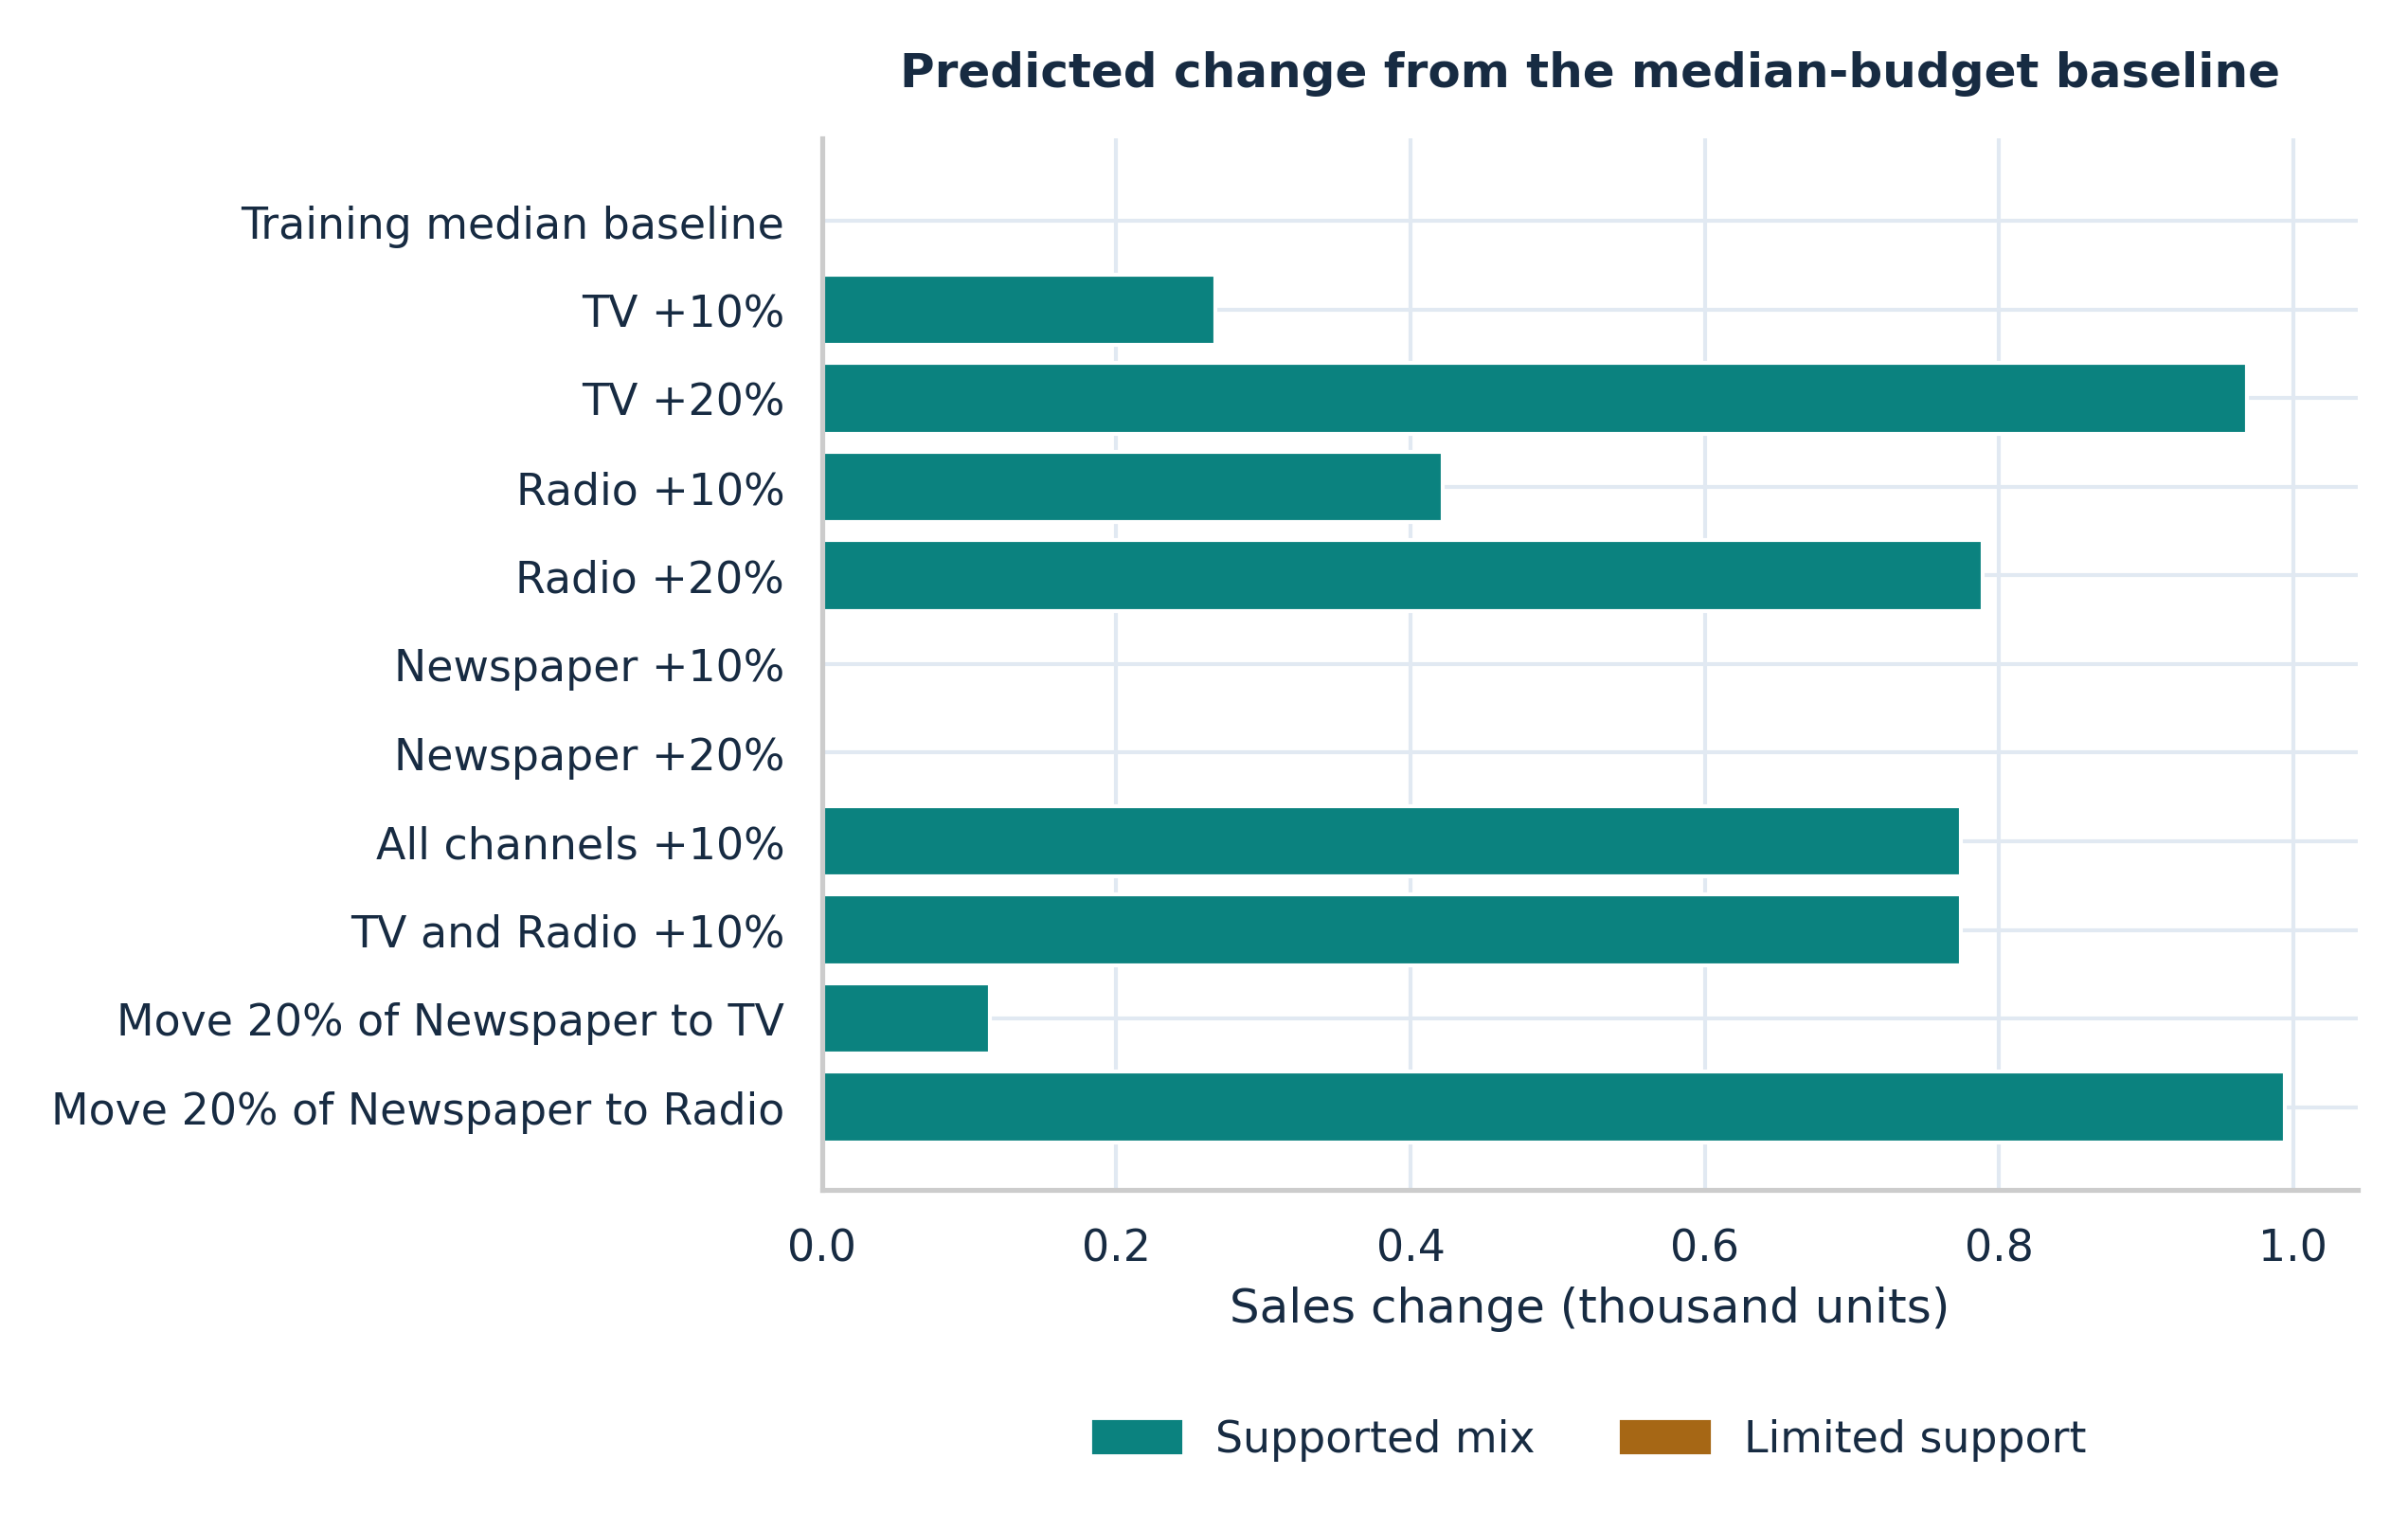

Among supported examples, Move 20% of Newspaper to Radio has the largest predicted change (+0.99 thousand units).

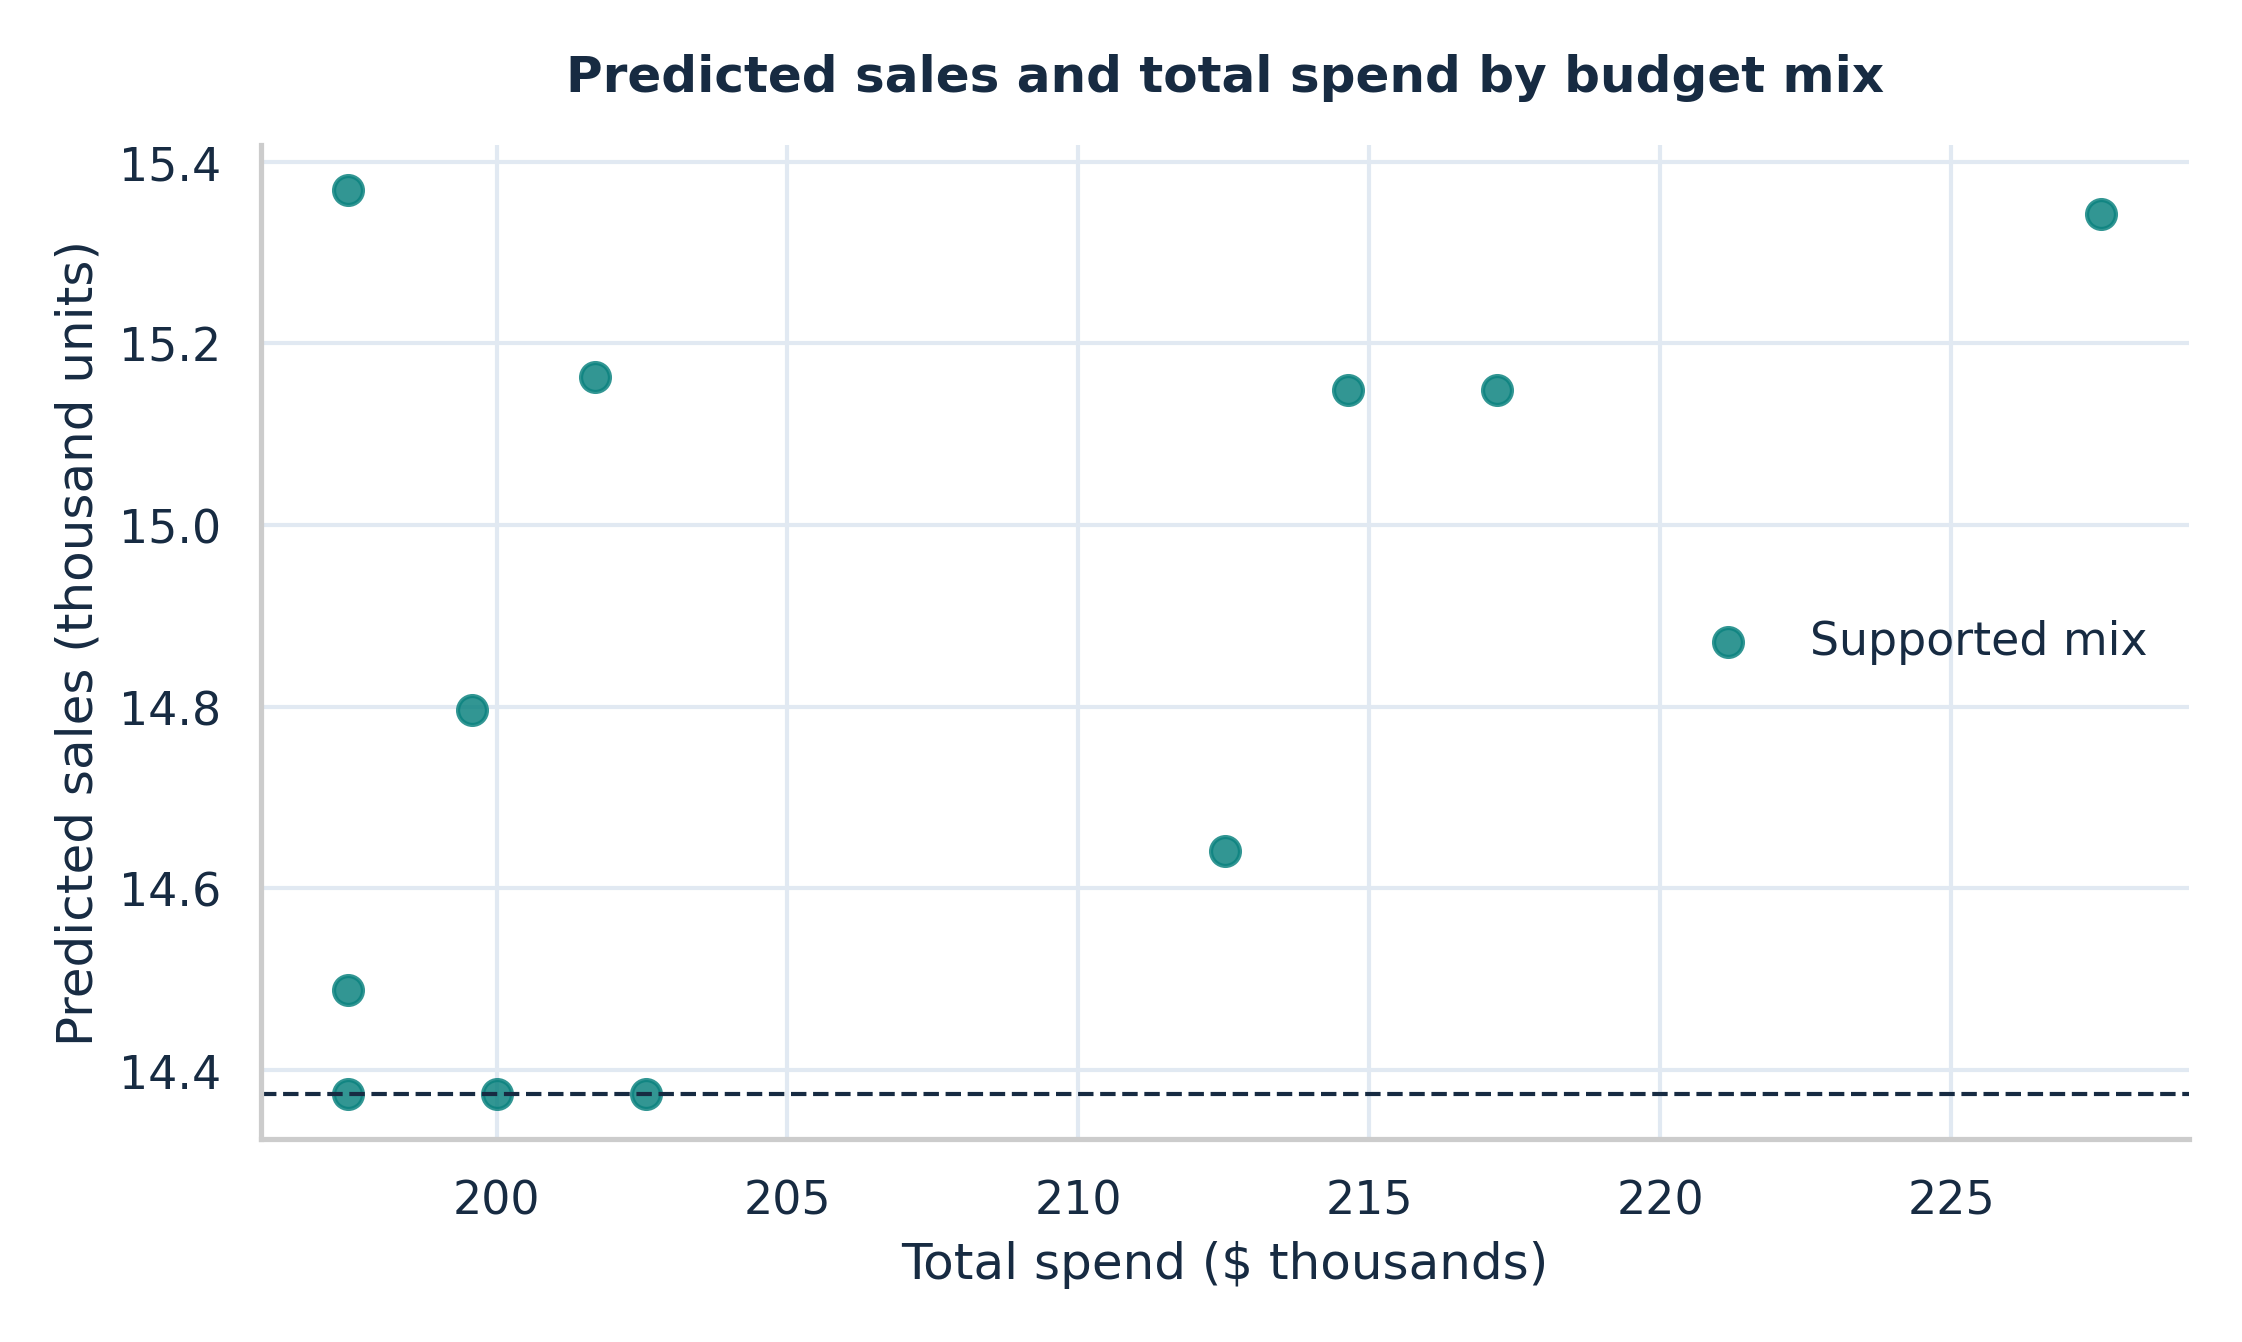

The larger predicted change among the two tested same-cost reallocations is +0.99 thousand units (Move 20% of Newspaper to Radio).

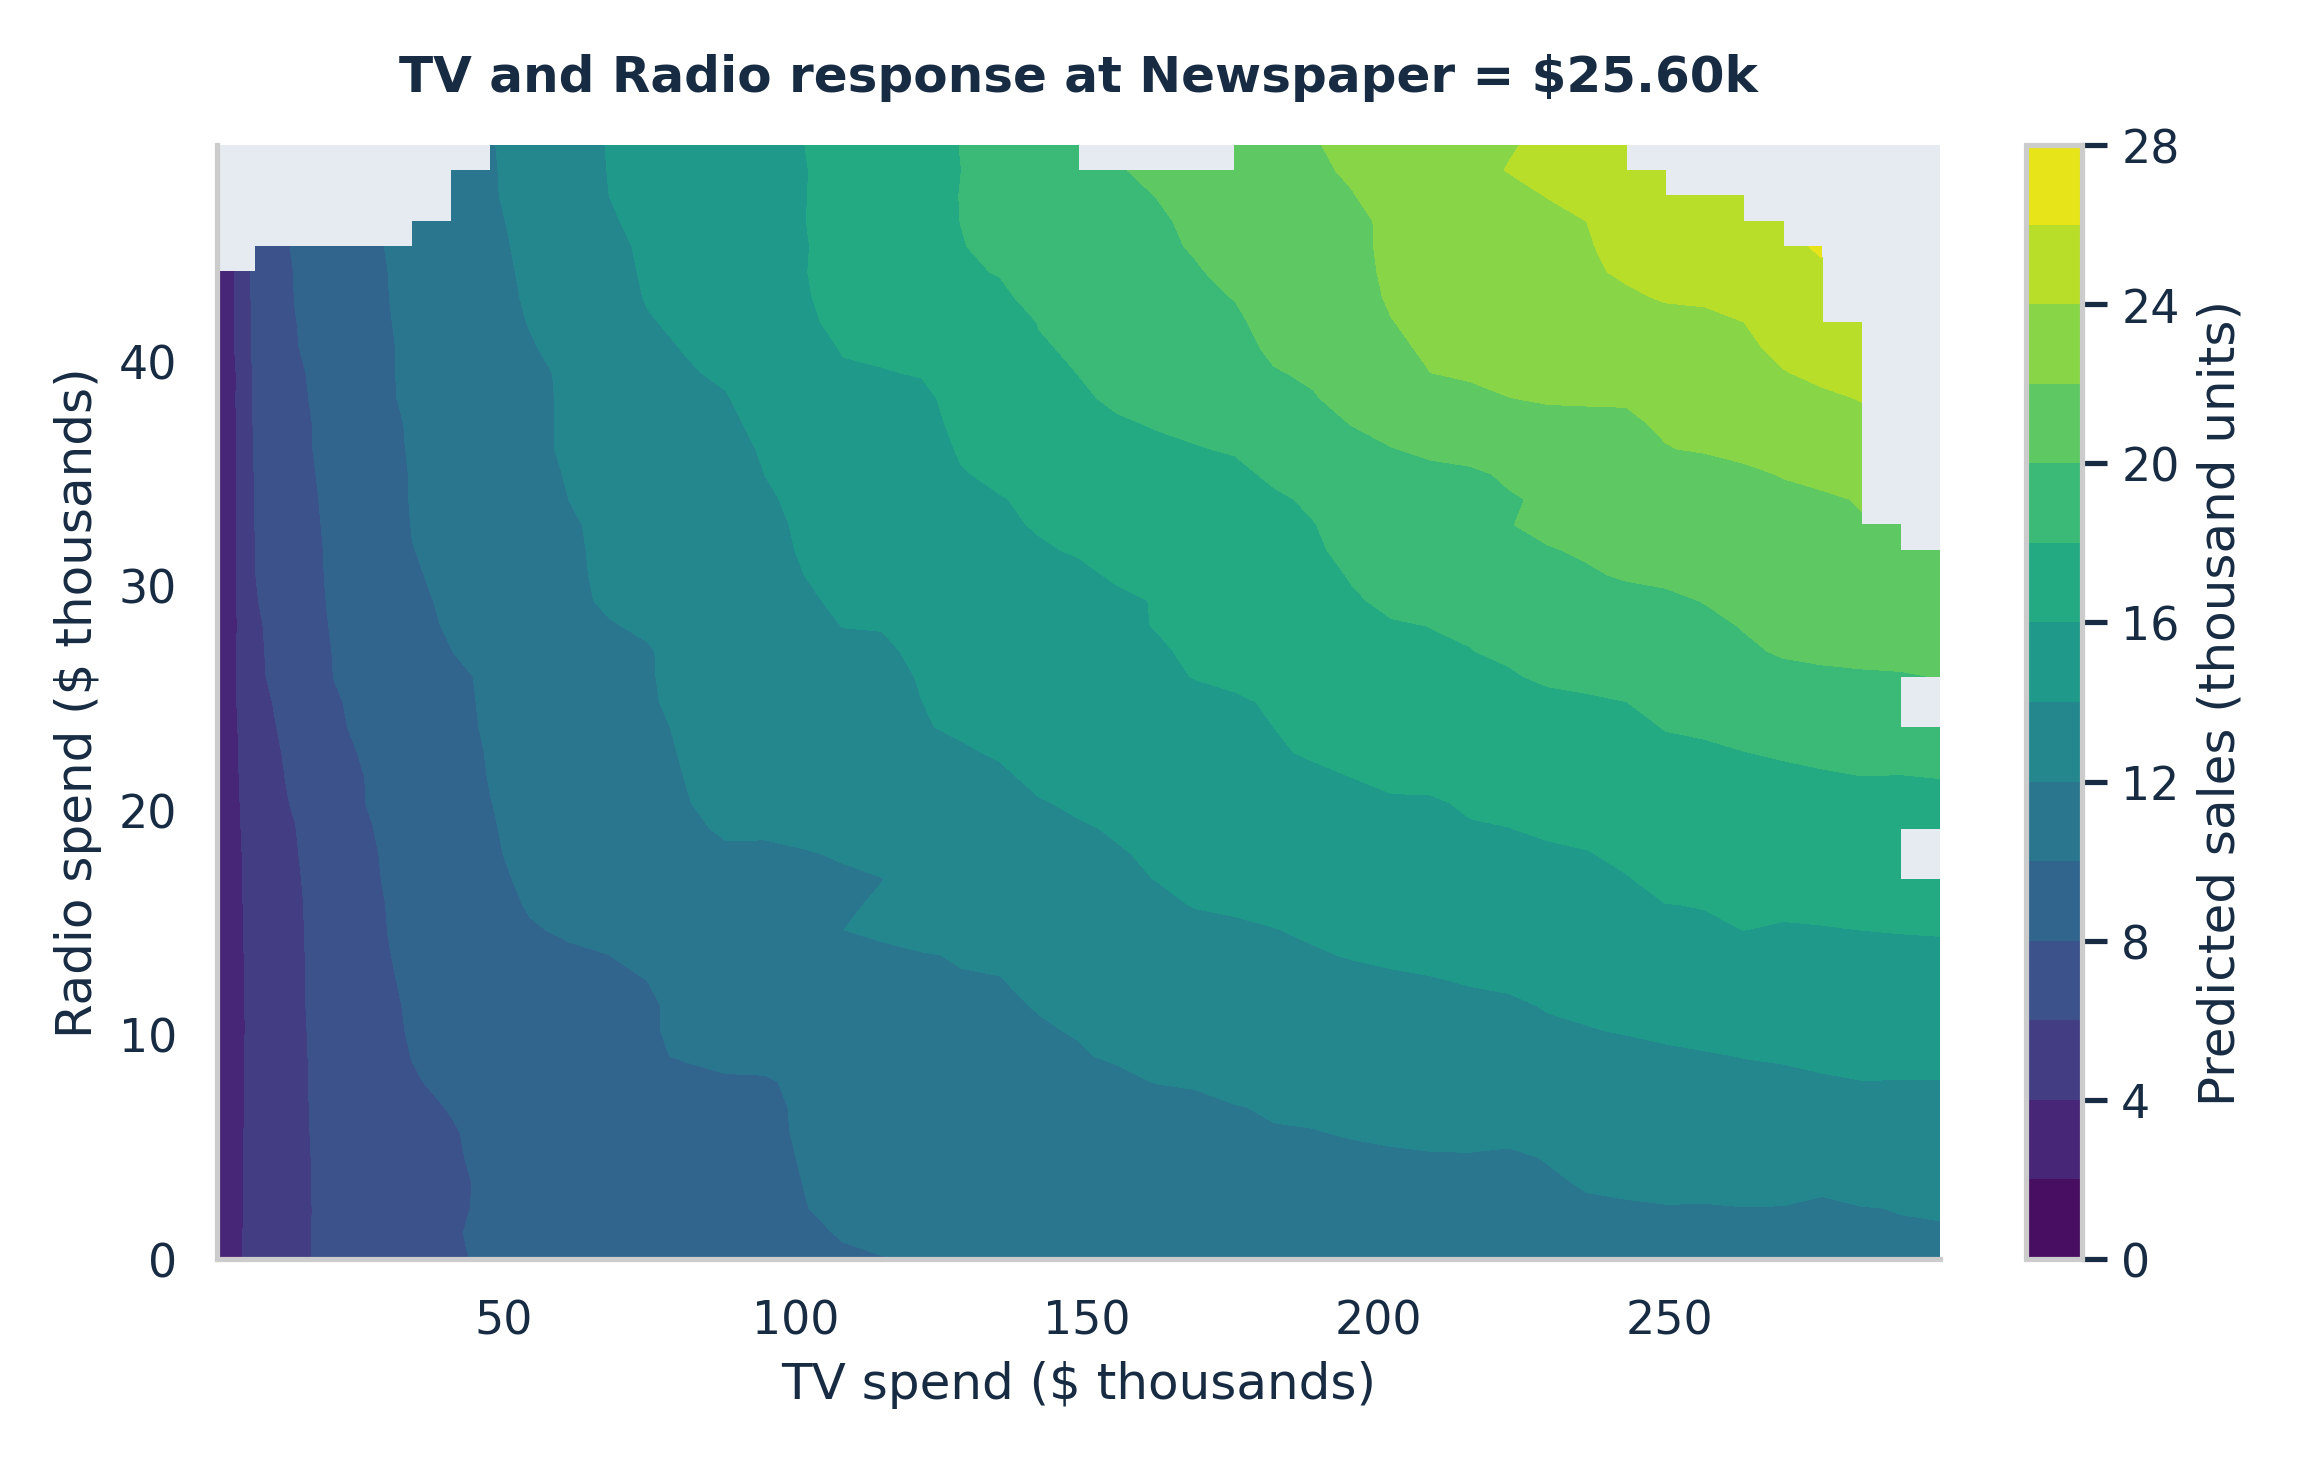

Newspaper is fixed at the training median ($25.60 thousand). Gray indicates sparse combinations. 96.1% of grid points meet the training support rule.

In [10]:
reference = budget_reference(X_train, clean[CHANNELS])
scenarios = sample_scenarios(saved, reference)
grid = response_grid(saved, reference)
display(scenarios[['Scenario', *CHANNELS, 'Total', 'Predicted_Sales', 'Sales_Change',
                   'Inside_Training_Range', 'Training_Mix_Supported']].round(3))
charts('budget_scenarios', 'budget_combinations', 'tv_radio_response_surface')

## 10. Business recommendations and limitations
The model and OLS analysis provide evidence about conditional relationships. A market-level experiment can test whether proposed changes produce incremental sales.

In [11]:
findings = summarize(data, comparison, quality, coefficients, importance, diagnostics, scenarios, grid)
display(Markdown('### Marketing recommendations\n' + '\n'.join(f'- {item}' for item in findings['recommendations'])))
display(Markdown('### Limitations\n' + '\n'.join(f'- {item}' for item in findings['limitations'])))

### Marketing recommendations
- Prioritize TV in controlled budget tests and vary TV and Radio jointly. The interaction model reduced validation error relative to the additive model.
- Audit Newspaper against reach, cost and campaign objectives. The selected model uses TV, Radio, so varying Newspaper alone leaves its predictions unchanged.
- At the same total budget, the scenario “Move 20% of Newspaper to Radio” yields a predicted gain of 0.99 thousand units. Pilot the reallocation while tracking incremental sales.
- Among the tested spend increases, TV +20% produces the largest supported gain (+0.97 thousand units). Compare the cost and incremental sales in a controlled test.
- Capture campaign dates, prices, promotions and audience segments so future models can test seasonality and segment response.

### Limitations
- The file covers 200 historical markets and has no calendar or segment identifiers. Estimates apply to budget scenarios for comparable markets.
- Market-level associations can reflect omitted variables such as pricing, promotions or market size. Use randomized tests to estimate incremental effects.
- Scenario predictions are point estimates. The range and nearest-neighbor flags measure coverage of the training data and provide no prediction interval.
- Repeated CV folds overlap, and tuning and ranking share those folds. The holdout provides the final evaluation and contains only 40 markets.

## 11. Conclusion
Budget allocations provide a strong predictive signal in the held-out sample. Model comparison supports a flexible TV and Radio relationship. The saved pipeline, coverage checks and dashboard make the analysis reproducible and give marketing teams a way to compare testable proposals.